dm_catlas_strpal_43k_16_topics_2025-08-07_03-18-38

  screen: None
  
  model: deepmsn_20
  
  dropout=0.5, CNN x 1 + Transformer x 2 with 8 heads
  
  dataset: Catlas_ATAC_STR-PAL_2025-08-04_43k_16_Topics_top_3k, online augmentation, multiplier = 3, rc_prob=0.0
  
  lr_init: 1e-4
  
  decay_rate:0.333
  
  weight_decay:5e-2
  
  batch_size: 16
  
  loss_fn: FocalLoss() α=1.0, γ=2.0

In [1]:
import os
import yaml
import json

os.chdir('/home/ray/DeepPallidum/')

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc, precision_recall_curve, f1_score, confusion_matrix

In [3]:
config_path = 'checkpoints/dp_catlas_strpal_49k_12_reduced_11_topics_2026-02-08_06-48-43/config.yaml'
with open(config_path, 'r') as f:
    config = yaml.safe_load(f)

checkpoint_path = config.get('train').get('checkpoint').get('path')
checkpoint_path

'checkpoints/dp_catlas_strpal_49k_12_reduced_11_topics_2026-02-08_06-48-43'

## Selected per-label thresholds

Set the threshold for each output label/topic here.
These thresholds should come from validation tuning in [checkpoint_selection.ipynb](/home/ray/DeepPallidum/notebooks/checkpoint_selection.ipynb).


In [ ]:
from sklearn.metrics import average_precision_score, f1_score

# Replace these defaults with your tuned per-label thresholds
# Example below assumes 11 output labels/topics.
selected_label_thresholds = np.array([
    0.50, 0.50, 0.50, 0.50, 0.50,
    0.50, 0.50, 0.50, 0.50, 0.50,
    0.50,
], dtype=float)

if 'config' in globals():
    expected_labels = len(config['dataset']['data_path'])
    if selected_label_thresholds.size != expected_labels:
        raise ValueError(
            f'selected_label_thresholds has {selected_label_thresholds.size} values, '
            f'but config expects {expected_labels} labels.'
        )

def evaluate_with_thresholds(y_true, y_prob, thresholds):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    thresholds = np.asarray(thresholds).reshape(1, -1)

    if y_true.shape != y_prob.shape:
        raise ValueError(f'y_true shape {y_true.shape} != y_prob shape {y_prob.shape}')
    if y_true.shape[1] != thresholds.shape[1]:
        raise ValueError(
            f'Threshold count {thresholds.shape[1]} must match label count {y_true.shape[1]}'
        )

    y_pred = (y_prob >= thresholds).astype(int)

    metrics = {
        'micro_f1': f1_score(y_true, y_pred, average='micro', zero_division=0),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'samples_f1': f1_score(y_true, y_pred, average='samples', zero_division=0),
    }

    pr_auc_per_label = []
    for j in range(y_true.shape[1]):
        yj = y_true[:, j]
        if np.unique(yj).size < 2:
            pr_auc_per_label.append(np.nan)
            continue
        pr_auc_per_label.append(average_precision_score(yj, y_prob[:, j]))

    metrics['macro_pr_auc'] = float(np.nanmean(pr_auc_per_label))
    return metrics, np.array(pr_auc_per_label), y_pred

# Example usage once val/test arrays are available:
# val_metrics, val_pr_auc_per_label, val_pred = evaluate_with_thresholds(
#     val_targets, val_probs, selected_label_thresholds
# )
# test_metrics, test_pr_auc_per_label, test_pred = evaluate_with_thresholds(
#     test_targets, test_probs, selected_label_thresholds
# )
# print('Validation metrics:', val_metrics)
# print('Test metrics:', test_metrics)


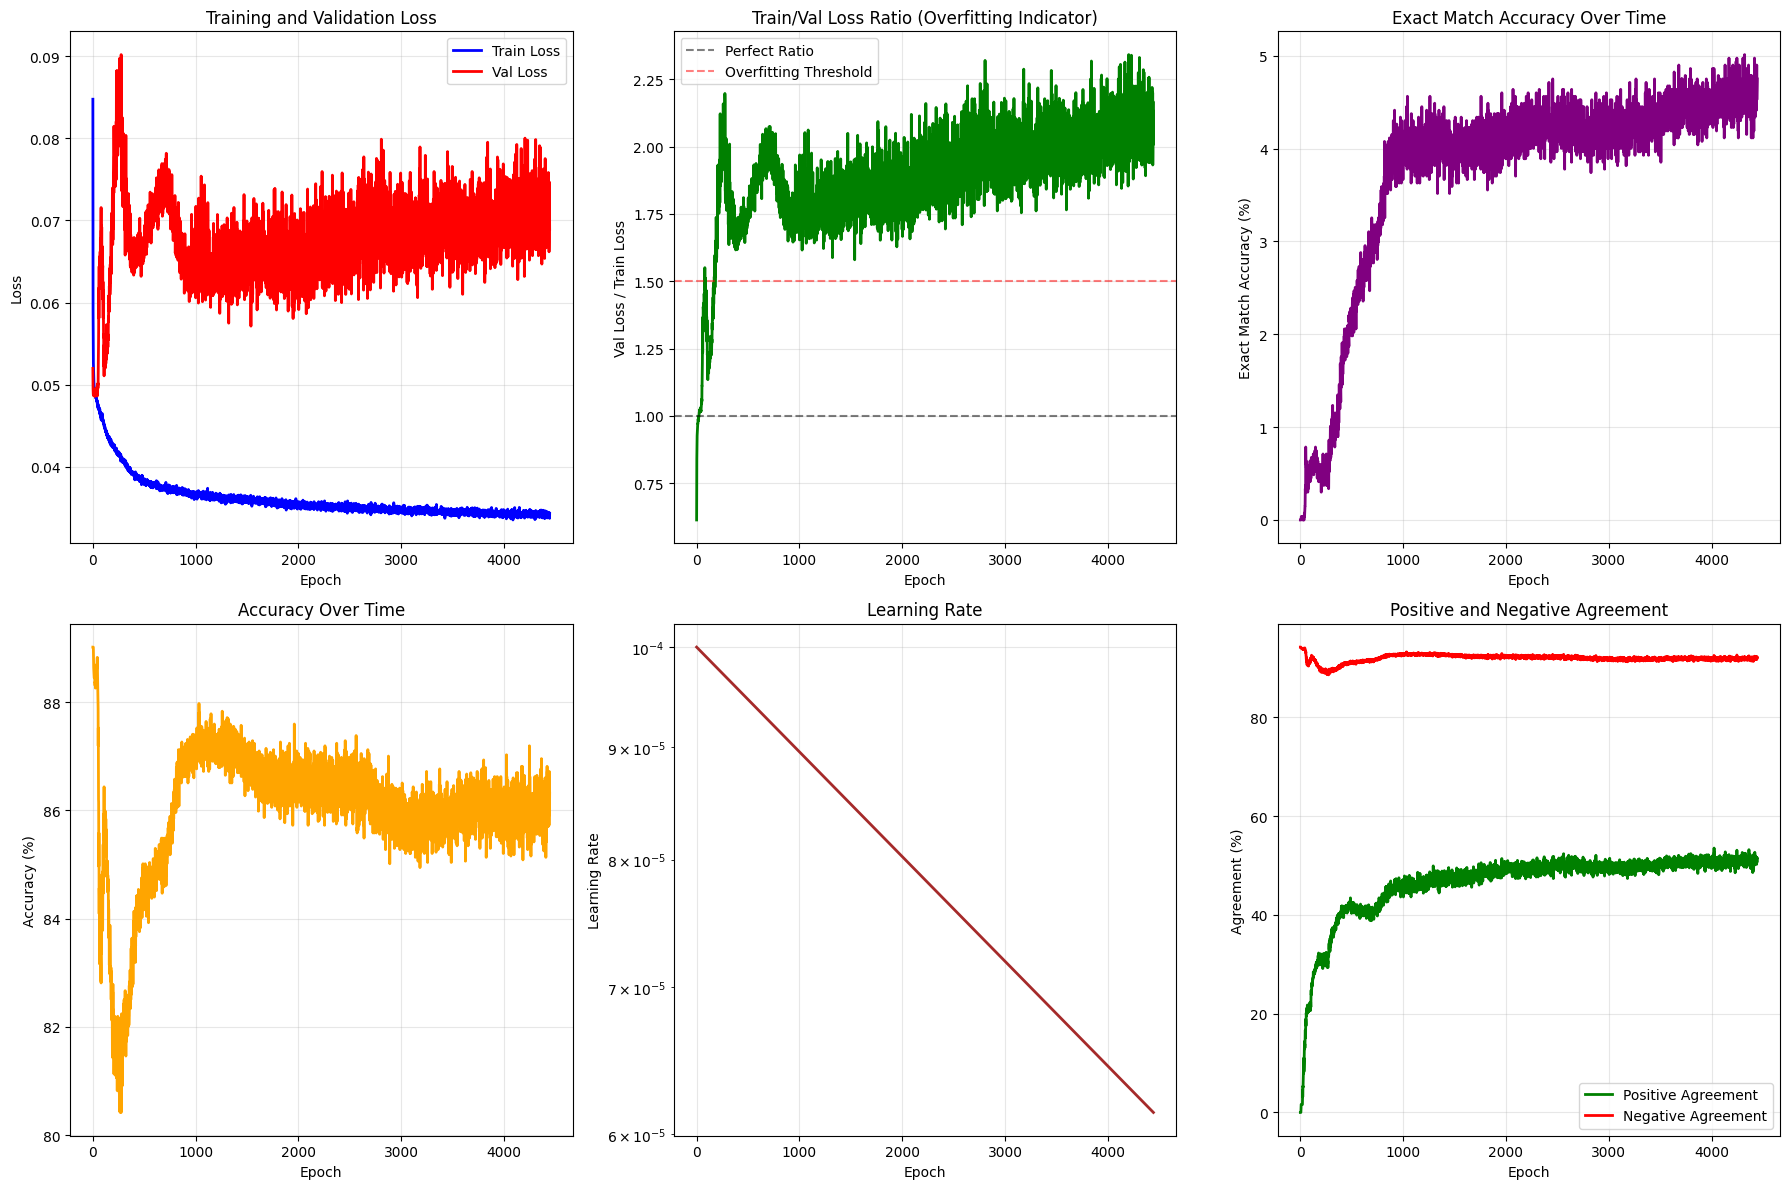

Training Summary:
Initial Train Loss: 0.084765
Final Train Loss: 0.034302
Initial Val Loss: 0.051973
Final Val Loss: 0.068951
Best Val Loss: 0.048587 (Epoch 19)
Best Exact Match Acc: 0.0501 (Epoch 4321)
Best Acc: 0.8902 (Epoch 1)
Final Train/Val Ratio: 2.010


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the training log
training_df = pd.read_csv(f'{checkpoint_path}/training_log.csv')

# Create comprehensive training plots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Training and Validation Loss
axes[0, 0].plot(training_df['epoch'], training_df['train_loss'], 'b-', label='Train Loss', linewidth=2)
axes[0, 0].plot(training_df['epoch'], training_df['val_loss'], 'r-', label='Val Loss', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Training and Validation Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Train/Val Loss Ratio (Overfitting indicator)
axes[0, 1].plot(training_df['epoch'], training_df['train_val_ratio'], 'g-', linewidth=2)
axes[0, 1].axhline(y=1.0, color='k', linestyle='--', alpha=0.5, label='Perfect Ratio')
axes[0, 1].axhline(y=1.5, color='r', linestyle='--', alpha=0.5, label='Overfitting Threshold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Val Loss / Train Loss')
axes[0, 1].set_title('Train/Val Loss Ratio (Overfitting Indicator)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Exact Match Accuracy
axes[0, 2].plot(training_df['epoch'], training_df['exact_match_acc'] * 100, 'purple', linewidth=2)
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('Exact Match Accuracy (%)')
axes[0, 2].set_title('Exact Match Accuracy Over Time')
axes[0, 2].grid(True, alpha=0.3)

# 4. Accuracy
axes[1, 0].plot(training_df['epoch'], training_df['hamming_acc'] * 100, 'orange', linewidth=2)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy (%)')
axes[1, 0].set_title('Accuracy Over Time')
axes[1, 0].grid(True, alpha=0.3)

# 5. Learning Rate
axes[1, 1].plot(training_df['epoch'], training_df['learning_rate'], 'brown', linewidth=2)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Learning Rate')
axes[1, 1].set_title('Learning Rate')
axes[1, 1].set_yscale('log')
axes[1, 1].grid(True, alpha=0.3)

# 6. Positive and Negative Agreement
axes[1, 2].plot(training_df['epoch'], training_df['positive_agreement'] * 100, 
                'g-', label='Positive Agreement', linewidth=2)
axes[1, 2].plot(training_df['epoch'], training_df['negative_agreement'] * 100, 
                'r-', label='Negative Agreement', linewidth=2)
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Agreement (%)')
axes[1, 2].set_title('Positive and Negative Agreement')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print("Training Summary:")
print(f"Initial Train Loss: {training_df['train_loss'].iloc[0]:.6f}")
print(f"Final Train Loss: {training_df['train_loss'].iloc[-1]:.6f}")
print(f"Initial Val Loss: {training_df['val_loss'].iloc[0]:.6f}")
print(f"Final Val Loss: {training_df['val_loss'].iloc[-1]:.6f}")
print(f"Best Val Loss: {training_df['val_loss'].min():.6f} (Epoch {training_df.loc[training_df['val_loss'].idxmin(), 'epoch']})")
print(f"Best Exact Match Acc: {training_df['exact_match_acc'].max():.4f} (Epoch {training_df.loc[training_df['exact_match_acc'].idxmax(), 'epoch']})")
print(f"Best Acc: {training_df['hamming_acc'].max():.4f} (Epoch {training_df.loc[training_df['hamming_acc'].idxmax(), 'epoch']})")
print(f"Final Train/Val Ratio: {training_df['train_val_ratio'].iloc[-1]:.3f}")

# Print agreement statistics if available
if 'pos_agreement' in training_df.columns and 'neg_agreement' in training_df.columns:
    print(f"Best Positive Agreement: {training_df['pos_agreement'].max():.4f} (Epoch {training_df.loc[training_df['pos_agreement'].idxmax(), 'epoch']})")
    print(f"Best Negative Agreement: {training_df['neg_agreement'].max():.4f} (Epoch {training_df.loc[training_df['neg_agreement'].idxmax(), 'epoch']})")
    print(f"Final Positive Agreement: {training_df['pos_agreement'].iloc[-1]:.4f}")
    print(f"Final Negative Agreement: {training_df['neg_agreement'].iloc[-1]:.4f}")

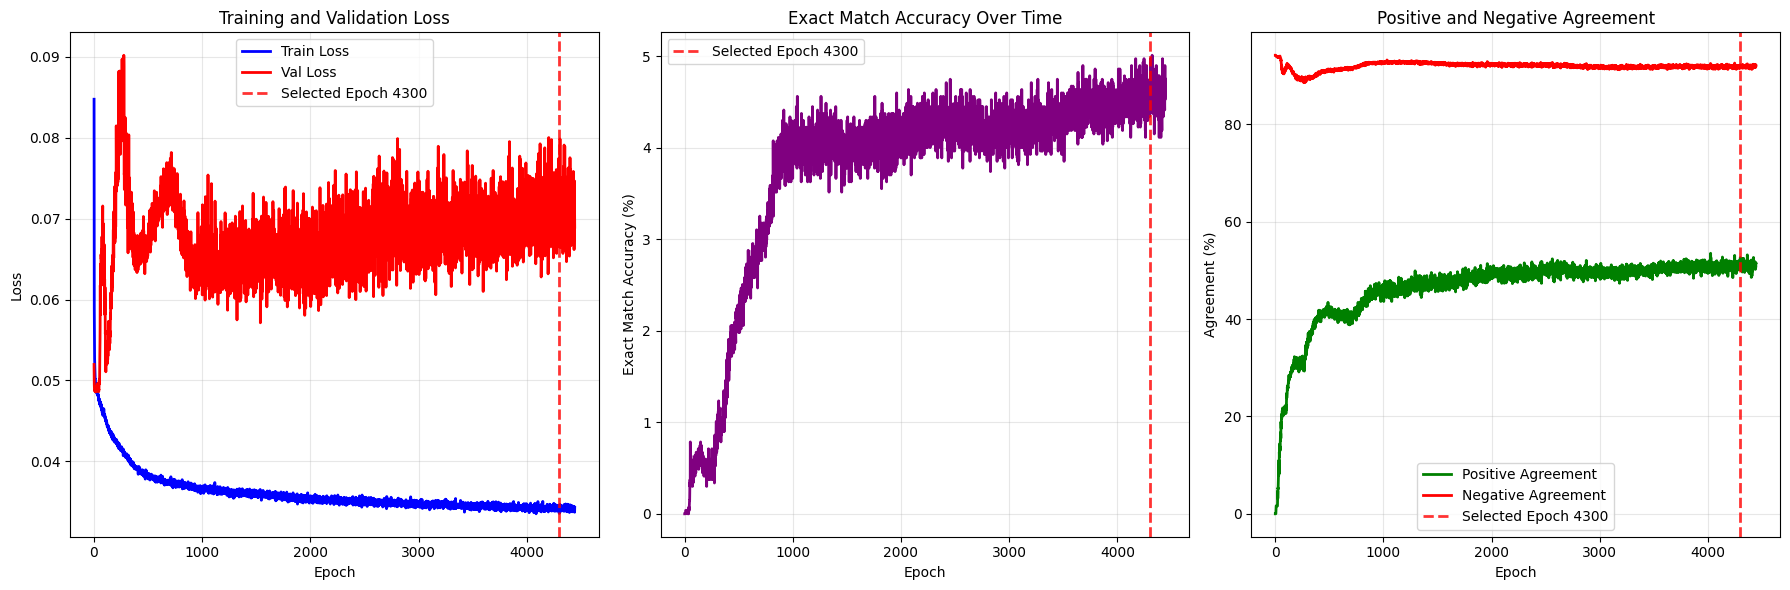

In [6]:
epoch_use = 4300

# Create comprehensive training plots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Training and Validation Loss
axes[0].plot(training_df['epoch'], training_df['train_loss'], 'b-', label='Train Loss', linewidth=2)
axes[0].plot(training_df['epoch'], training_df['val_loss'], 'r-', label='Val Loss', linewidth=2)
# Add vertical line for selected epoch
axes[0].axvline(x=epoch_use, color='red', linestyle='--', linewidth=2, alpha=0.8, label=f'Selected Epoch {epoch_use}')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Exact Match Accuracy
axes[1].plot(training_df['epoch'], training_df['exact_match_acc'] * 100, 'purple', linewidth=2)
# Add vertical line for selected epoch
axes[1].axvline(x=epoch_use, color='red', linestyle='--', linewidth=2, alpha=0.8, label=f'Selected Epoch {epoch_use}')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Exact Match Accuracy (%)')
axes[1].set_title('Exact Match Accuracy Over Time')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# 3. Positive and Negative Agreement
axes[2].plot(training_df['epoch'], training_df['positive_agreement'] * 100, 
             'g-', label='Positive Agreement', linewidth=2)
axes[2].plot(training_df['epoch'], training_df['negative_agreement'] * 100, 
             'r-', label='Negative Agreement', linewidth=2)
# Add vertical line for selected epoch
axes[2].axvline(x=epoch_use, color='red', linestyle='--', linewidth=2, alpha=0.8, label=f'Selected Epoch {epoch_use}')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Agreement (%)')
axes[2].set_title('Positive and Negative Agreement')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# Print training stats at the selected epoch
print("="*60)
print(f"TRAINING STATISTICS AT EPOCH {epoch_use}")
print("="*60)

# Find the row for the selected epoch
selected_row = training_df[training_df['epoch'] == epoch_use]

if not selected_row.empty:
    row = selected_row.iloc[0]
    
    print(f"📊 Loss Metrics:")
    print(f"  Train Loss:           {row['train_loss']:.6f}")
    print(f"  Validation Loss:      {row['val_loss']:.6f}")
    print(f"  Train/Val Ratio:      {row['train_val_ratio']:.3f}")
    
    print(f"\n🎯 Accuracy Metrics:")
    print(f"  Exact Match Acc:      {row['exact_match_acc']:.4f} ({row['exact_match_acc']*100:.2f}%)")
    print(f"  Hamming Accuracy:     {row['hamming_acc']:.4f} ({row['hamming_acc']*100:.2f}%)")
    
    print(f"\n🤝 Agreement Metrics:")
    print(f"  Positive Agreement:   {row['positive_agreement']:.4f} ({row['positive_agreement']*100:.2f}%)")
    print(f"  Negative Agreement:   {row['negative_agreement']:.4f} ({row['negative_agreement']*100:.2f}%)")
    
    print(f"\n⚙️ Training Settings:")
    print(f"  Learning Rate:        {row['learning_rate']:.2e}")
    
    # Compare with best values
    best_val_loss = training_df['val_loss'].min()
    best_val_epoch = training_df.loc[training_df['val_loss'].idxmin(), 'epoch']
    best_exact_acc = training_df['exact_match_acc'].max()
    best_exact_epoch = training_df.loc[training_df['exact_match_acc'].idxmax(), 'epoch']
    
    print(f"\n📈 Comparison with Best:")
    print(f"  Best Val Loss:        {best_val_loss:.6f} (Epoch {best_val_epoch})")
    print(f"  Current Val Loss:     {row['val_loss']:.6f} {'✅' if row['val_loss'] <= best_val_loss * 1.05 else '⚠️'}")
    print(f"  Best Exact Match:     {best_exact_acc:.4f} (Epoch {best_exact_epoch})")
    print(f"  Current Exact Match:  {row['exact_match_acc']:.4f} {'✅' if row['exact_match_acc'] >= best_exact_acc * 0.95 else '⚠️'}")
    
    # Overfitting assessment
    if row['train_val_ratio'] < 1.2:
        overfitting_status = "✅ Good"
    elif row['train_val_ratio'] < 1.5:
        overfitting_status = "⚠️ Mild overfitting"
    else:
        overfitting_status = "❌ Significant overfitting"
    
    print(f"\n🔍 Model Health:")
    print(f"  Overfitting Status:   {overfitting_status}")
    print(f"  Train/Val Ratio:      {row['train_val_ratio']:.3f}")
    
else:
    print(f"❌ Epoch {epoch_use} not found in training log!")
    print(f"Available epochs: {training_df['epoch'].min()} to {training_df['epoch'].max()}")

print("="*60)

TRAINING STATISTICS AT EPOCH 4300
📊 Loss Metrics:
  Train Loss:           0.033556
  Validation Loss:      0.075815
  Train/Val Ratio:      2.259

🎯 Accuracy Metrics:
  Exact Match Acc:      0.0460 (4.60%)
  Hamming Accuracy:     0.8613 (86.13%)

🤝 Agreement Metrics:
  Positive Agreement:   0.5059 (50.59%)
  Negative Agreement:   0.9193 (91.93%)

⚙️ Training Settings:
  Learning Rate:        6.23e-05

📈 Comparison with Best:
  Best Val Loss:        0.048587 (Epoch 19)
  Current Val Loss:     0.075815 ⚠️
  Best Exact Match:     0.0501 (Epoch 4321)
  Current Exact Match:  0.0460 ⚠️

🔍 Model Health:
  Overfitting Status:   ❌ Significant overfitting
  Train/Val Ratio:      2.259


In [11]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from datasets.topic_datasets import TopicDataset

device = torch.device(f'cuda:0')
print(f"Using {device} device")

Using cuda:0 device


In [12]:
# Determine model used
model_arch = config.get('train').get('model')

from models.deepmsn import DeepMSN
ModelClass = DeepMSN

In [13]:
from safetensors.torch import load_file

def load_model_from_safetensors(checkpoint_path, config_path):
    """Load model from Accelerate-saved SafeTensors format"""
    
    # Load config
    with open(config_path, 'r') as f:
        config = yaml.safe_load(f)
    
    # Initialize model
    model = DeepMSN(config=config)
    
    # Load from SafeTensors
    safetensors_path = os.path.join(checkpoint_path, 'model.safetensors')
    
    if os.path.exists(safetensors_path):
        # Load the state dict from SafeTensors
        state_dict = load_file(safetensors_path)
        model.load_state_dict(state_dict)
        print(f"Loaded model from {safetensors_path}")
    else:
        raise FileNotFoundError(f"SafeTensors file not found at {safetensors_path}")
    
    # Set to eval mode and move to device
    model.eval()
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    
    return model, config

# Usage:
model_checkpoint_path = os.path.join(checkpoint_path, f'checkpoint_epoch_{epoch_use}')
model, config = load_model_from_safetensors(model_checkpoint_path, config_path)

Loaded model from checkpoints/dp_catlas_strpal_49k_12_reduced_11_topics_2026-02-08_06-48-43/checkpoint_epoch_4300/model.safetensors


In [14]:
# Resume dataset and dataloaders from saved bed file
batch_size = 128

# Get train/val/test data split
out_dir = config.get('dataset').get('out_dir')
# out_dir = '/home/ray/DeepMSN/data/PB_CTdnsmpl_catlas_25_Topics_top_3k'
train_file = os.path.join(out_dir, 'regions_and_topics_train.bed')
val_file = os.path.join(out_dir, 'regions_and_topics_val.bed')
test_file = os.path.join(out_dir, 'regions_and_topics_test.bed')
full_file = os.path.join(out_dir, 'regions_and_topics.bed')
split_info_file = os.path.join(out_dir, 'split_info.json')

# Create separate configs for each dataset pointing to the correct bed file
train_config = config.copy()
train_config['dataset'] = config['dataset'].copy()
train_config['dataset']['bed_file'] = train_file
train_config['dataset']['augment'] = False

val_config = config.copy()
val_config['dataset'] = config['dataset'].copy()
val_config['dataset']['bed_file'] = val_file
val_config['dataset']['augment'] = False

test_config = config.copy()
test_config['dataset'] = config['dataset'].copy()
test_config['dataset']['bed_file'] = test_file
test_config['dataset']['augment'] = False

full_config = config.copy()
full_config['dataset'] = config['dataset'].copy()
full_config['dataset']['bed_file'] = full_file
full_config['dataset']['augment'] = False

# Create datasets
train_dataset = TopicDataset(config=train_config)
val_dataset = TopicDataset(config=val_config)
test_dataset = TopicDataset(config=test_config)
full_dataset = TopicDataset(config=full_config)

print(f"Dataset sizes:")
print(f"  Training: {len(train_dataset)}")
print(f"  Validation: {len(val_dataset)}")
print(f"  Test: {len(test_dataset)}")

# Define data loaders
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False, num_workers=1)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=1)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=1)
full_dataloader = DataLoader(full_dataset, batch_size=batch_size, shuffle=False, num_workers=1)

Dataset sizes:
  Training: 21390
  Validation: 2673
  Test: 2675


**Confusion matrix:**
||pred-neg|pred-pos|
|-----|-----|-----|
|neg|tn|fp|
|pos|fn|tp|

## Evaluate model on training dataset

In [15]:
eval_dataset = 'Training Dataset'

In [16]:
# Evaluate model on validation dataset
dataset = train_dataset
dataloader = train_dataloader

model.eval()

loss, correct = 0, 0
all_test_probs = []
all_test_targets = []

with torch.no_grad():
    for batch in dataloader:
        X, y = batch['sequence'], batch['label']
        X, y = X.to(device), y.to(device)
        y = y.float()
        
        pred = model(X)
        prob = torch.sigmoid(pred)
        # loss += loss_fn(pred, y).item()
        
        all_test_probs.append(prob)
        all_test_targets.append(y)
        
        # Exact match accuracy
        pred_binary = (prob > 0.5).float()
        exact_match = ((pred_binary == y).sum(dim=1) == y.shape[1]).float().sum().item()
        correct += exact_match

all_test_probs = torch.cat(all_test_probs, dim=0)
all_test_targets = torch.cat(all_test_targets, dim=0)

# loss /= len(dataloader)
exact_acc = correct / len(dataset)

pred_binary = (all_test_probs > 0.5).float()
hamming_acc = (pred_binary == all_test_targets).float().mean().item()

In [17]:
# Convert PyTorch tensors to numpy for sklearn
y_pred_np = all_test_probs.cpu().numpy()
y_test_np = all_test_targets.cpu().numpy()

print("Prediction min/max:", np.min(y_pred_np), np.max(y_pred_np))
print("Prediction shape:", y_pred_np.shape)
print("Target shape:", y_test_np.shape)

Prediction min/max: 0.0012122039 0.97131515
Prediction shape: (21390, 11)
Target shape: (21390, 11)


In [18]:
from utils.evaluate import evaluate_multilabel_model, calculate_overall_metrics, analyze_topic_difficulty, plot_per_topic_metrics, optimize_thresholds_per_topic

PER-TOPIC EVALUATION RESULTS
Topic        Precision  Recall   F1       AUROC    AUPR     Support  Preds 
--------------------------------------------------------------------------------
Topic_1      0.365      0.753    0.491    0.885    0.560    2417.0   4991  
Topic_2      0.392      0.384    0.388    0.825    0.368    2416.0   2366  
Topic_3      0.443      0.887    0.591    0.951    0.780    2396.0   4792  
Topic_4      0.583      0.737    0.651    0.935    0.726    2376.0   3006  
Topic_5      0.539      0.056    0.102    0.783    0.317    2461.0   256   
Topic_6      0.429      0.639    0.514    0.877    0.514    2422.0   3606  
Topic_7      0.377      0.508    0.433    0.863    0.391    2388.0   3217  
Topic_8      0.522      0.710    0.602    0.922    0.628    2390.0   3254  
Topic_9      0.353      0.854    0.500    0.902    0.571    2417.0   5845  
Topic_10     0.431      0.599    0.501    0.887    0.458    2379.0   3303  
Topic_11     0.395      0.689    0.502    0.890    0.5

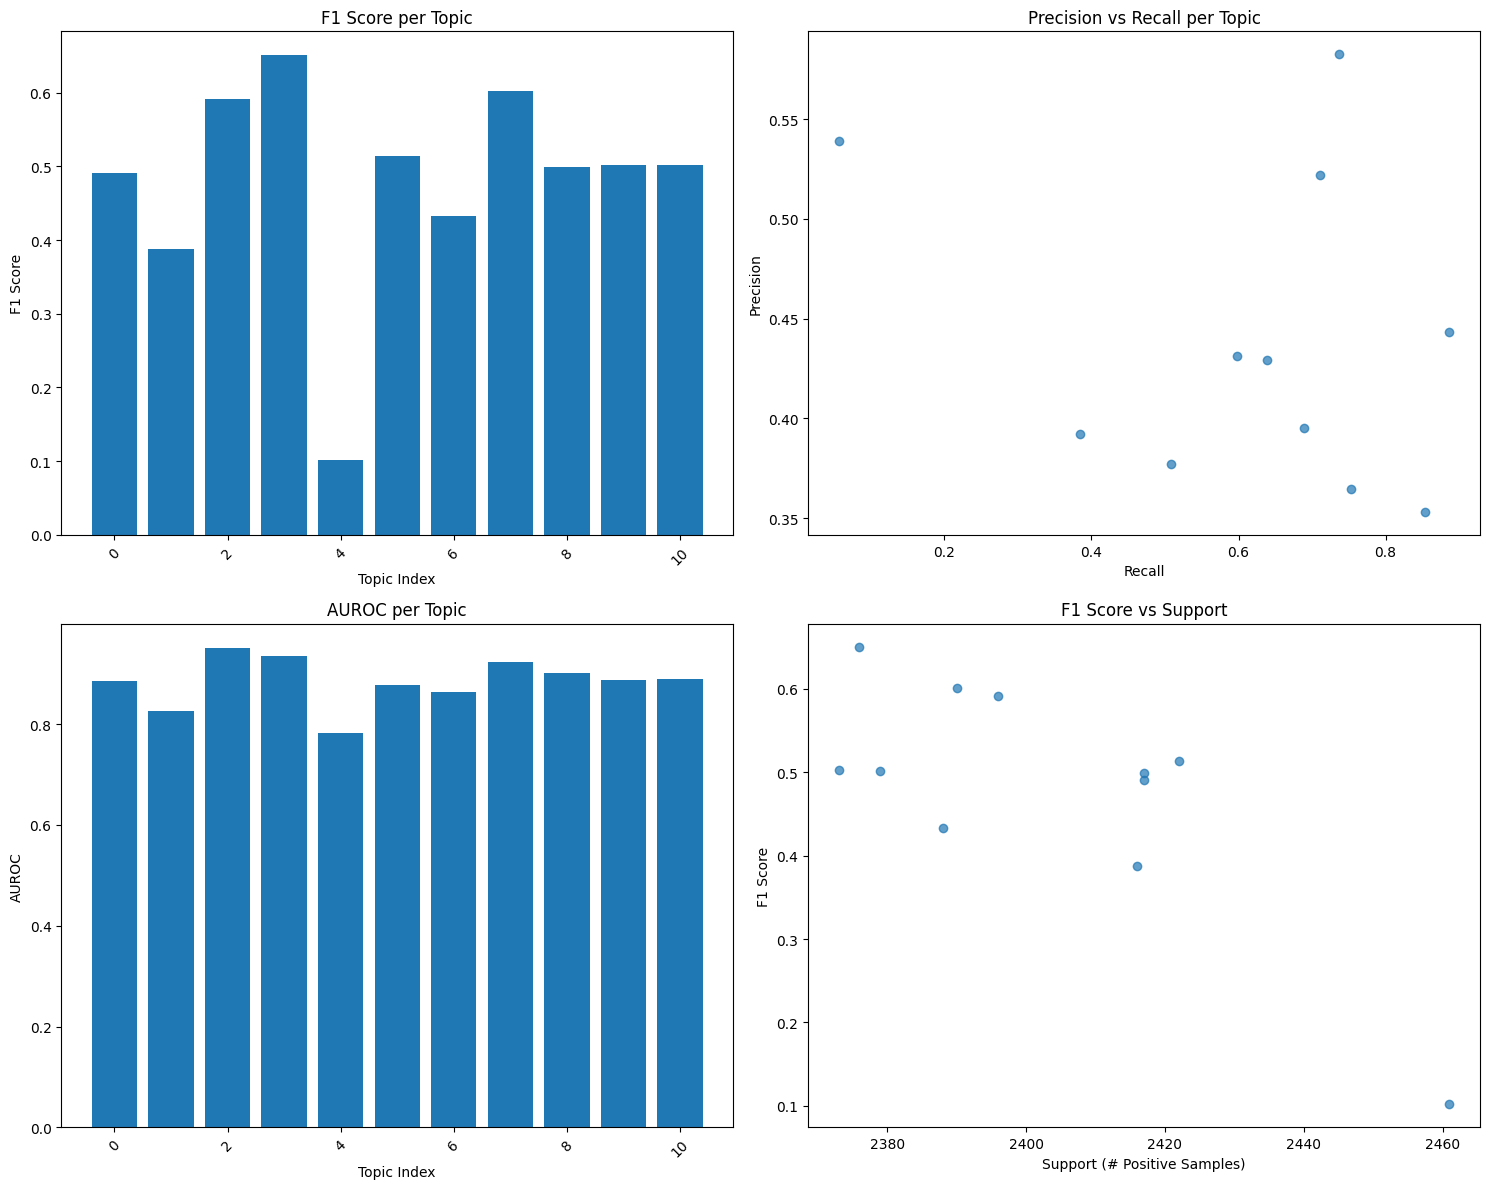


THRESHOLD OPTIMIZATION PER TOPIC
Topic    Best Thresh  Best F1    Precision  Recall  
------------------------------------------------------------
Topic_1   0.65         0.534      0.494      0.580   
Topic_2   0.45         0.419      0.341      0.543   
Topic_3   0.70         0.696      0.712      0.679   
Topic_4   0.60         0.664      0.671      0.656   
Topic_5   0.30         0.377      0.305      0.492   
Topic_6   0.50         0.514      0.429      0.639   
Topic_7   0.40         0.472      0.351      0.719   
Topic_8   0.55         0.612      0.580      0.649   
Topic_9   0.65         0.570      0.494      0.674   
Topic_10  0.50         0.501      0.431      0.599   
Topic_11  0.55         0.510      0.447      0.593   


In [19]:
# 1. Run comprehensive evaluation
results_df = evaluate_multilabel_model(y_test_np, y_pred_np, threshold=0.5)

# 2. Calculate overall metrics
overall_metrics = calculate_overall_metrics(y_test_np, y_pred_np, threshold=0.5)

# 3. Analyze topic difficulty
sorted_results = analyze_topic_difficulty(results_df, n_top=5)

# 4. Plot performance metrics
plot_per_topic_metrics(results_df)

# 5. Optimize thresholds per topic
optimal_thresholds, optimal_f1_scores = optimize_thresholds_per_topic(y_test_np, y_pred_np)

# 6. Save results to CSV
# results_df.to_csv(f'{checkpoint_path}/per_topic_evaluation.csv', index=False)
# print(f"\nResults saved to '{checkpoint_path}/per_topic_evaluation.csv'")

In [21]:
# Apply optimal thresholds for confusion matrices
print("\nConfusion matrices for each topic (with optimal thresholds):")
for i in range(y_test_np.shape[1]):
    # Use the optimal threshold for this specific topic
    optimal_thresh = optimal_thresholds[i]
    y_pred_binary = (y_pred_np[:, i] > optimal_thresh).astype(int)
    
    print(f"\nTopic {i+1} (threshold: {optimal_thresh:.2f}):")
    cm = confusion_matrix(y_test_np[:, i], y_pred_binary)
    print(cm)
    
    # Optional: Calculate and display metrics for this topic
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    print(f"  Precision: {precision:.3f}, Recall: {recall:.3f}, F1: {f1:.3f}")
    print(f"  TP: {tp}, FP: {fp}, FN: {fn}, TN: {tn}")


Confusion matrices for each topic (with optimal thresholds):

Topic 1 (threshold: 0.70):
[[3587   89]
 [ 108  191]]
  Precision: 0.682, Recall: 0.639, F1: 0.660
  TP: 191, FP: 89, FN: 108, TN: 3587

Topic 2 (threshold: 0.80):
[[3529  156]
 [  90  200]]
  Precision: 0.562, Recall: 0.690, F1: 0.619
  TP: 200, FP: 156, FN: 90, TN: 3529

Topic 3 (threshold: 0.55):
[[3541  111]
 [  89  234]]
  Precision: 0.678, Recall: 0.724, F1: 0.701
  TP: 234, FP: 111, FN: 89, TN: 3541

Topic 4 (threshold: 0.30):
[[3362  302]
 [ 128  183]]
  Precision: 0.377, Recall: 0.588, F1: 0.460
  TP: 183, FP: 302, FN: 128, TN: 3362

Topic 5 (threshold: 0.45):
[[3523  189]
 [ 154  109]]
  Precision: 0.366, Recall: 0.414, F1: 0.389
  TP: 109, FP: 189, FN: 154, TN: 3523

Topic 6 (threshold: 0.75):
[[3526  175]
 [ 117  157]]
  Precision: 0.473, Recall: 0.573, F1: 0.518
  TP: 157, FP: 175, FN: 117, TN: 3526

Topic 7 (threshold: 0.60):
[[3410  282]
 [ 145  138]]
  Precision: 0.329, Recall: 0.488, F1: 0.393
  TP: 138, FP


Evaluating 16 topics...
Evaluating topic 1
Topic 1 - auROC: 0.9442, auPR: 0.7022, F1: 0.6365


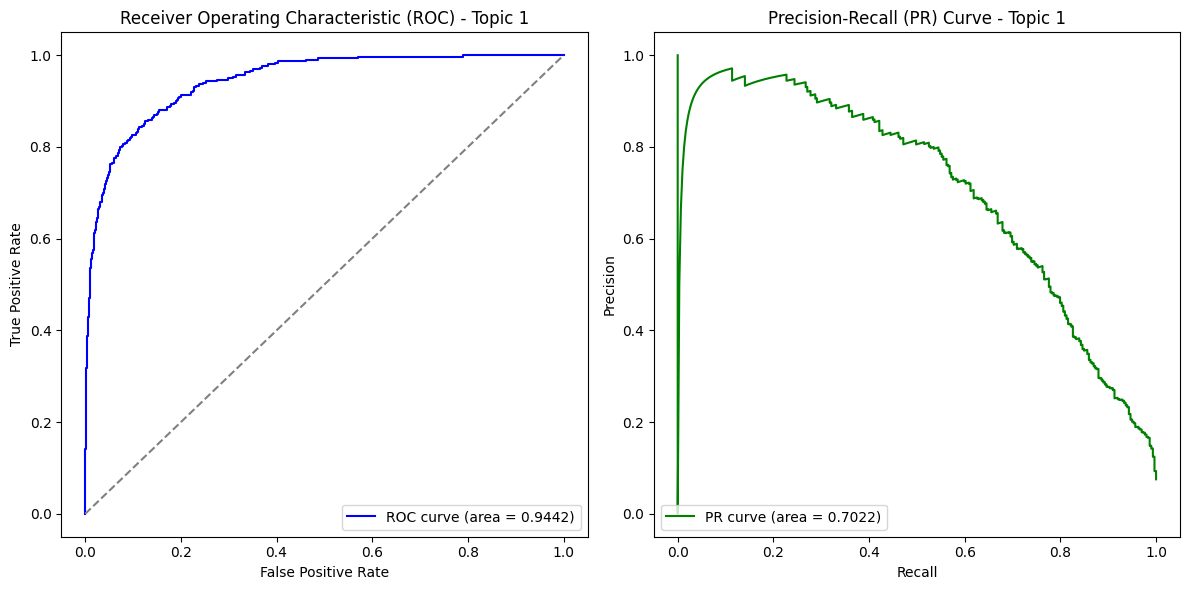

Evaluating topic 2
Topic 2 - auROC: 0.9389, auPR: 0.6414, F1: 0.5314


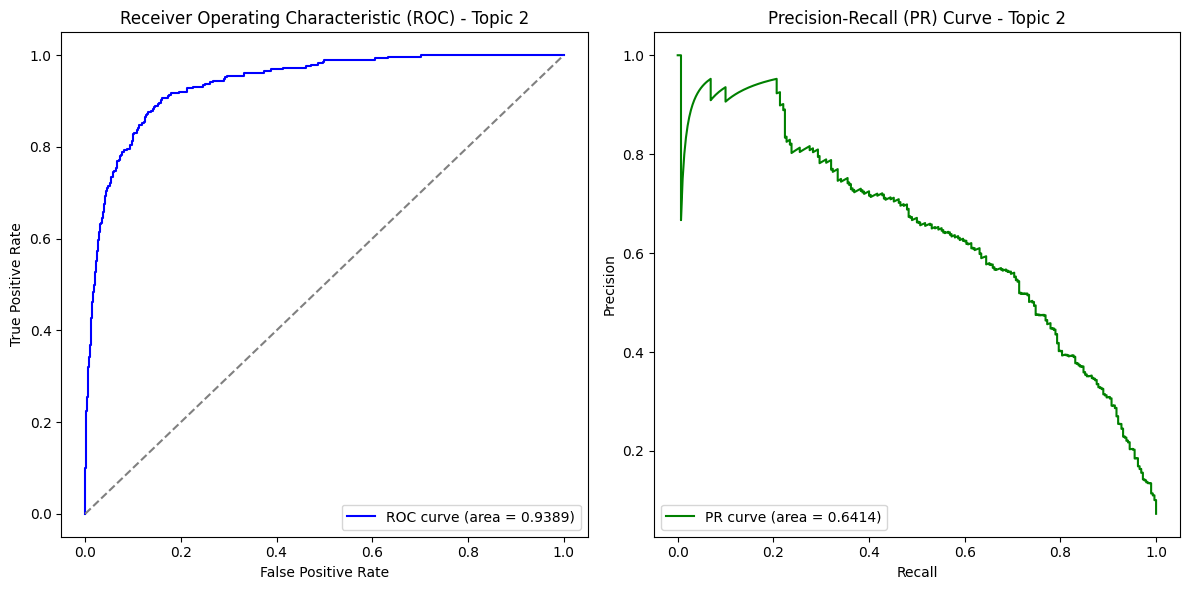

Evaluating topic 3
Topic 3 - auROC: 0.9684, auPR: 0.7639, F1: 0.6954


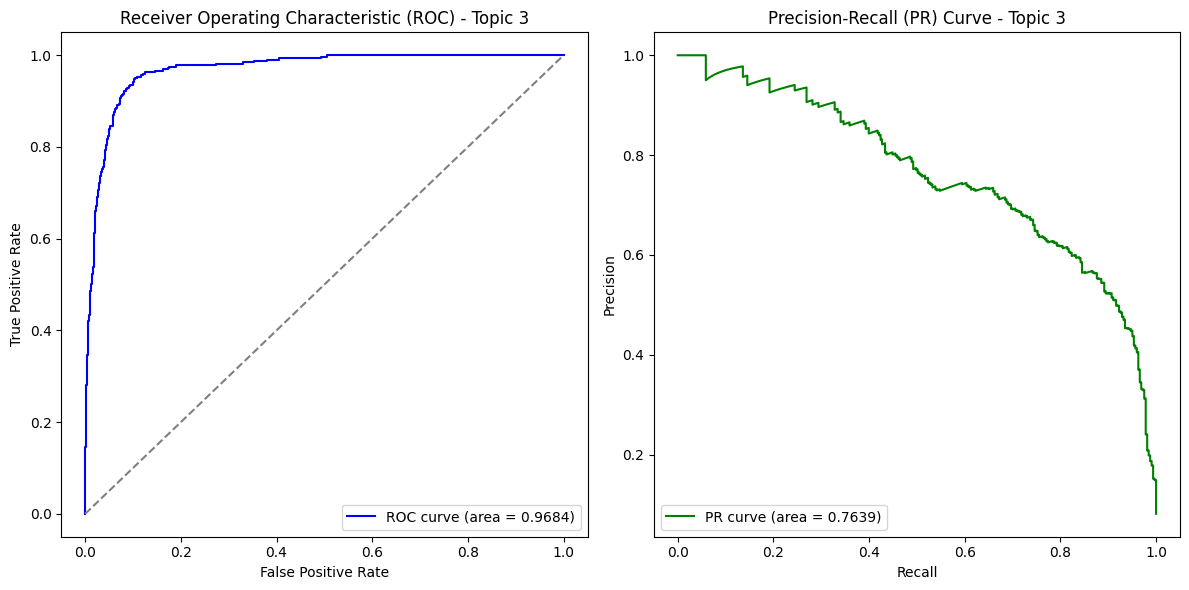

Evaluating topic 4
Topic 4 - auROC: 0.8849, auPR: 0.4594, F1: 0.4105


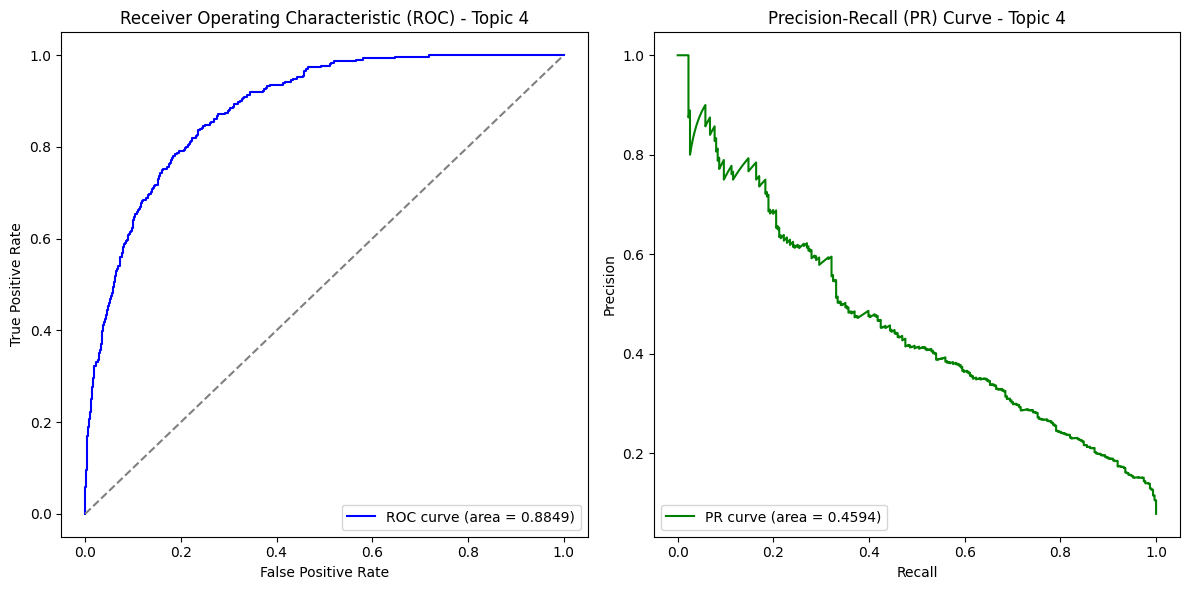

Evaluating topic 5
Topic 5 - auROC: 0.8460, auPR: 0.3364, F1: 0.3819


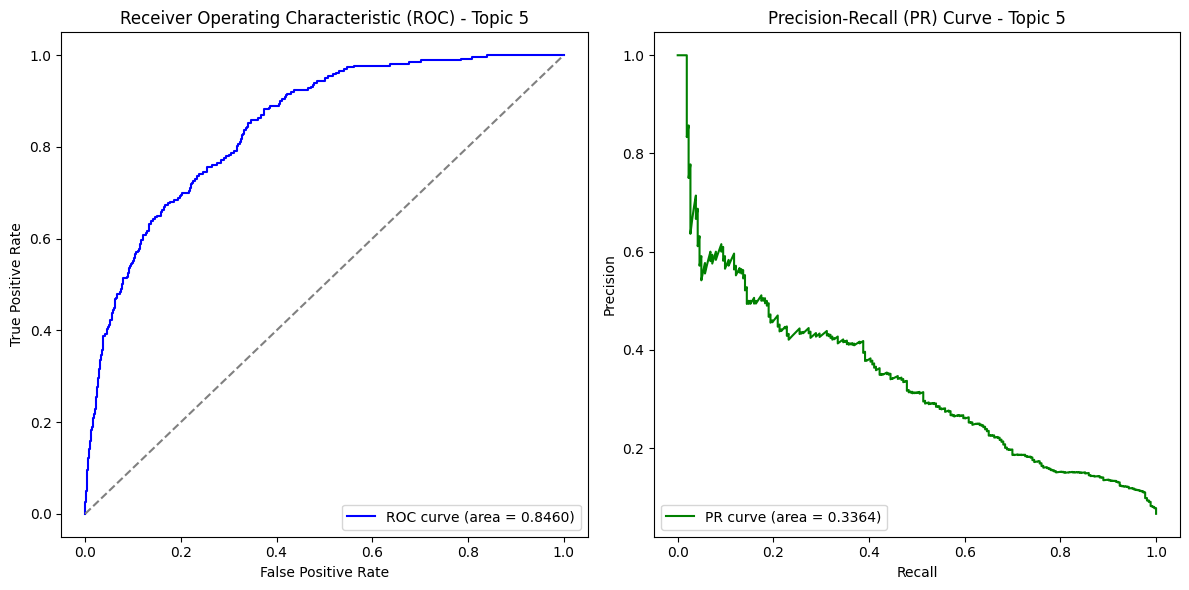

Evaluating topic 6
Topic 6 - auROC: 0.8972, auPR: 0.5278, F1: 0.4181


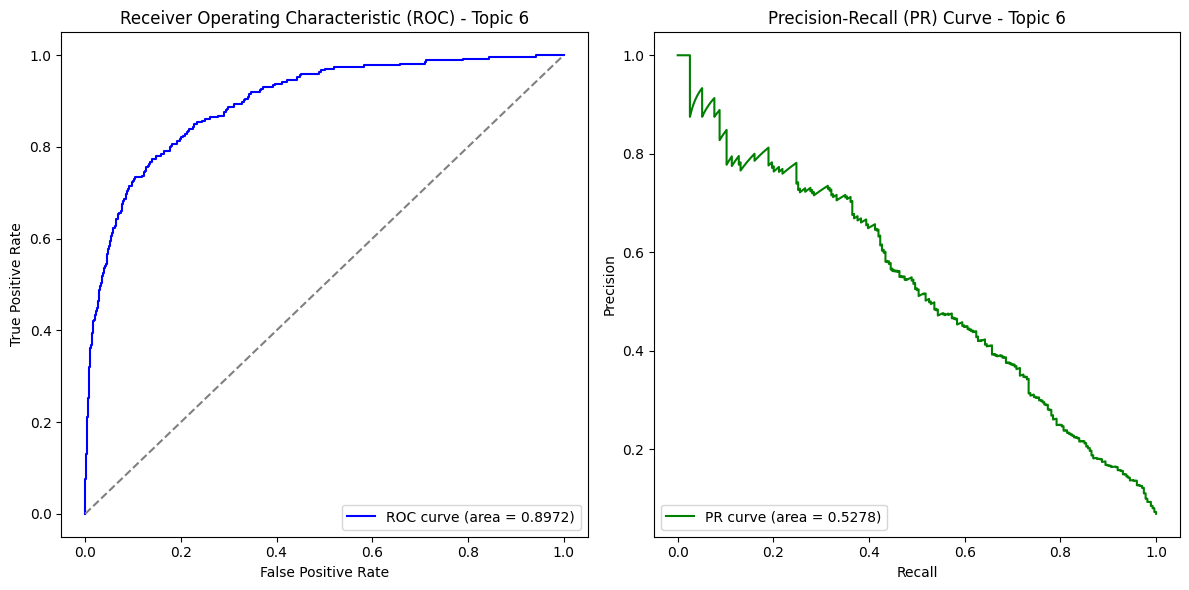

Evaluating topic 7
Topic 7 - auROC: 0.8386, auPR: 0.3235, F1: 0.3570


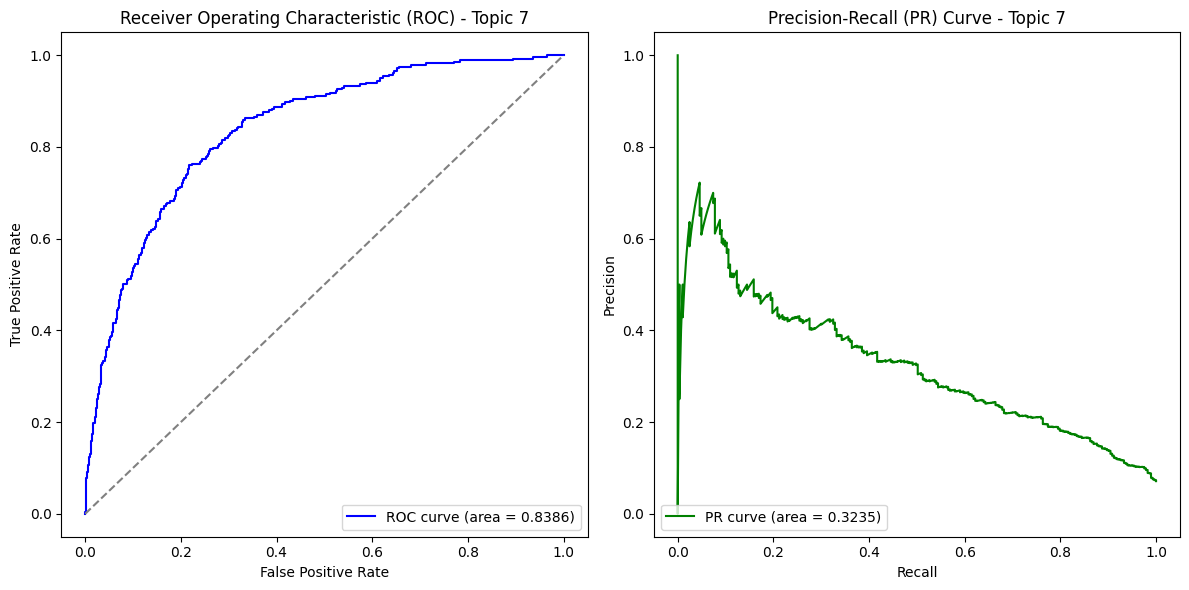

Evaluating topic 8
Topic 8 - auROC: 0.8807, auPR: 0.3791, F1: 0.4144


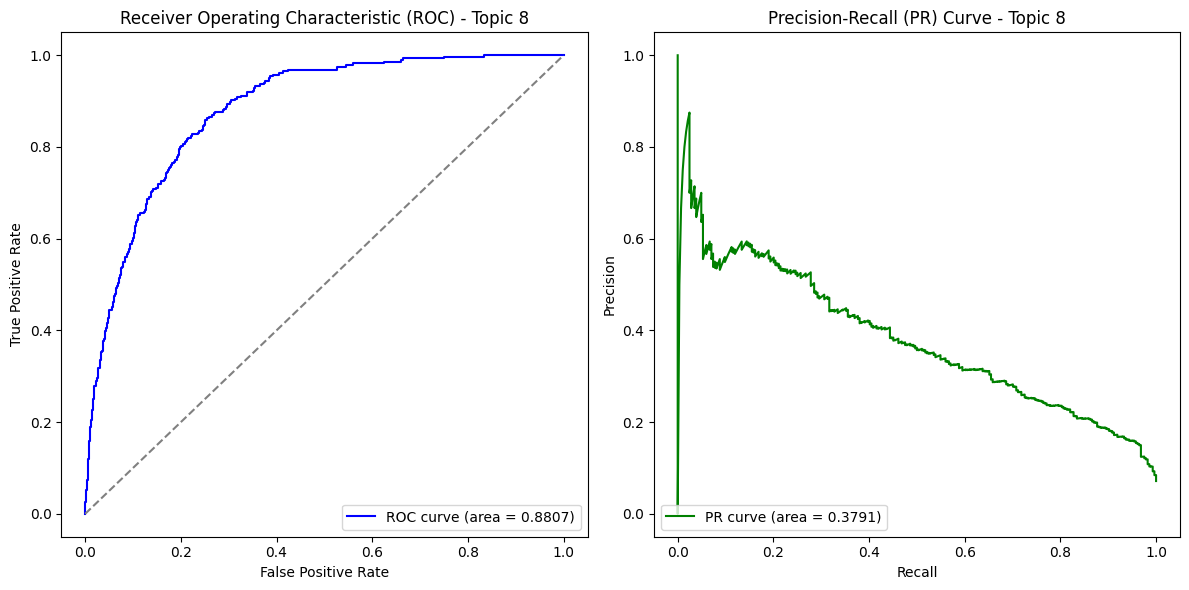

Evaluating topic 9
Topic 9 - auROC: 0.9201, auPR: 0.4980, F1: 0.5066


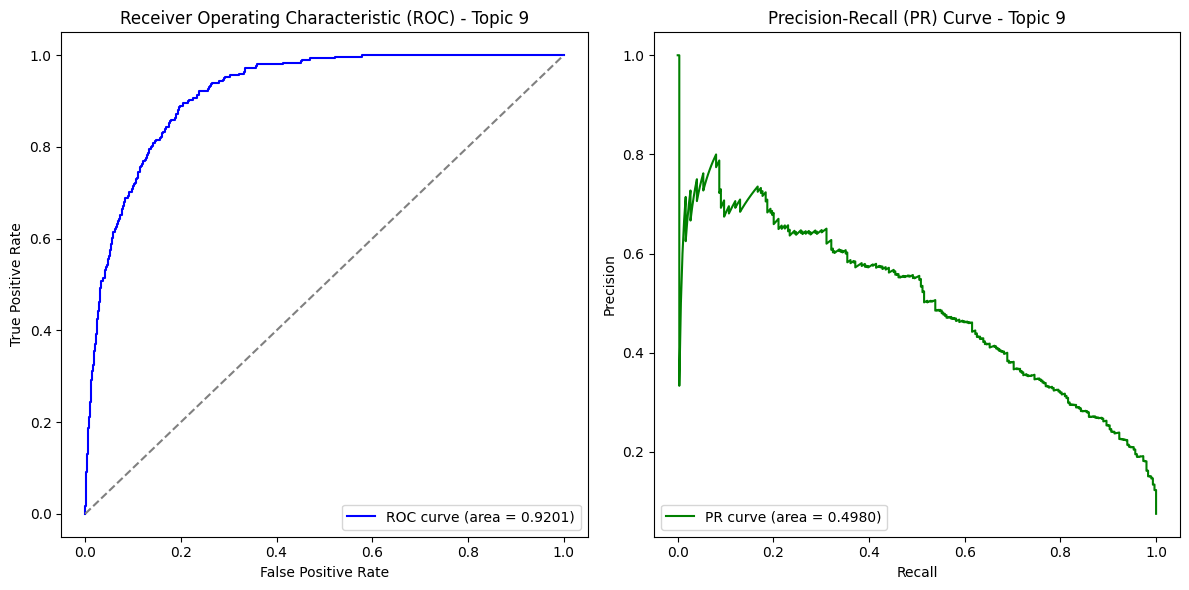

Evaluating topic 10
Topic 10 - auROC: 0.7576, auPR: 0.2499, F1: 0.1955


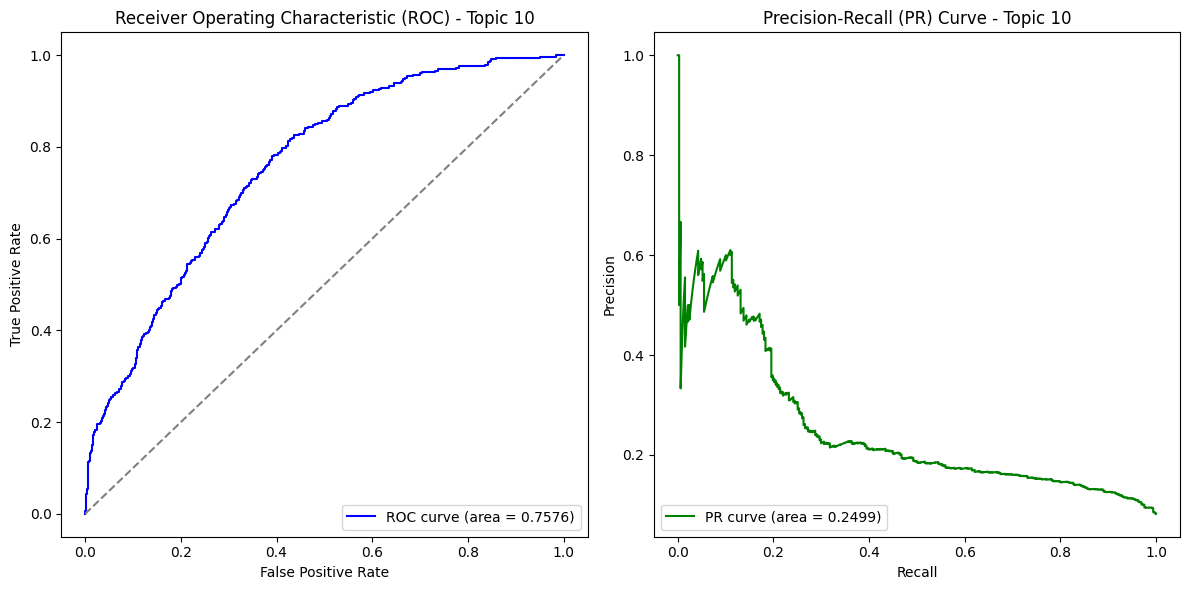

Evaluating topic 11
Topic 11 - auROC: 0.8668, auPR: 0.3961, F1: 0.3962


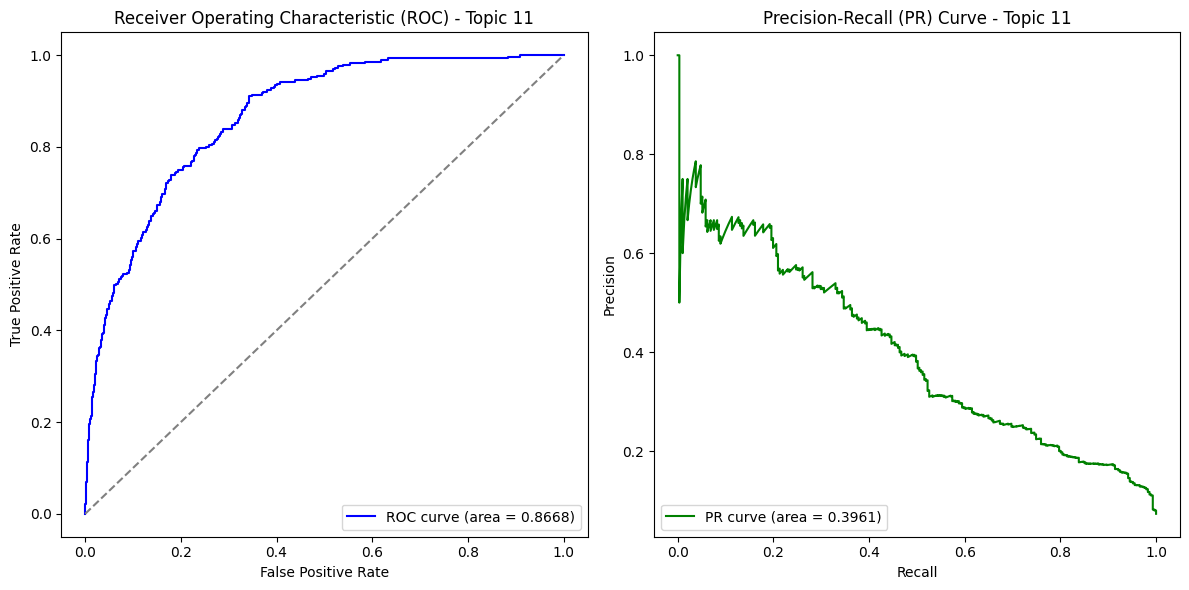

Evaluating topic 12
Topic 12 - auROC: 0.8088, auPR: 0.2940, F1: 0.2870


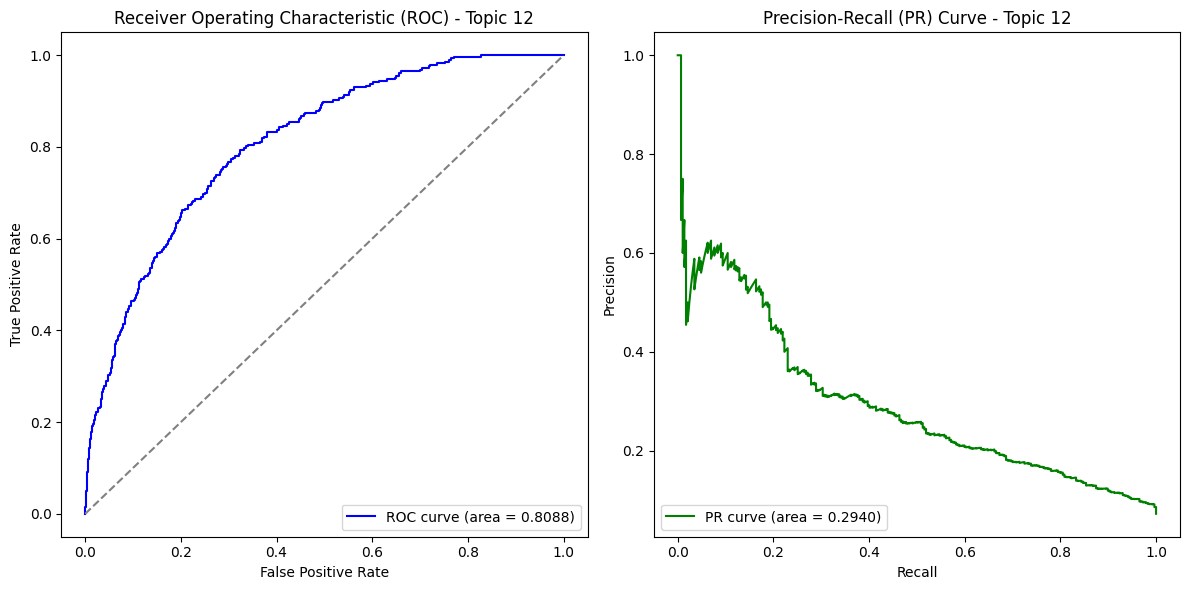

Evaluating topic 13
Topic 13 - auROC: 0.7386, auPR: 0.1787, F1: 0.1959


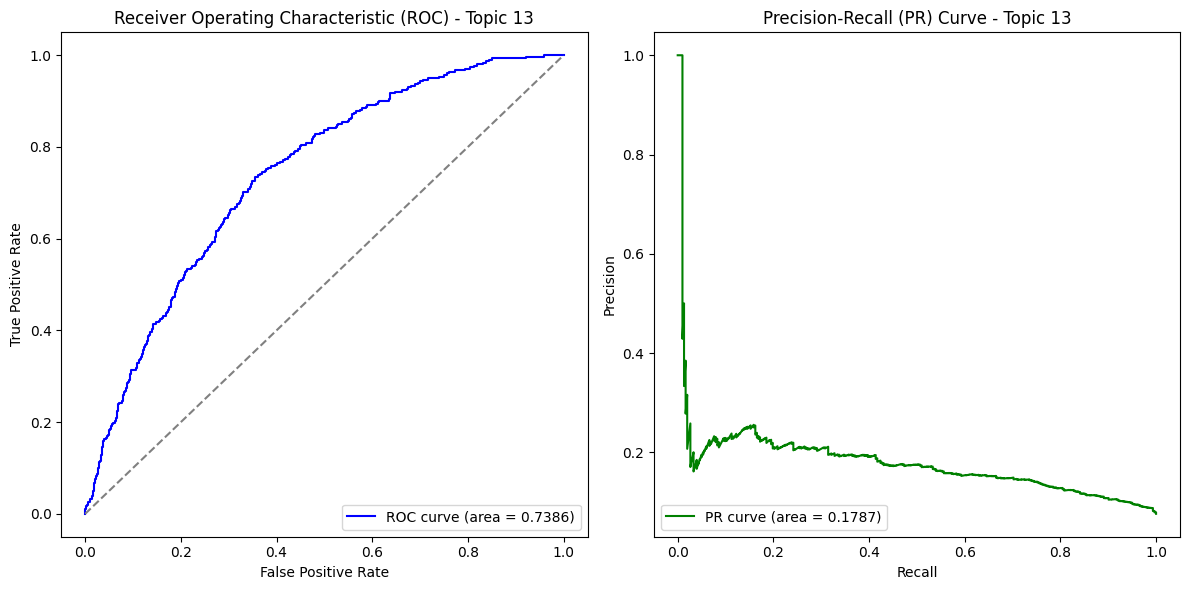

Evaluating topic 14
Topic 14 - auROC: 0.9007, auPR: 0.4767, F1: 0.4643


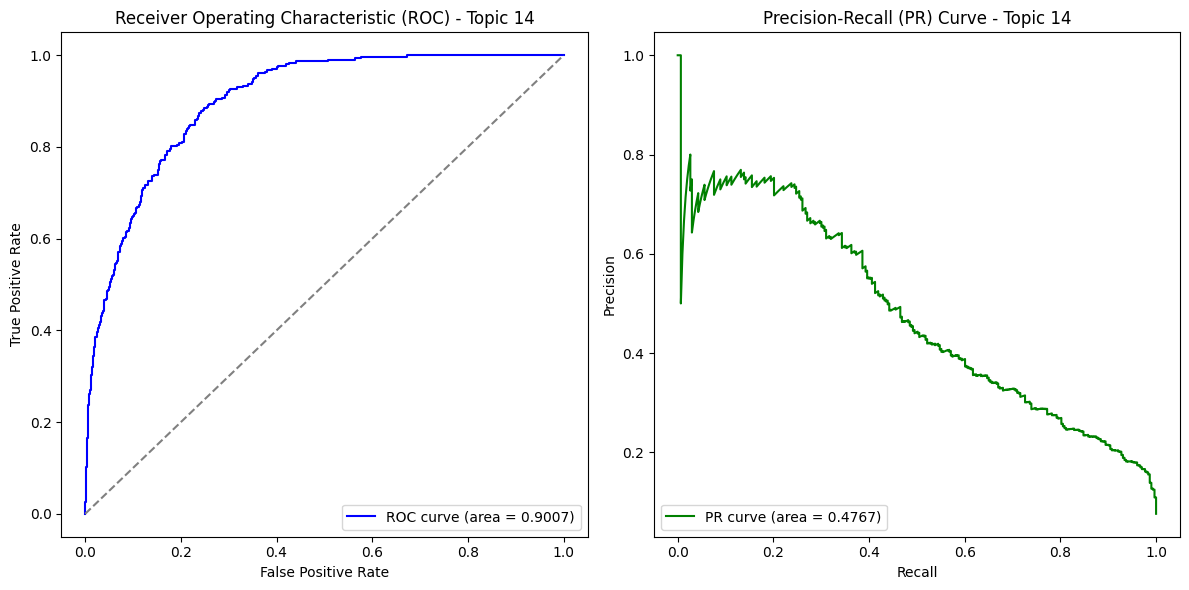

Evaluating topic 15
Topic 15 - auROC: 0.9664, auPR: 0.7296, F1: 0.5351


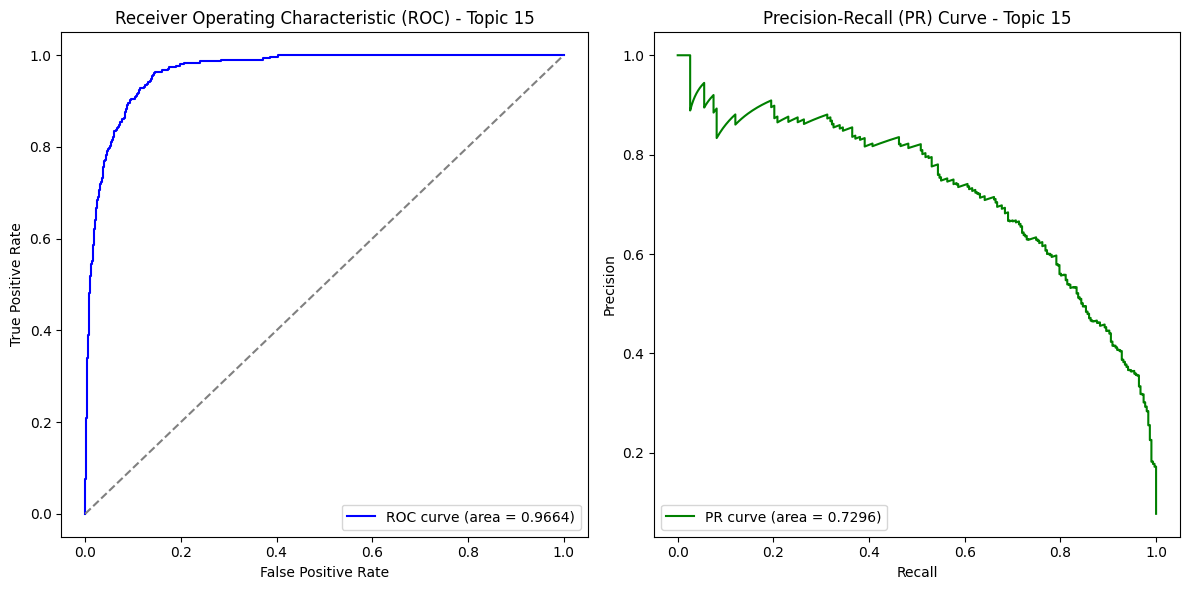

Evaluating topic 16
Topic 16 - auROC: 0.9065, auPR: 0.4880, F1: 0.5034


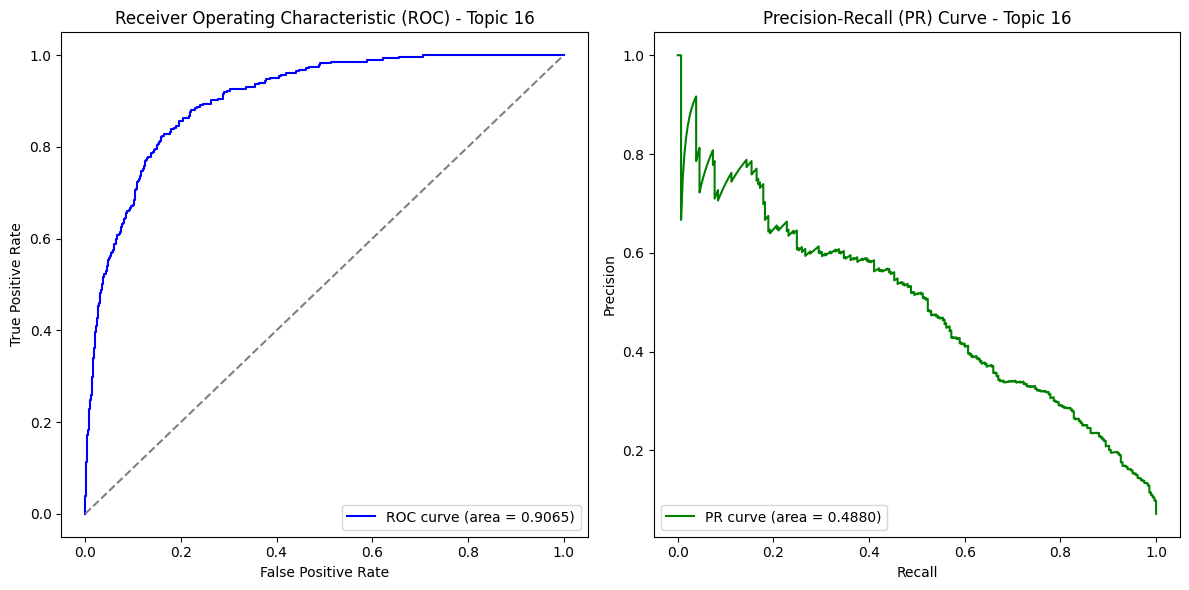

In [22]:
# Evaluate model performance for each topic
num_topics = y_test_np.shape[1]
auroc_values = []
aupr_values = []
f1_scores = []

print(f"\nEvaluating {num_topics} topics...")

for topic_idx in range(num_topics):
    print(f'Evaluating topic {topic_idx+1}')
    
    # Calculate ROC and PR metrics for the current topic
    fpr, tpr, _ = roc_curve(y_test_np[:, topic_idx], y_pred_np[:, topic_idx])
    roc_auc = auc(fpr, tpr)
    auroc_values.append(roc_auc)
    
    precision, recall, _ = precision_recall_curve(y_test_np[:, topic_idx], y_pred_np[:, topic_idx])
    pr_auc = auc(recall, precision)
    aupr_values.append(pr_auc)

    # Binarize predictions for F1 score calculation
    y_pred_bin = (y_pred_np[:, topic_idx] >= 0.5).astype(int)
    f1 = f1_score(y_test_np[:, topic_idx], y_pred_bin)
    f1_scores.append(f1)
    
    print(f'Topic {topic_idx+1} - auROC: {roc_auc:.4f}, auPR: {pr_auc:.4f}, F1: {f1:.4f}')
    
    # Plot ROC and PR curves for the current topic
    plt.figure(figsize=(12, 6))
    
    # ROC Curve
    plt.subplot(1, 2, 1)
    plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Receiver Operating Characteristic (ROC) - Topic {topic_idx+1}')
    plt.legend(loc='lower right')
    
    # PR Curve
    plt.subplot(1, 2, 2)
    plt.plot(recall, precision, color='green', label=f'PR curve (area = {pr_auc:.4f})')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall (PR) Curve - Topic {topic_idx+1}')
    plt.legend(loc='lower left')
    
    plt.tight_layout()
    plt.show()

In [23]:
# Summary statistics
print(f"\nSummary Statistics:")
print(f"Mean auROC: {np.mean(auroc_values):.4f} ± {np.std(auroc_values):.4f}")
print(f"Mean auPR: {np.mean(aupr_values):.4f} ± {np.std(aupr_values):.4f}")
print(f"Mean F1: {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")
print(f"Exact Match Accuracy: {exact_acc:.4f}")
print(f"Accuracy: {hamming_acc:.4f}")


Summary Statistics:
Mean auROC: 0.8790 ± 0.0657
Mean auPR: 0.4653 ± 0.1693
Mean F1: 0.4331 ± 0.1338
Exact Match Accuracy: 0.2445
Accuracy: 0.9089


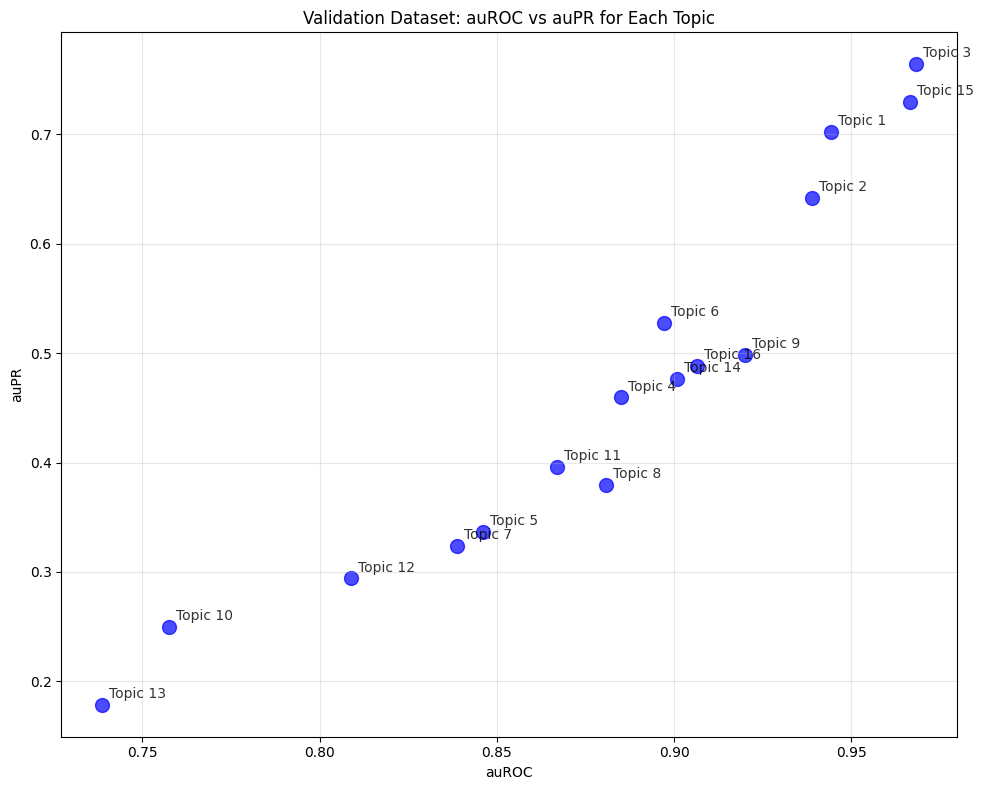

In [24]:
# Scatter plot of auROC vs auPR
plt.figure(figsize=(10, 8))
plt.scatter(auroc_values, aupr_values, color='blue', alpha=0.7, s=100, )
plt.xlabel('auROC')
plt.ylabel('auPR')
plt.title(eval_dataset + ': auROC vs auPR for Each Topic')
plt.grid(True, alpha=0.3)

# Annotate each point with the topic index
for i, (x, y) in enumerate(zip(auroc_values, aupr_values)):
    plt.annotate(f'Topic {i+1}', (x, y), fontsize=10, alpha=0.8, 
                xytext=(5, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## Evaluate model on validation dataset

In [29]:
eval_dataset = 'Validation Dataset'

In [30]:
# Evaluate model on validation dataset
dataset = val_dataset
dataloader = val_dataloader

model.eval()

loss, correct = 0, 0
all_test_probs = []
all_test_targets = []

with torch.no_grad():
    for batch in dataloader:
        X, y = batch['sequence'], batch['label']
        X, y = X.to(device), y.to(device)
        y = y.float()
        
        pred = model(X)
        prob = torch.sigmoid(pred)
        # loss += loss_fn(pred, y).item()
        
        all_test_probs.append(prob)
        all_test_targets.append(y)
        
        # Exact match accuracy
        pred_binary = (prob > 0.5).float()
        exact_match = ((pred_binary == y).sum(dim=1) == y.shape[1]).float().sum().item()
        correct += exact_match

all_test_probs = torch.cat(all_test_probs, dim=0)
all_test_targets = torch.cat(all_test_targets, dim=0)

# loss /= len(dataloader)
exact_acc = correct / len(dataset)

pred_binary = (all_test_probs > 0.5).float()
hamming_acc = (pred_binary == all_test_targets).float().mean().item()

In [31]:
# Convert PyTorch tensors to numpy for sklearn
y_pred_np = all_test_probs.cpu().numpy()
y_test_np = all_test_targets.cpu().numpy()

print("Prediction min/max:", np.min(y_pred_np), np.max(y_pred_np))
print("Prediction shape:", y_pred_np.shape)
print("Target shape:", y_test_np.shape)

Prediction min/max: 0.0015635072 0.96846855
Prediction shape: (2673, 11)
Target shape: (2673, 11)


In [32]:
from utils.evaluate import evaluate_multilabel_model, calculate_overall_metrics, analyze_topic_difficulty, plot_per_topic_metrics, optimize_thresholds_per_topic

PER-TOPIC EVALUATION RESULTS
Topic        Precision  Recall   F1       AUROC    AUPR     Support  Preds 
--------------------------------------------------------------------------------
Topic_1      0.350      0.722    0.471    0.871    0.543    309.0    637   
Topic_2      0.398      0.391    0.394    0.814    0.380    289.0    284   
Topic_3      0.413      0.850    0.556    0.931    0.731    294.0    605   
Topic_4      0.594      0.696    0.641    0.914    0.671    319.0    374   
Topic_5      0.552      0.061    0.110    0.739    0.266    262.0    29    
Topic_6      0.393      0.601    0.475    0.861    0.457    306.0    468   
Topic_7      0.392      0.513    0.444    0.844    0.377    308.0    403   
Topic_8      0.515      0.684    0.588    0.911    0.573    297.0    394   
Topic_9      0.331      0.847    0.476    0.891    0.525    288.0    737   
Topic_10     0.421      0.549    0.477    0.868    0.436    308.0    401   
Topic_11     0.381      0.655    0.482    0.876    0.5

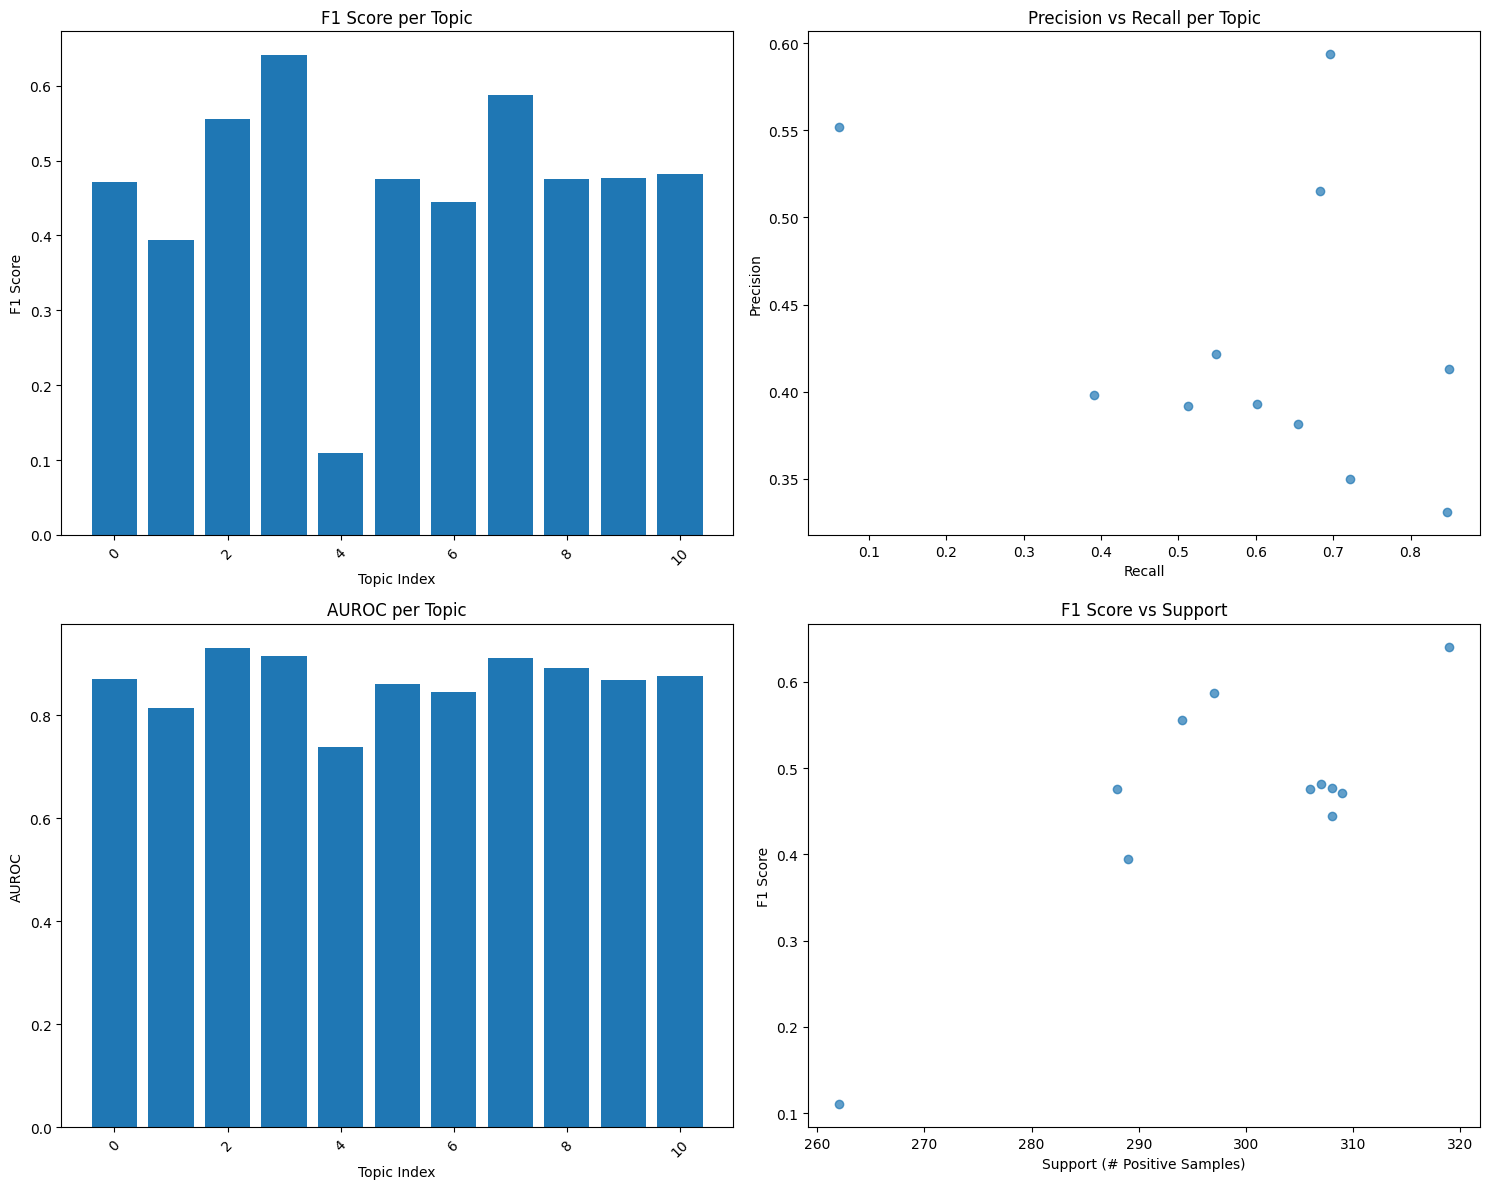


THRESHOLD OPTIMIZATION PER TOPIC
Topic    Best Thresh  Best F1    Precision  Recall  
------------------------------------------------------------
Topic_1   0.60         0.519      0.447      0.618   
Topic_2   0.50         0.394      0.398      0.391   
Topic_3   0.75         0.664      0.726      0.612   
Topic_4   0.55         0.643      0.634      0.652   
Topic_5   0.30         0.301      0.233      0.427   
Topic_6   0.55         0.479      0.438      0.529   
Topic_7   0.40         0.454      0.340      0.682   
Topic_8   0.50         0.588      0.515      0.684   
Topic_9   0.65         0.551      0.467      0.670   
Topic_10  0.45         0.479      0.371      0.675   
Topic_11  0.55         0.495      0.438      0.570   


In [33]:
# 1. Run comprehensive evaluation
results_df = evaluate_multilabel_model(y_test_np, y_pred_np, threshold=0.5)

# 2. Calculate overall metrics
overall_metrics = calculate_overall_metrics(y_test_np, y_pred_np, threshold=0.5)

# 3. Analyze topic difficulty
sorted_results = analyze_topic_difficulty(results_df, n_top=5)

# 4. Plot performance metrics
plot_per_topic_metrics(results_df)

# 5. Optimize thresholds per topic
optimal_thresholds, optimal_f1_scores = optimize_thresholds_per_topic(y_test_np, y_pred_np)

# 6. Save results to CSV
# results_df.to_csv(f'{checkpoint_path}/per_topic_evaluation.csv', index=False)
# print(f"\nResults saved to '{checkpoint_path}/per_topic_evaluation.csv'")

In [34]:
# Apply optimal thresholds for confusion matrices
print("\nConfusion matrices for each topic (with optimal thresholds):")
for i in range(y_test_np.shape[1]):
    # Use the optimal threshold for this specific topic
    optimal_thresh = optimal_thresholds[i]
    y_pred_binary = (y_pred_np[:, i] > optimal_thresh).astype(int)
    
    print(f"\nTopic {i+1} (threshold: {optimal_thresh:.2f}):")
    cm = confusion_matrix(y_test_np[:, i], y_pred_binary)
    print(cm)
    
    # Optional: Calculate and display metrics for this topic
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    print(f"  Precision: {precision:.3f}, Recall: {recall:.3f}, F1: {f1:.3f}")
    print(f"  TP: {tp}, FP: {fp}, FN: {fn}, TN: {tn}")


Confusion matrices for each topic (with optimal thresholds):

Topic 1 (threshold: 0.60):
[[2128  236]
 [ 118  191]]
  Precision: 0.447, Recall: 0.618, F1: 0.519
  TP: 191, FP: 236, FN: 118, TN: 2128

Topic 2 (threshold: 0.50):
[[2213  171]
 [ 176  113]]
  Precision: 0.398, Recall: 0.391, F1: 0.394
  TP: 113, FP: 171, FN: 176, TN: 2213

Topic 3 (threshold: 0.75):
[[2311   68]
 [ 114  180]]
  Precision: 0.726, Recall: 0.612, F1: 0.664
  TP: 180, FP: 68, FN: 114, TN: 2311

Topic 4 (threshold: 0.55):
[[2234  120]
 [ 111  208]]
  Precision: 0.634, Recall: 0.652, F1: 0.643
  TP: 208, FP: 120, FN: 111, TN: 2234

Topic 5 (threshold: 0.30):
[[2042  369]
 [ 150  112]]
  Precision: 0.233, Recall: 0.427, F1: 0.301
  TP: 112, FP: 369, FN: 150, TN: 2042

Topic 6 (threshold: 0.55):
[[2159  208]
 [ 144  162]]
  Precision: 0.438, Recall: 0.529, F1: 0.479
  TP: 162, FP: 208, FN: 144, TN: 2159

Topic 7 (threshold: 0.40):
[[1957  408]
 [  98  210]]
  Precision: 0.340, Recall: 0.682, F1: 0.454
  TP: 210, 


Evaluating 11 topics...
Evaluating topic 1
Topic 1 - auROC: 0.8712, auPR: 0.5422, F1: 0.4715


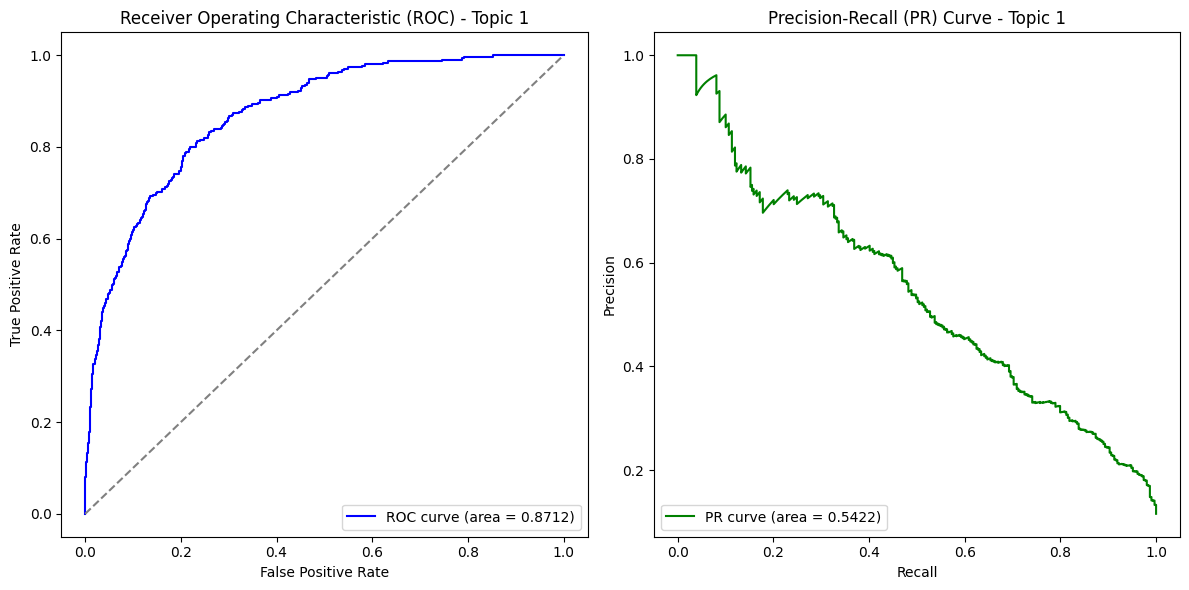

Evaluating topic 2
Topic 2 - auROC: 0.8135, auPR: 0.3786, F1: 0.3944


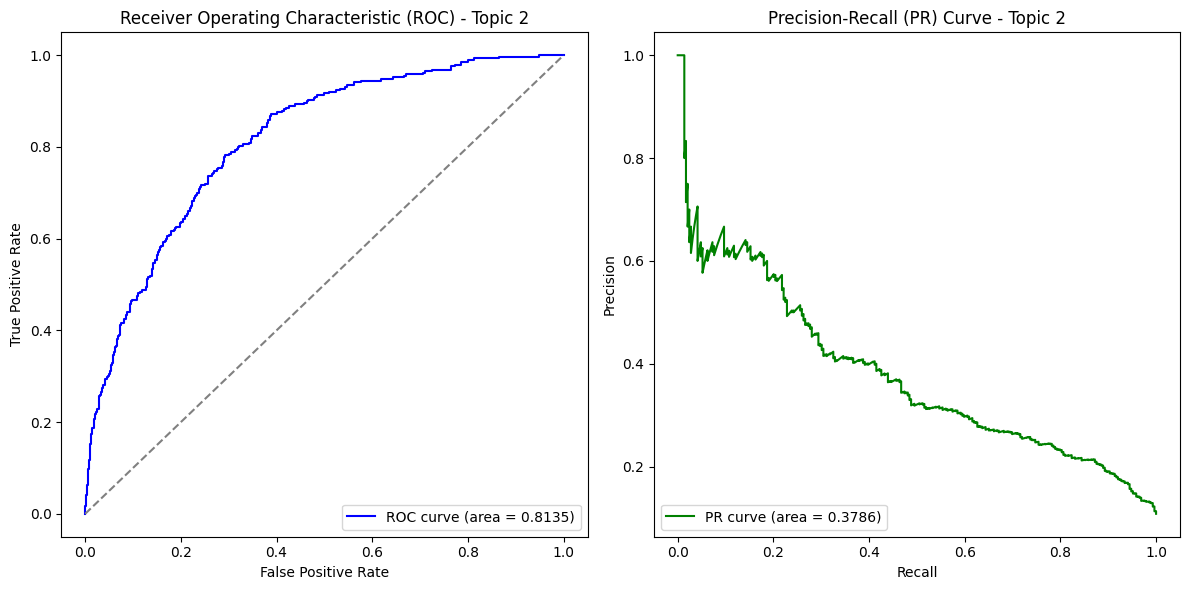

Evaluating topic 3
Topic 3 - auROC: 0.9310, auPR: 0.7302, F1: 0.5562


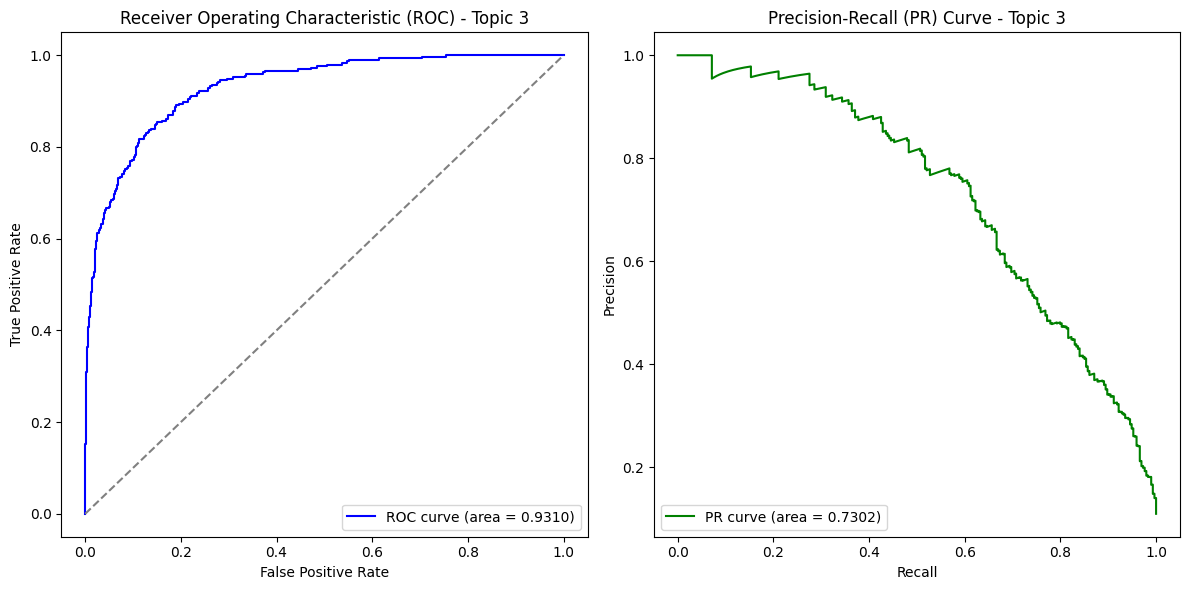

Evaluating topic 4
Topic 4 - auROC: 0.9144, auPR: 0.6695, F1: 0.6407


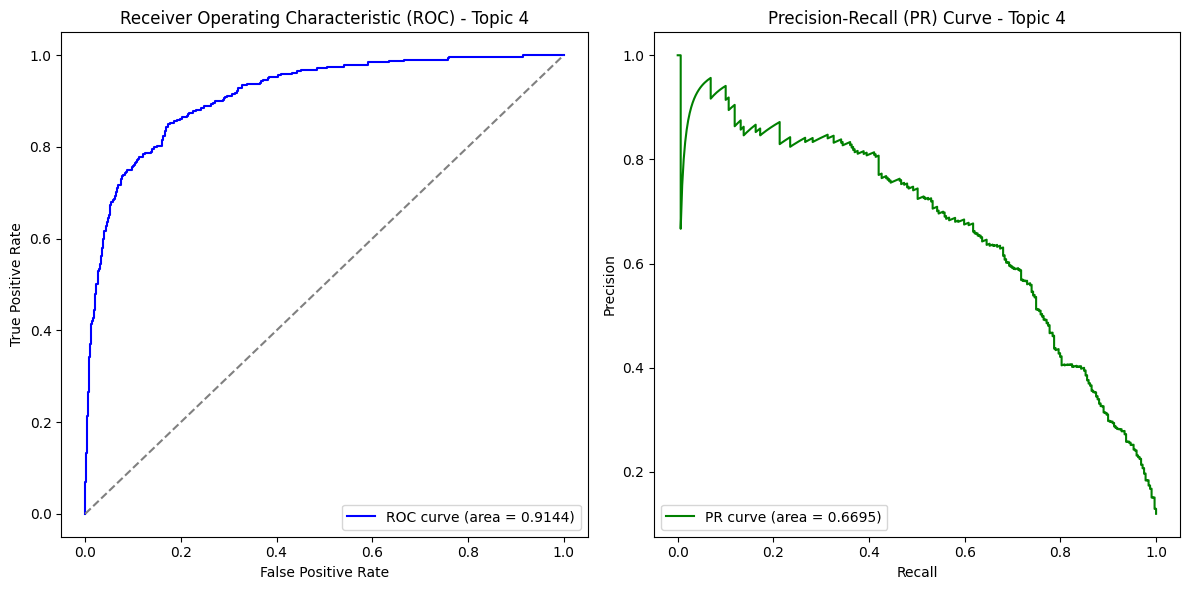

Evaluating topic 5
Topic 5 - auROC: 0.7391, auPR: 0.2642, F1: 0.1100


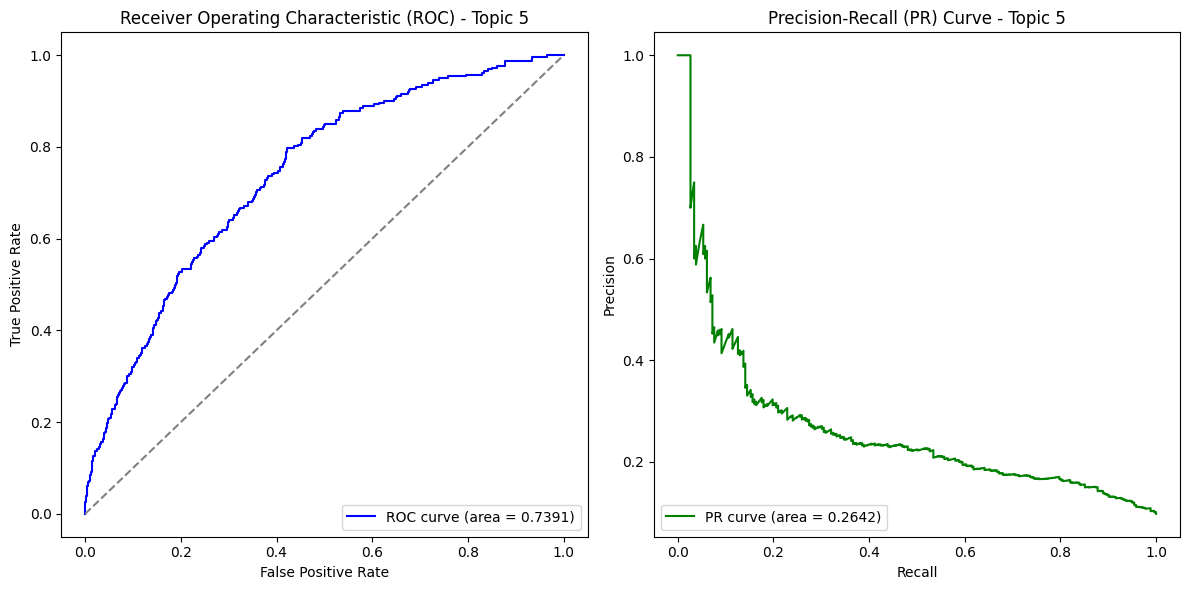

Evaluating topic 6
Topic 6 - auROC: 0.8609, auPR: 0.4547, F1: 0.4755


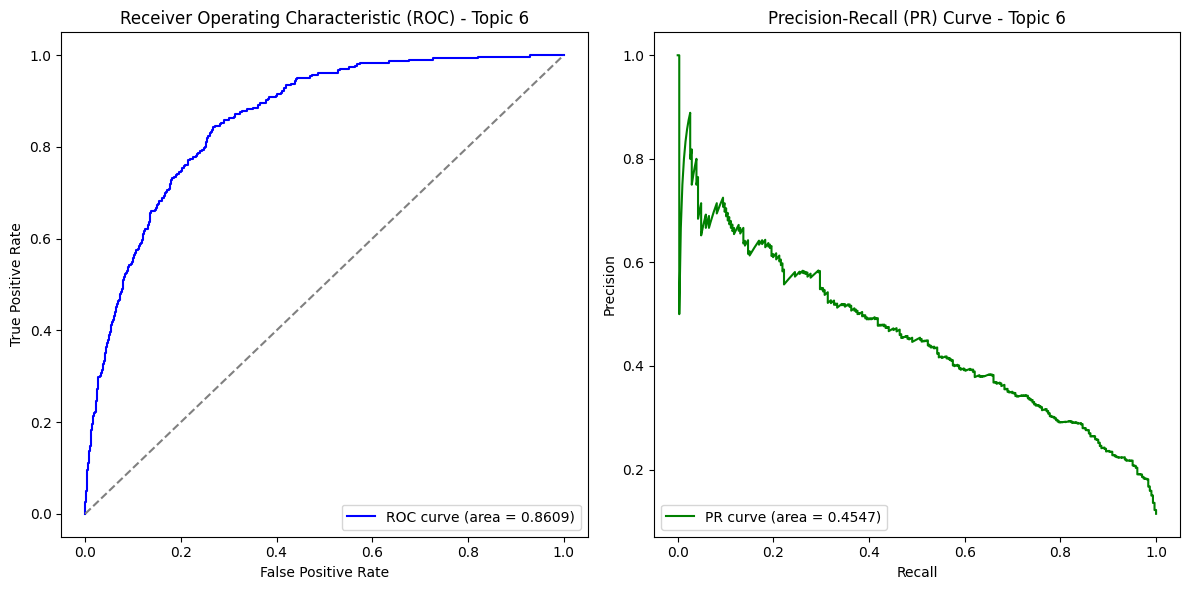

Evaluating topic 7
Topic 7 - auROC: 0.8445, auPR: 0.3757, F1: 0.4444


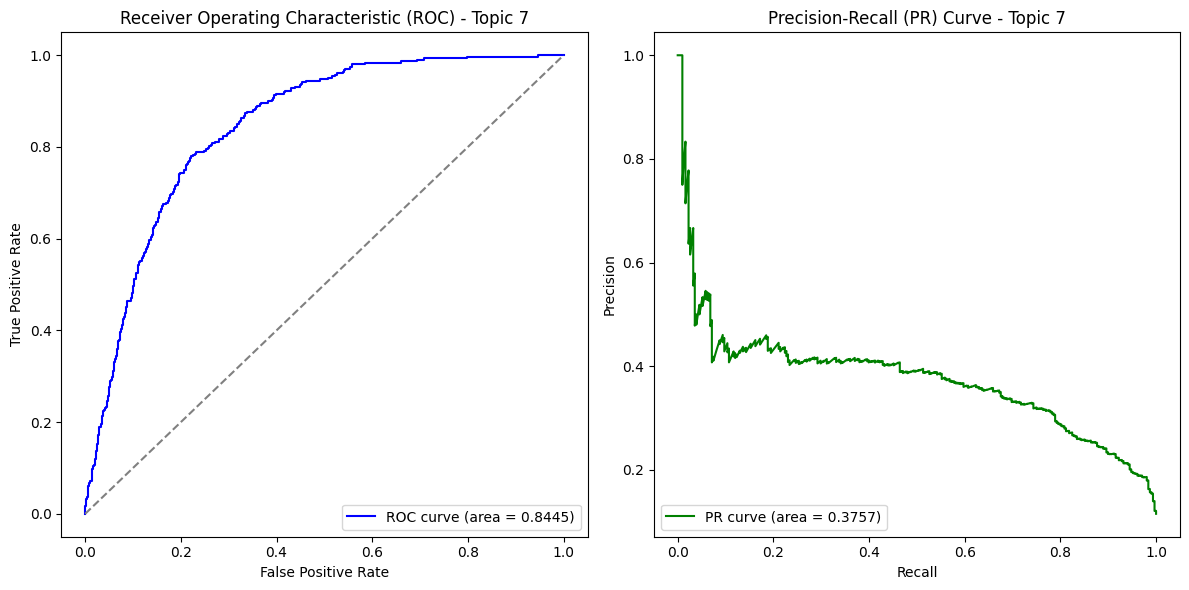

Evaluating topic 8
Topic 8 - auROC: 0.9112, auPR: 0.5710, F1: 0.5876


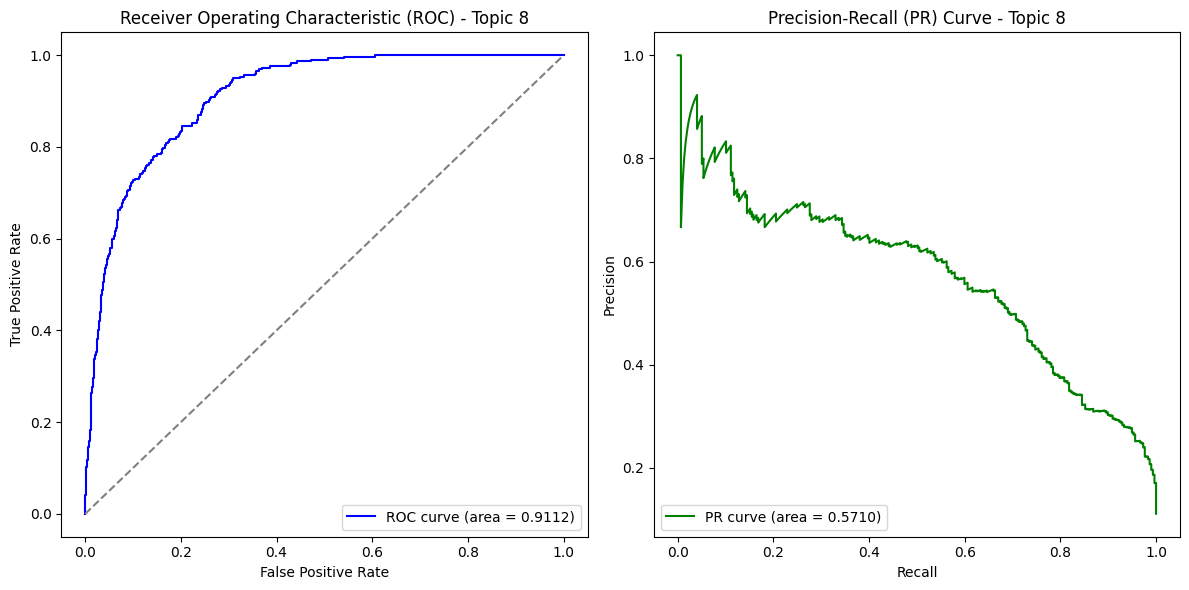

Evaluating topic 9
Topic 9 - auROC: 0.8909, auPR: 0.5231, F1: 0.4761


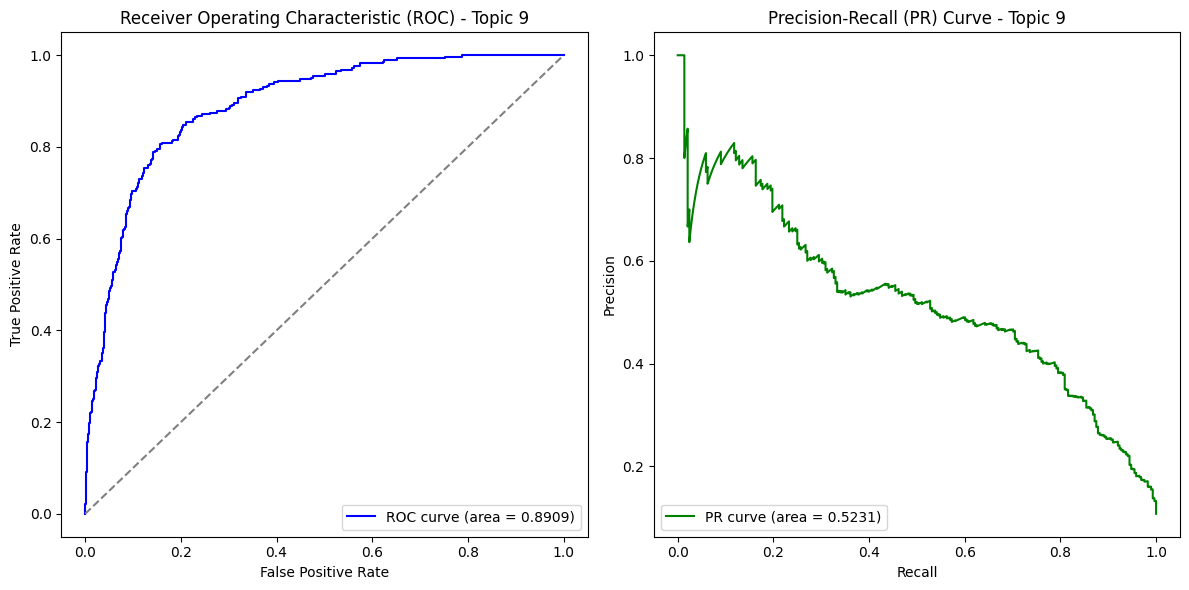

Evaluating topic 10
Topic 10 - auROC: 0.8685, auPR: 0.4344, F1: 0.4767


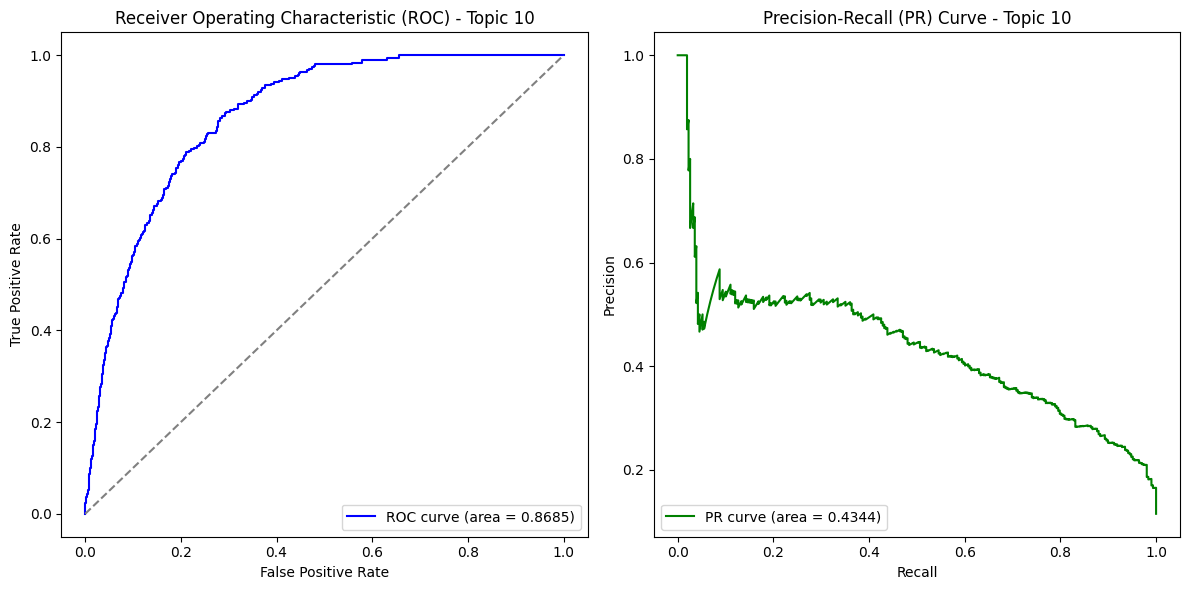

Evaluating topic 11
Topic 11 - auROC: 0.8761, auPR: 0.5008, F1: 0.4820


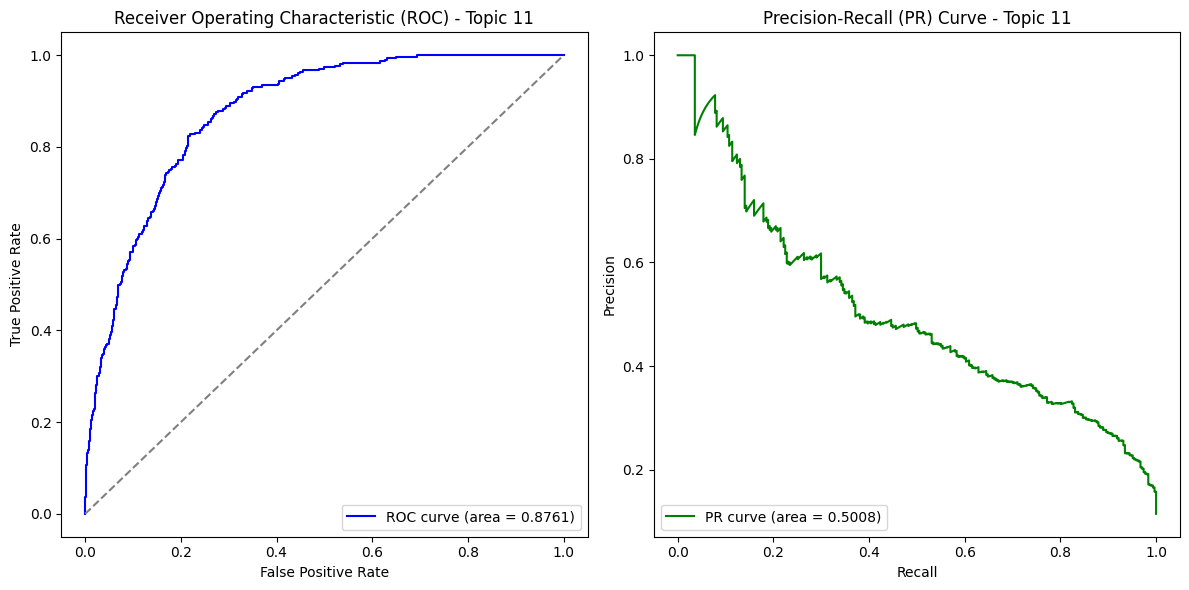

In [35]:
# Evaluate model performance for each topic
num_topics = y_test_np.shape[1]
auroc_values = []
aupr_values = []
f1_scores = []

print(f"\nEvaluating {num_topics} topics...")

for topic_idx in range(num_topics):
    print(f'Evaluating topic {topic_idx+1}')
    
    # Calculate ROC and PR metrics for the current topic
    fpr, tpr, _ = roc_curve(y_test_np[:, topic_idx], y_pred_np[:, topic_idx])
    roc_auc = auc(fpr, tpr)
    auroc_values.append(roc_auc)
    
    precision, recall, _ = precision_recall_curve(y_test_np[:, topic_idx], y_pred_np[:, topic_idx])
    pr_auc = auc(recall, precision)
    aupr_values.append(pr_auc)

    # Binarize predictions for F1 score calculation
    y_pred_bin = (y_pred_np[:, topic_idx] >= 0.5).astype(int)
    f1 = f1_score(y_test_np[:, topic_idx], y_pred_bin)
    f1_scores.append(f1)
    
    print(f'Topic {topic_idx+1} - auROC: {roc_auc:.4f}, auPR: {pr_auc:.4f}, F1: {f1:.4f}')
    
    # Plot ROC and PR curves for the current topic
    plt.figure(figsize=(12, 6))
    
    # ROC Curve
    plt.subplot(1, 2, 1)
    plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Receiver Operating Characteristic (ROC) - Topic {topic_idx+1}')
    plt.legend(loc='lower right')
    
    # PR Curve
    plt.subplot(1, 2, 2)
    plt.plot(recall, precision, color='green', label=f'PR curve (area = {pr_auc:.4f})')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall (PR) Curve - Topic {topic_idx+1}')
    plt.legend(loc='lower left')
    
    plt.tight_layout()
    plt.show()

In [36]:
# Summary statistics
print(f"\nSummary Statistics:")
print(f"Mean auROC: {np.mean(auroc_values):.4f} ± {np.std(auroc_values):.4f}")
print(f"Mean auPR: {np.mean(aupr_values):.4f} ± {np.std(aupr_values):.4f}")
print(f"Mean F1: {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")
print(f"Exact Match Accuracy: {exact_acc:.4f}")
print(f"Accuracy: {hamming_acc:.4f}")


Summary Statistics:
Mean auROC: 0.8656 ± 0.0511
Mean auPR: 0.4950 ± 0.1283
Mean F1: 0.4650 ± 0.1302
Exact Match Accuracy: 0.2884
Accuracy: 0.8578


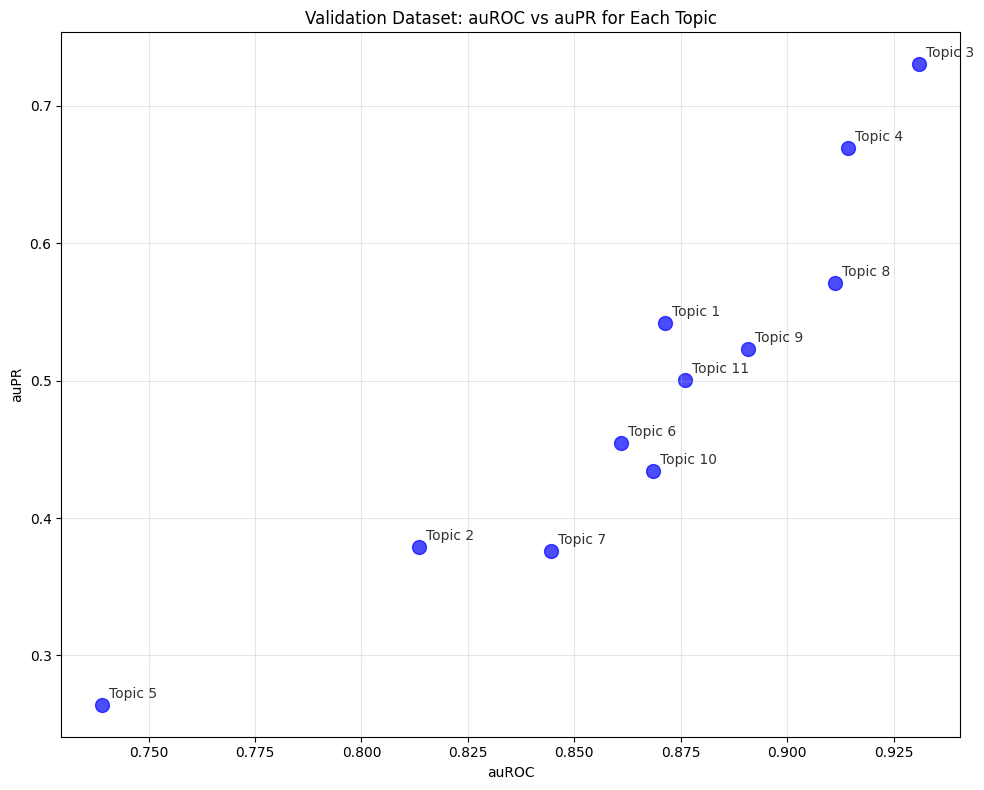

In [37]:
# Scatter plot of auROC vs auPR
plt.figure(figsize=(10, 8))
plt.scatter(auroc_values, aupr_values, color='blue', alpha=0.7, s=100, )
plt.xlabel('auROC')
plt.ylabel('auPR')
plt.title(eval_dataset + ': auROC vs auPR for Each Topic')
plt.grid(True, alpha=0.3)

# Annotate each point with the topic index
for i, (x, y) in enumerate(zip(auroc_values, aupr_values)):
    plt.annotate(f'Topic {i+1}', (x, y), fontsize=10, alpha=0.8, 
                xytext=(5, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## Evaluate model on test dataset

In [20]:
eval_dataset = 'Test Dataset'

In [21]:
# Evaluate model on test dataset
dataset = test_dataset
dataloader = test_dataloader

model.eval()

loss, correct = 0, 0
all_test_probs = []
all_test_targets = []

with torch.no_grad():
    for batch in dataloader:
        X, y = batch['sequence'], batch['label']
        X, y = X.to(device), y.to(device)
        y = y.float()
        
        pred = model(X)
        prob = torch.sigmoid(pred)
        # loss += loss_fn(pred, y).item()
        
        all_test_probs.append(prob)
        all_test_targets.append(y)
        
        # Exact match accuracy
        pred_binary = (prob > 0.5).float()
        exact_match = ((pred_binary == y).sum(dim=1) == y.shape[1]).float().sum().item()
        correct += exact_match

all_test_probs = torch.cat(all_test_probs, dim=0)
all_test_targets = torch.cat(all_test_targets, dim=0)

# loss /= len(dataloader)
exact_acc = correct / len(dataset)

pred_binary = (all_test_probs > 0.5).float()
hamming_acc = (pred_binary == all_test_targets).float().mean().item()

In [22]:
# Convert PyTorch tensors to numpy for sklearn
y_pred_np = all_test_probs.cpu().numpy()
y_test_np = all_test_targets.cpu().numpy()

print("Prediction min/max:", np.min(y_pred_np), np.max(y_pred_np))
print("Prediction shape:", y_pred_np.shape)
print("Target shape:", y_test_np.shape)

Prediction min/max: 0.0015642794 0.9702856
Prediction shape: (2675, 11)
Target shape: (2675, 11)


In [23]:
from utils.evaluate import evaluate_multilabel_model, calculate_overall_metrics, analyze_topic_difficulty, plot_per_topic_metrics, optimize_thresholds_per_topic

PER-TOPIC EVALUATION RESULTS
Topic        Precision  Recall   F1       AUROC    AUPR     Support  Preds 
--------------------------------------------------------------------------------
Topic_1      0.309      0.642    0.417    0.840    0.450    274.0    570   
Topic_2      0.313      0.292    0.302    0.782    0.311    295.0    275   
Topic_3      0.426      0.858    0.569    0.930    0.758    310.0    625   
Topic_4      0.564      0.751    0.644    0.929    0.725    305.0    406   
Topic_5      0.444      0.058    0.102    0.753    0.266    277.0    36    
Topic_6      0.372      0.614    0.463    0.853    0.417    272.0    449   
Topic_7      0.322      0.391    0.354    0.810    0.299    304.0    369   
Topic_8      0.505      0.652    0.569    0.892    0.583    313.0    404   
Topic_9      0.319      0.769    0.451    0.866    0.500    295.0    712   
Topic_10     0.420      0.518    0.464    0.849    0.428    313.0    386   
Topic_11     0.378      0.644    0.476    0.864    0.4

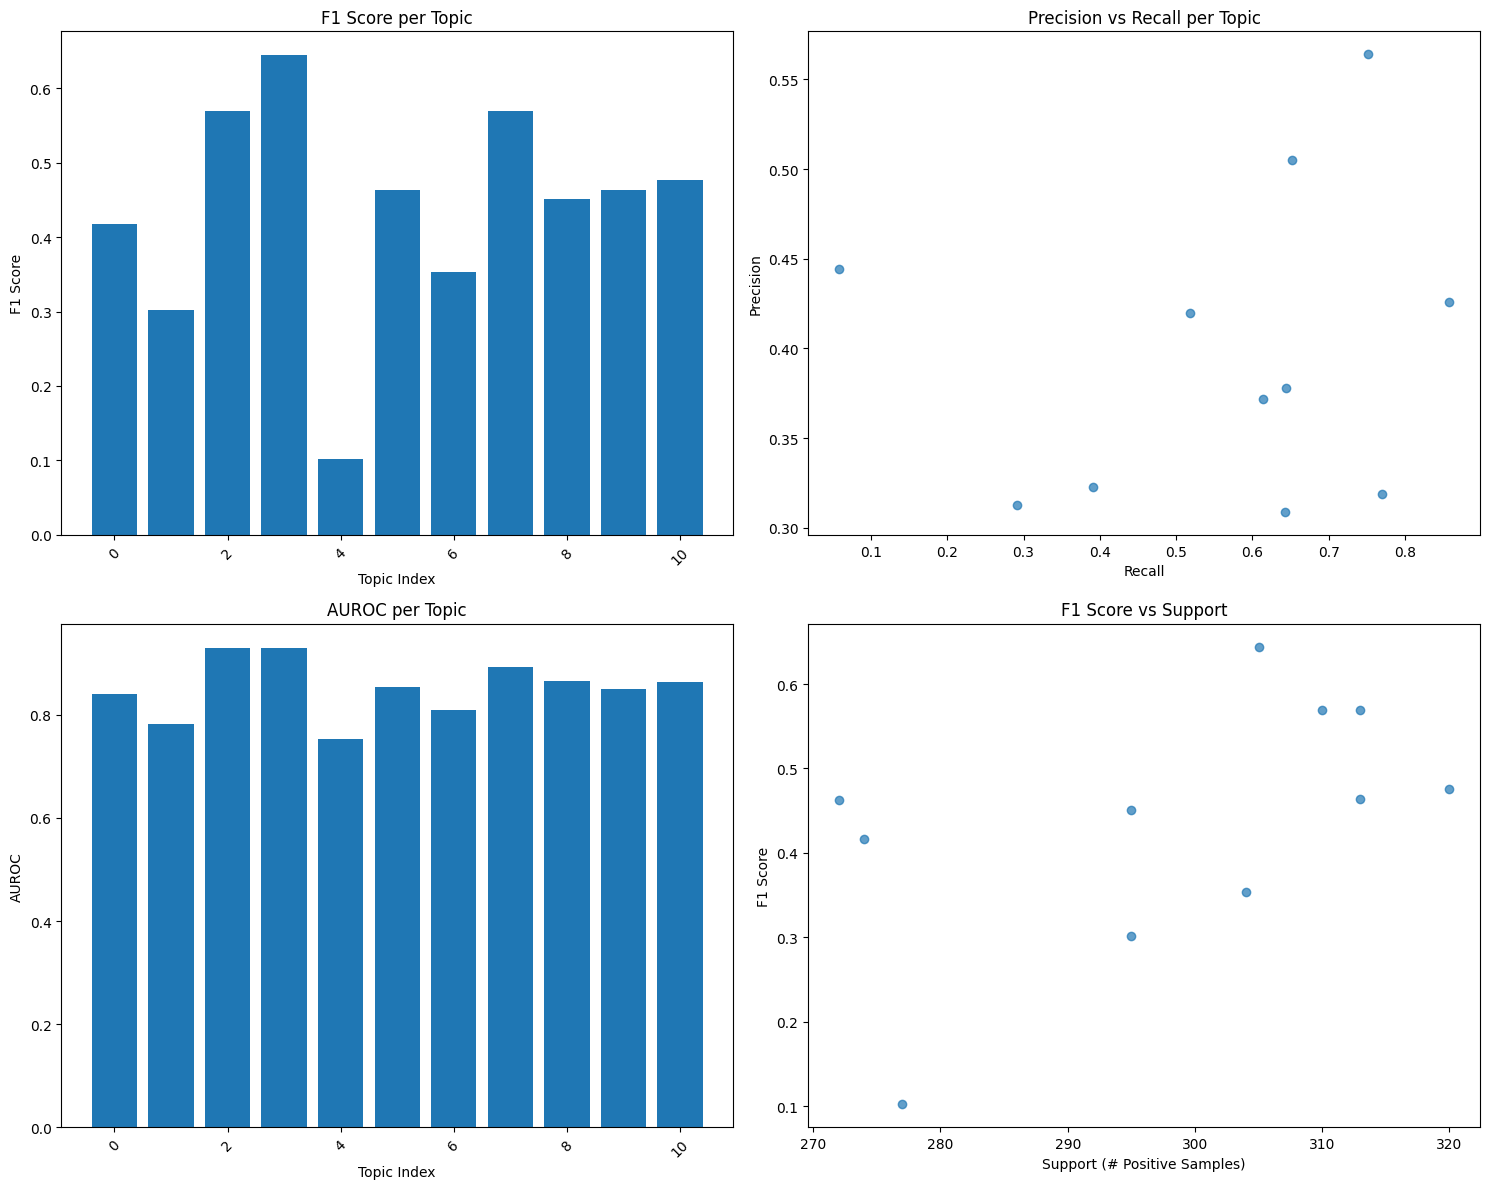


THRESHOLD OPTIMIZATION PER TOPIC
Topic    Best Thresh  Best F1    Precision  Recall  
------------------------------------------------------------
Topic_1   0.65         0.475      0.438      0.518   
Topic_2   0.40         0.362      0.257      0.614   
Topic_3   0.75         0.675      0.756      0.610   
Topic_4   0.60         0.660      0.661      0.659   
Topic_5   0.30         0.329      0.256      0.462   
Topic_6   0.50         0.463      0.372      0.614   
Topic_7   0.35         0.420      0.298      0.711   
Topic_8   0.50         0.569      0.505      0.652   
Topic_9   0.65         0.493      0.432      0.573   
Topic_10  0.50         0.464      0.420      0.518   
Topic_11  0.55         0.480      0.428      0.547   


In [24]:
# 1. Run comprehensive evaluation
results_df = evaluate_multilabel_model(y_test_np, y_pred_np, threshold=0.5)

# 2. Calculate overall metrics
overall_metrics = calculate_overall_metrics(y_test_np, y_pred_np, threshold=0.5)

# 3. Analyze topic difficulty
sorted_results = analyze_topic_difficulty(results_df, n_top=5)

# 4. Plot performance metrics
plot_per_topic_metrics(results_df)

# 5. Optimize thresholds per topic
optimal_thresholds, optimal_f1_scores = optimize_thresholds_per_topic(y_test_np, y_pred_np)

# 6. Save results to CSV
# results_df.to_csv(f'{checkpoint_path}/per_topic_evaluation.csv', index=False)
# print(f"\nResults saved to '{checkpoint_path}/per_topic_evaluation.csv'")

In [25]:
# Apply optimal thresholds for confusion matrices
print("\nConfusion matrices for each topic (with optimal thresholds):")
for i in range(y_test_np.shape[1]):
    # Use the optimal threshold for this specific topic
    optimal_thresh = optimal_thresholds[i]
    y_pred_binary = (y_pred_np[:, i] > optimal_thresh).astype(int)
    
    print(f"\nTopic {i+1} (threshold: {optimal_thresh:.2f}):")
    cm = confusion_matrix(y_test_np[:, i], y_pred_binary)
    print(cm)
    
    # Optional: Calculate and display metrics for this topic
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    print(f"  Precision: {precision:.3f}, Recall: {recall:.3f}, F1: {f1:.3f}")
    print(f"  TP: {tp}, FP: {fp}, FN: {fn}, TN: {tn}")


Confusion matrices for each topic (with optimal thresholds):

Topic 1 (threshold: 0.65):
[[2219  182]
 [ 132  142]]
  Precision: 0.438, Recall: 0.518, F1: 0.475
  TP: 142, FP: 182, FN: 132, TN: 2219

Topic 2 (threshold: 0.40):
[[1857  523]
 [ 114  181]]
  Precision: 0.257, Recall: 0.614, F1: 0.362
  TP: 181, FP: 523, FN: 114, TN: 1857

Topic 3 (threshold: 0.75):
[[2304   61]
 [ 121  189]]
  Precision: 0.756, Recall: 0.610, F1: 0.675
  TP: 189, FP: 61, FN: 121, TN: 2304

Topic 4 (threshold: 0.60):
[[2267  103]
 [ 104  201]]
  Precision: 0.661, Recall: 0.659, F1: 0.660
  TP: 201, FP: 103, FN: 104, TN: 2267

Topic 5 (threshold: 0.30):
[[2026  372]
 [ 149  128]]
  Precision: 0.256, Recall: 0.462, F1: 0.329
  TP: 128, FP: 372, FN: 149, TN: 2026

Topic 6 (threshold: 0.50):
[[2121  282]
 [ 105  167]]
  Precision: 0.372, Recall: 0.614, F1: 0.463
  TP: 167, FP: 282, FN: 105, TN: 2121

Topic 7 (threshold: 0.35):
[[1863  508]
 [  88  216]]
  Precision: 0.298, Recall: 0.711, F1: 0.420
  TP: 216, 


Evaluating 11 topics...
Evaluating topic 1
Topic 1 - auROC: 0.8401, auPR: 0.4485, F1: 0.4171


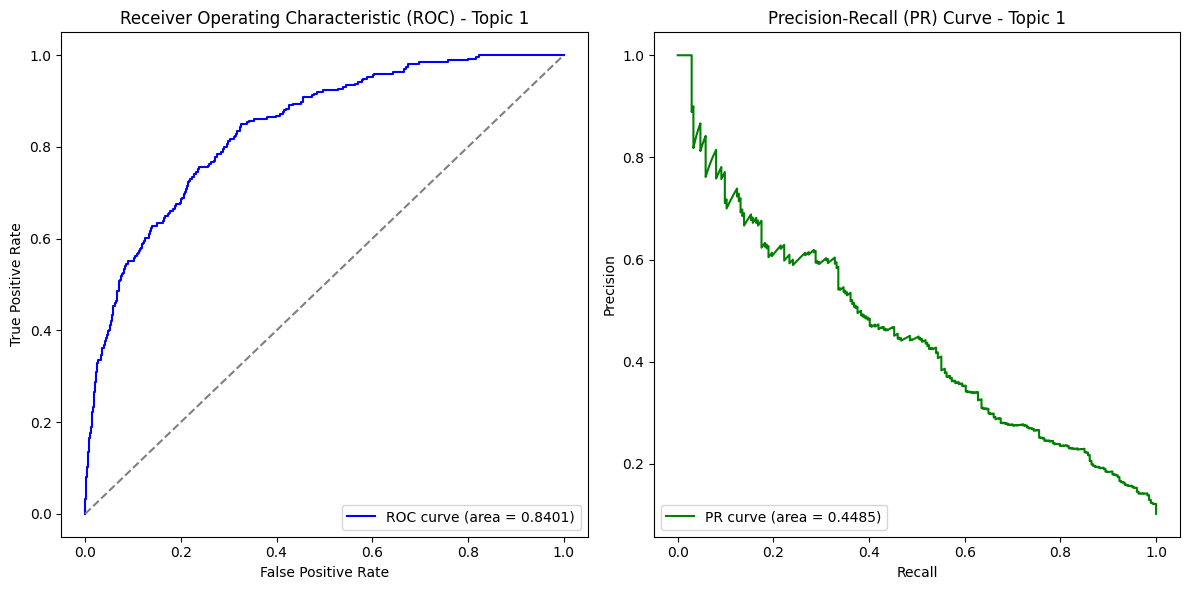

Evaluating topic 2
Topic 2 - auROC: 0.7815, auPR: 0.3092, F1: 0.3018


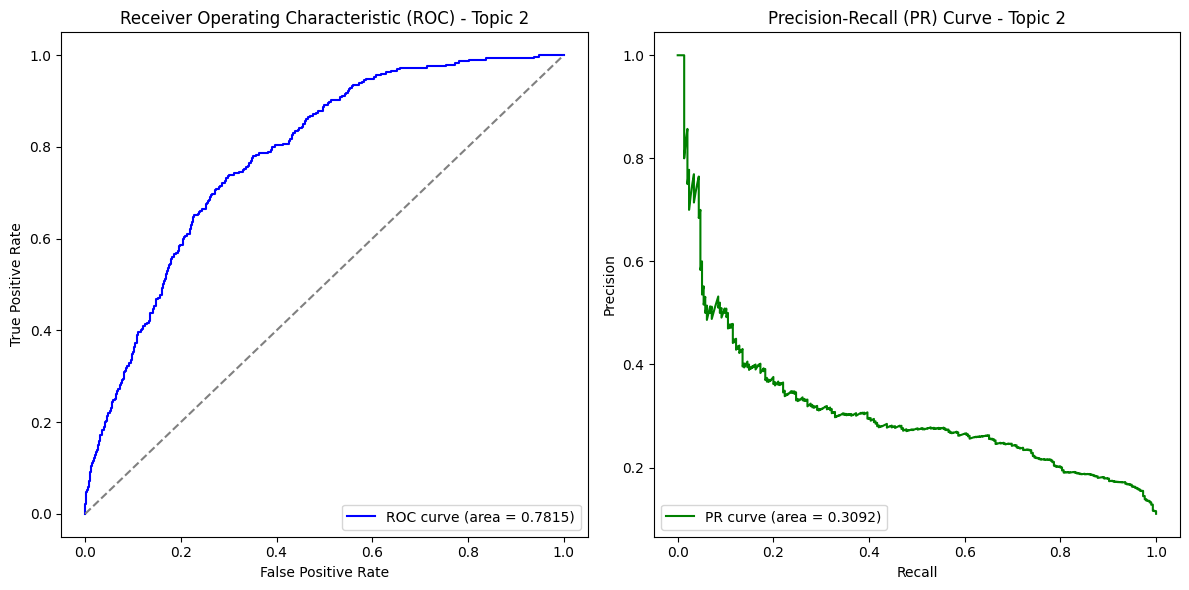

Evaluating topic 3
Topic 3 - auROC: 0.9298, auPR: 0.7572, F1: 0.5690


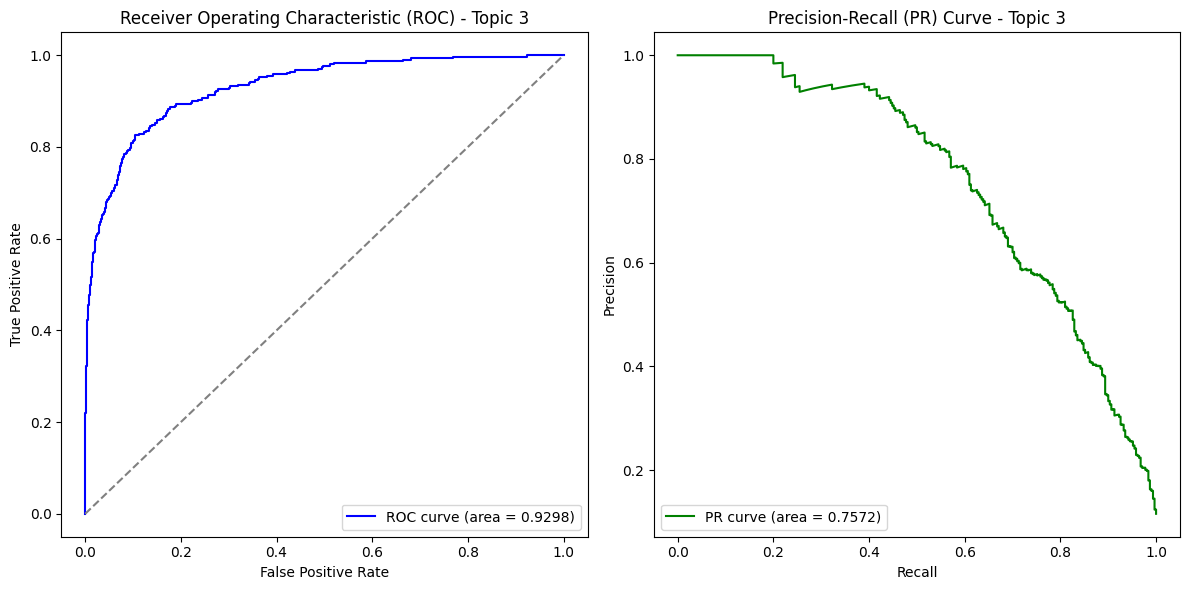

Evaluating topic 4
Topic 4 - auROC: 0.9292, auPR: 0.7242, F1: 0.6442


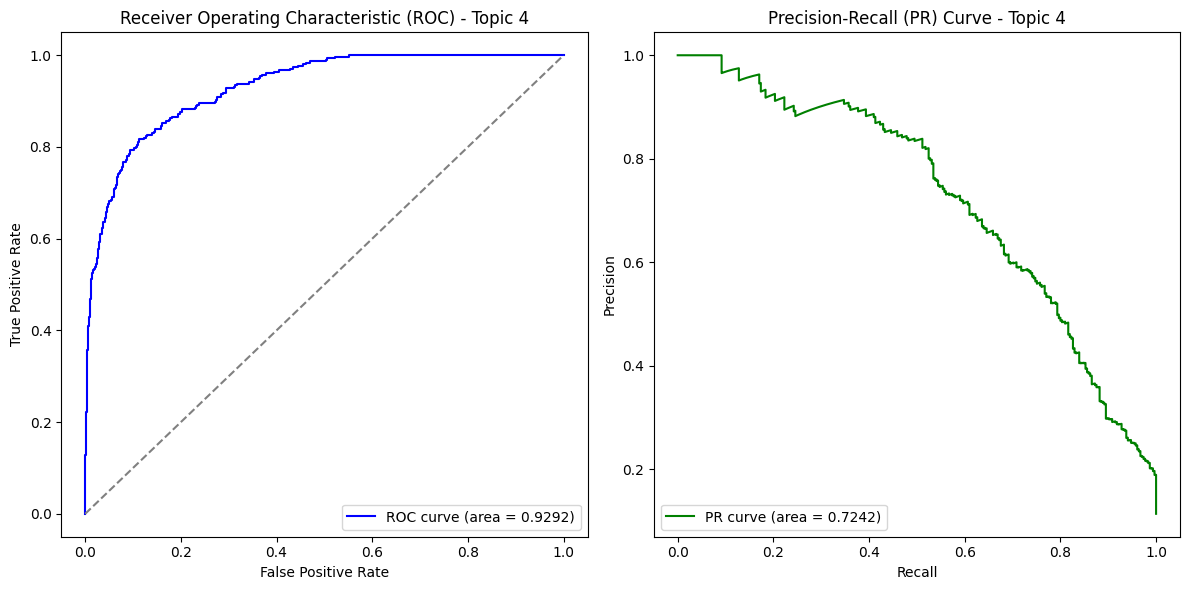

Evaluating topic 5
Topic 5 - auROC: 0.7535, auPR: 0.2640, F1: 0.1022


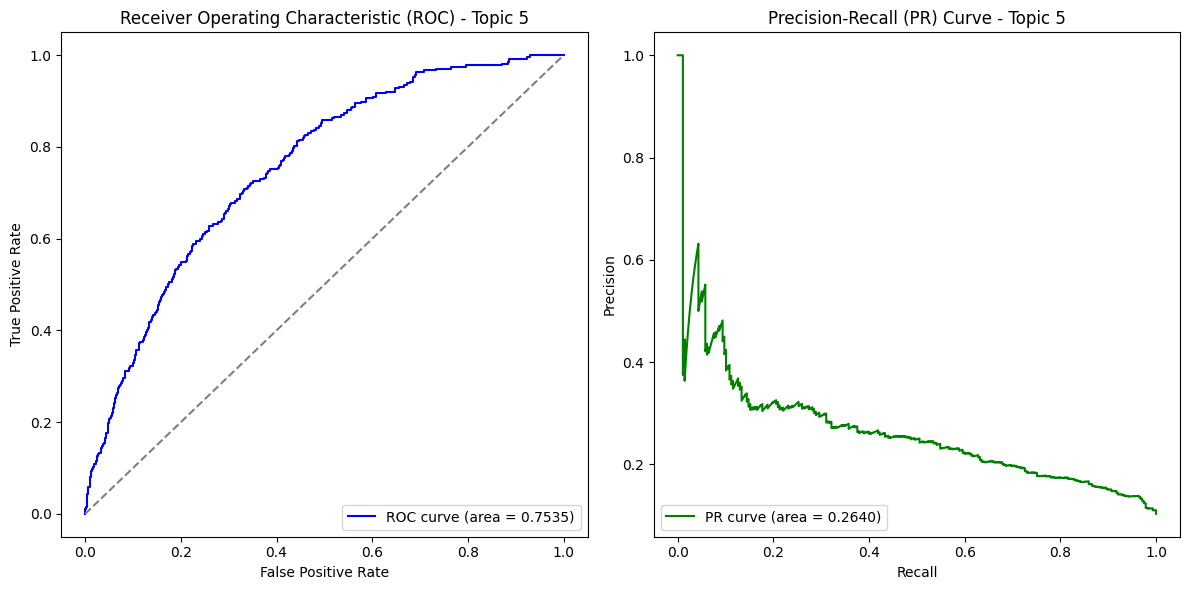

Evaluating topic 6
Topic 6 - auROC: 0.8534, auPR: 0.4151, F1: 0.4632


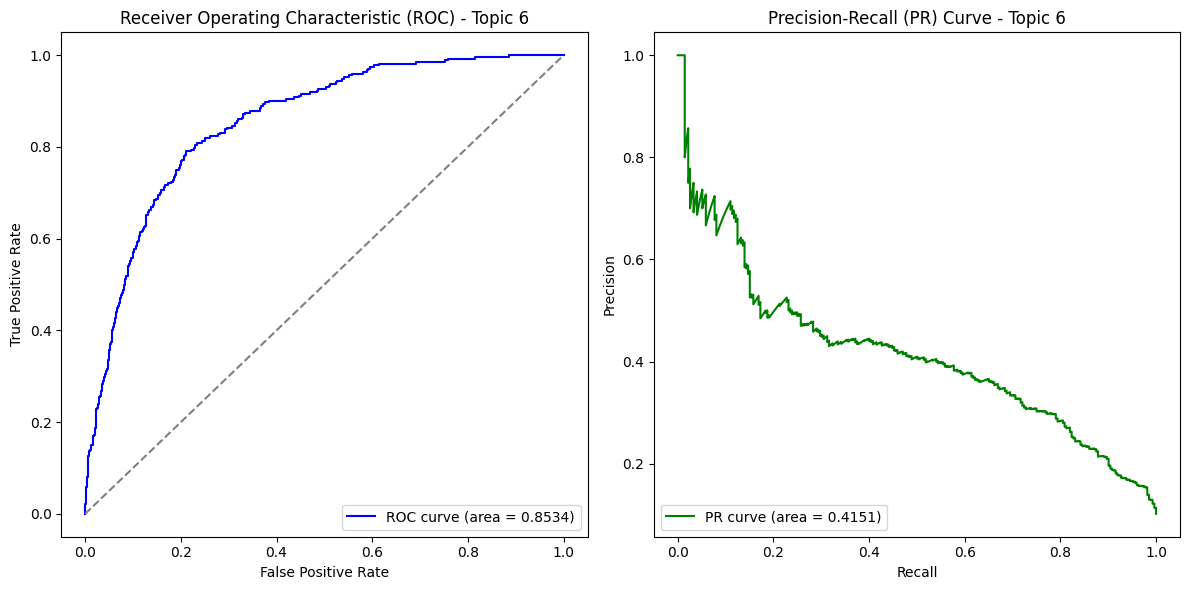

Evaluating topic 7
Topic 7 - auROC: 0.8098, auPR: 0.2961, F1: 0.3536


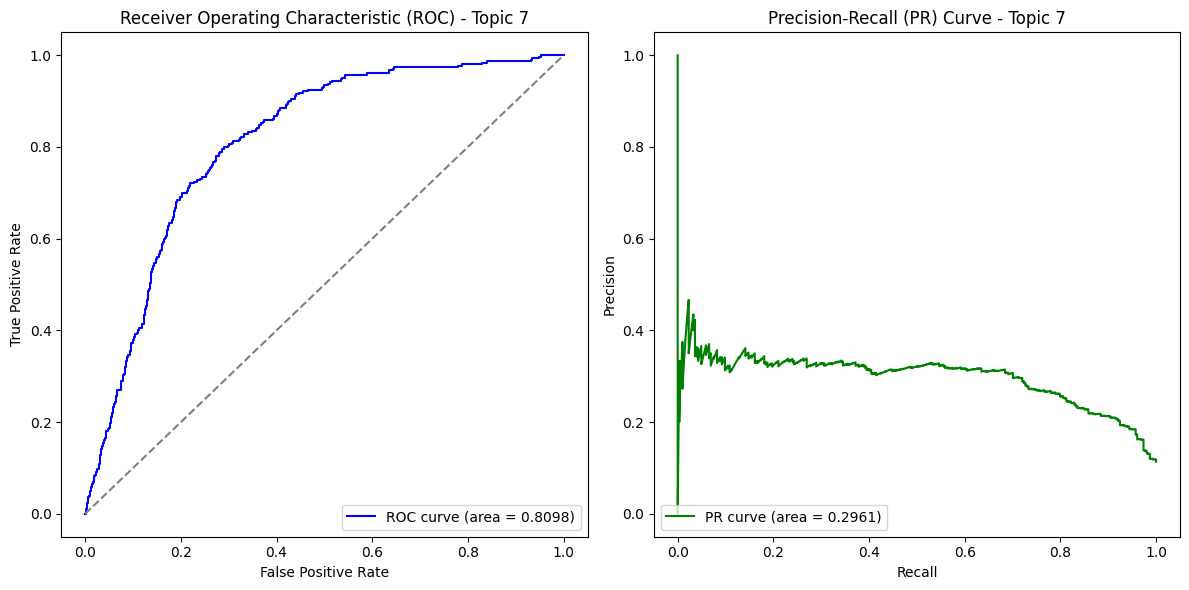

Evaluating topic 8
Topic 8 - auROC: 0.8925, auPR: 0.5826, F1: 0.5690


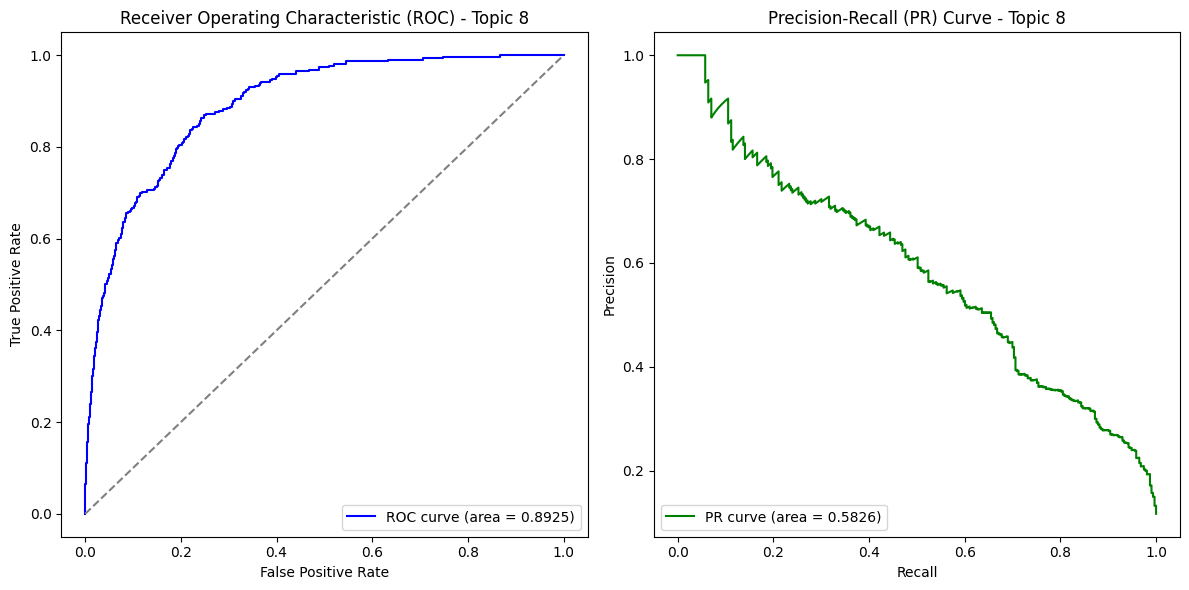

Evaluating topic 9
Topic 9 - auROC: 0.8656, auPR: 0.4991, F1: 0.4508


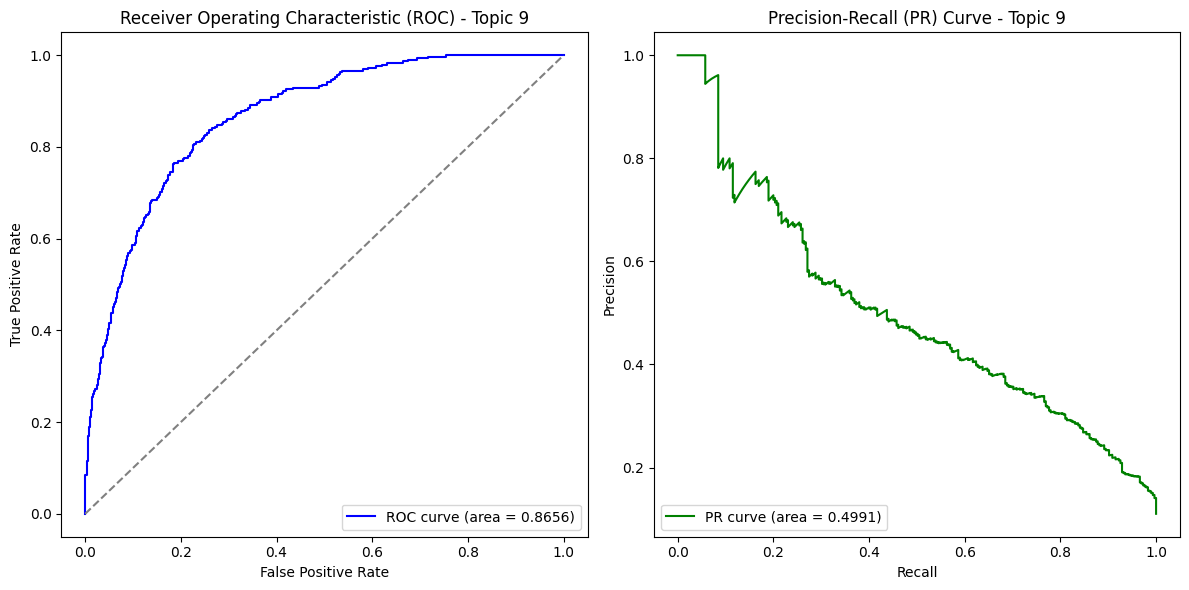

Evaluating topic 10
Topic 10 - auROC: 0.8492, auPR: 0.4270, F1: 0.4635


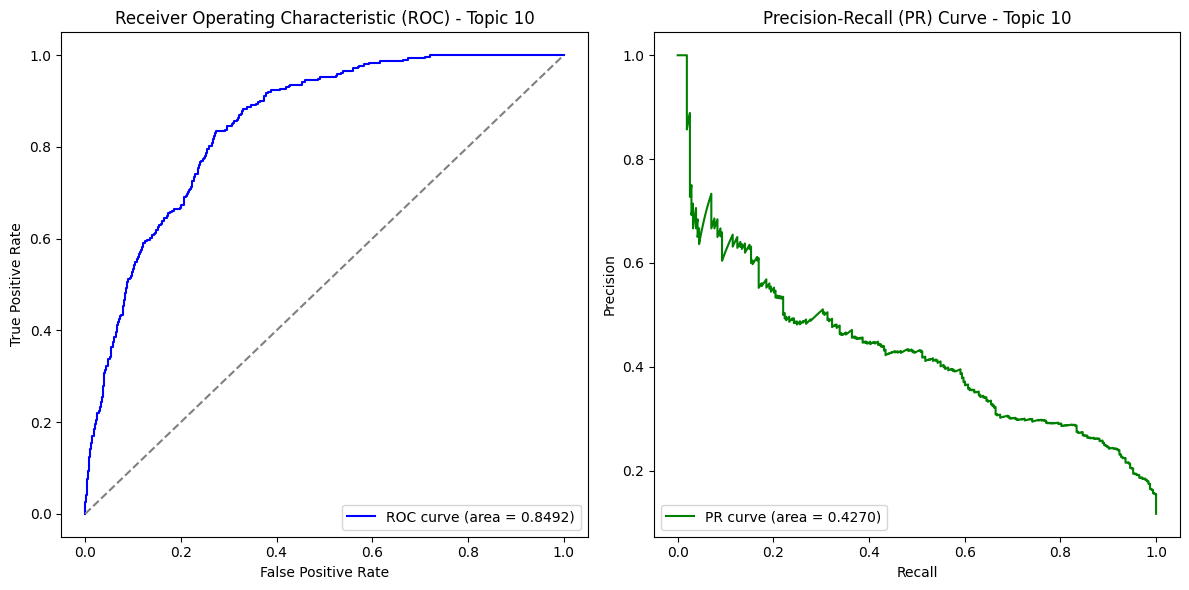

Evaluating topic 11
Topic 11 - auROC: 0.8637, auPR: 0.4811, F1: 0.4763


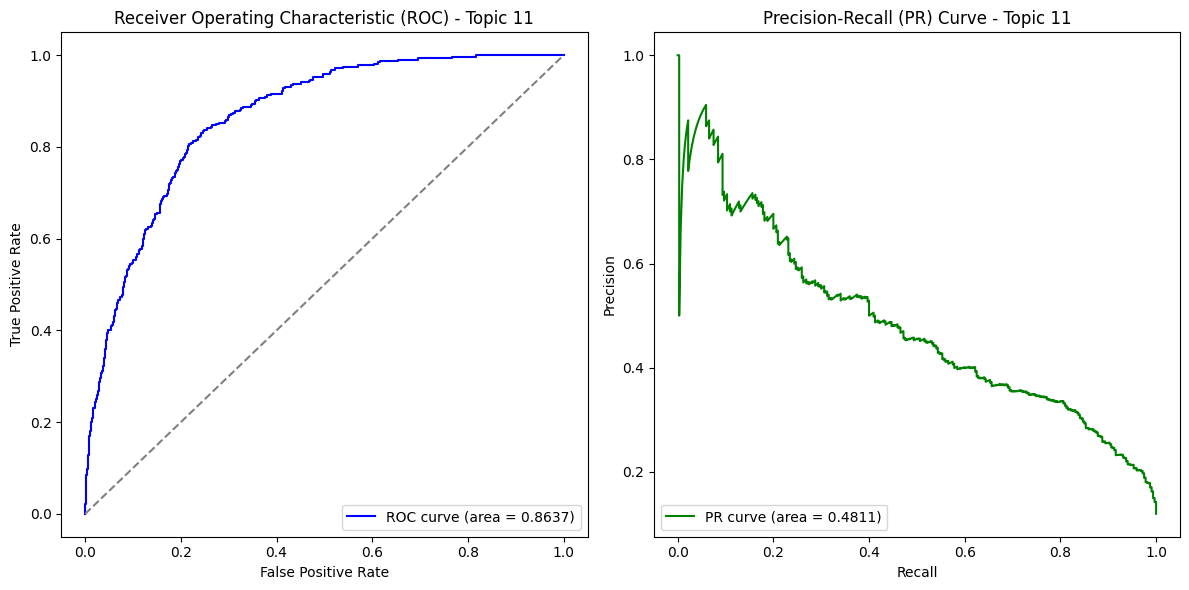

In [26]:
# Evaluate model performance for each topic
num_topics = y_test_np.shape[1]
auroc_values = []
aupr_values = []
f1_scores = []

print(f"\nEvaluating {num_topics} topics...")

for topic_idx in range(num_topics):
    print(f'Evaluating topic {topic_idx+1}')
    
    # Calculate ROC and PR metrics for the current topic
    fpr, tpr, _ = roc_curve(y_test_np[:, topic_idx], y_pred_np[:, topic_idx])
    roc_auc = auc(fpr, tpr)
    auroc_values.append(roc_auc)
    
    precision, recall, _ = precision_recall_curve(y_test_np[:, topic_idx], y_pred_np[:, topic_idx])
    pr_auc = auc(recall, precision)
    aupr_values.append(pr_auc)

    # Binarize predictions for F1 score calculation
    y_pred_bin = (y_pred_np[:, topic_idx] >= 0.5).astype(int)
    f1 = f1_score(y_test_np[:, topic_idx], y_pred_bin)
    f1_scores.append(f1)
    
    print(f'Topic {topic_idx+1} - auROC: {roc_auc:.4f}, auPR: {pr_auc:.4f}, F1: {f1:.4f}')
    
    # Plot ROC and PR curves for the current topic
    plt.figure(figsize=(12, 6))
    
    # ROC Curve
    plt.subplot(1, 2, 1)
    plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Receiver Operating Characteristic (ROC) - Topic {topic_idx+1}')
    plt.legend(loc='lower right')
    
    # PR Curve
    plt.subplot(1, 2, 2)
    plt.plot(recall, precision, color='green', label=f'PR curve (area = {pr_auc:.4f})')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall (PR) Curve - Topic {topic_idx+1}')
    plt.legend(loc='lower left')
    
    plt.tight_layout()
    plt.show()

In [27]:
# Summary statistics
print(f"\nSummary Statistics:")
print(f"Mean auROC: {np.mean(auroc_values):.4f} ± {np.std(auroc_values):.4f}")
print(f"Mean auPR: {np.mean(aupr_values):.4f} ± {np.std(aupr_values):.4f}")
print(f"Mean F1: {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")
print(f"Exact Match Accuracy: {exact_acc:.4f}")
print(f"Accuracy: {hamming_acc:.4f}")


Summary Statistics:
Mean auROC: 0.8517 ± 0.0527
Mean auPR: 0.4731 ± 0.1551
Mean F1: 0.4373 ± 0.1410
Exact Match Accuracy: 0.2890
Accuracy: 0.8525


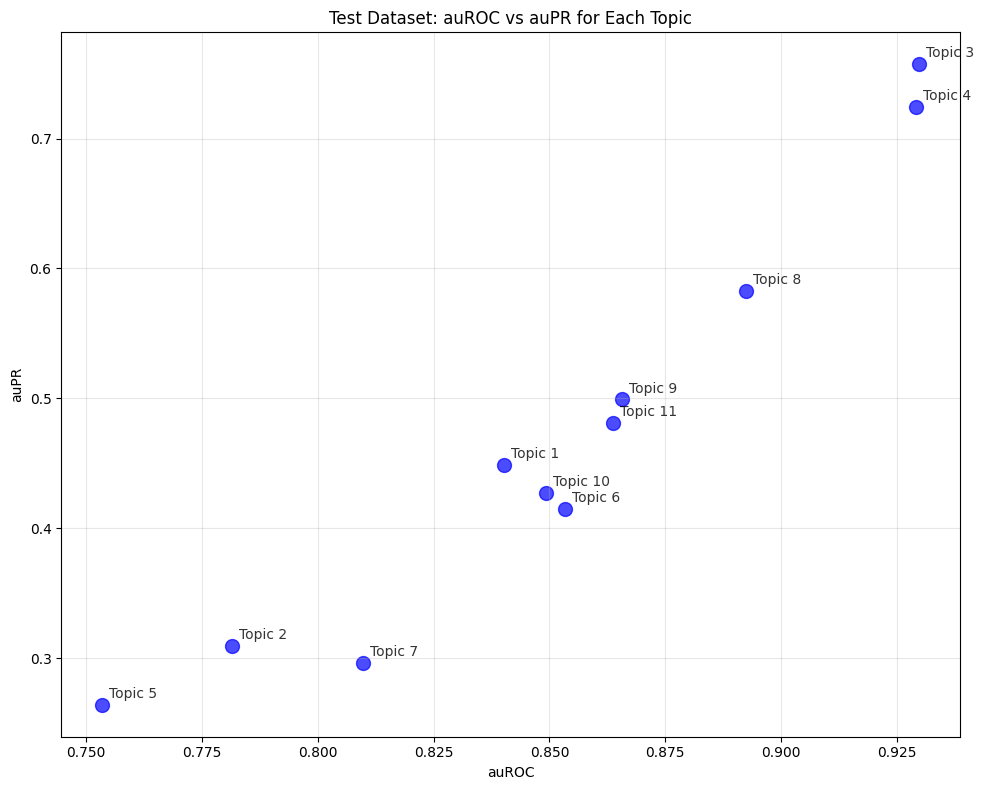

In [28]:
# Scatter plot of auROC vs auPR
plt.figure(figsize=(10, 8))
plt.scatter(auroc_values, aupr_values, color='blue', alpha=0.7, s=100, )
plt.xlabel('auROC')
plt.ylabel('auPR')
plt.title(eval_dataset + ': auROC vs auPR for Each Topic')
plt.grid(True, alpha=0.3)

# Annotate each point with the topic index
for i, (x, y) in enumerate(zip(auroc_values, aupr_values)):
    plt.annotate(f'Topic {i+1}', (x, y), fontsize=10, alpha=0.8, 
                xytext=(5, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## Evaluate model on full dataset

In [34]:
eval_dataset = 'Full Dataset'

In [35]:
# Evaluate model on full dataset
dataset = full_dataset
dataloader = full_dataloader

model.eval()

loss, correct = 0, 0
all_test_probs = []
all_test_targets = []

with torch.no_grad():
    for batch in dataloader:
        X, y = batch['sequence'], batch['label']
        X, y = X.to(device), y.to(device)
        y = y.float()
        
        pred = model(X)
        prob = torch.sigmoid(pred)
        # loss += loss_fn(pred, y).item()
        
        all_test_probs.append(prob)
        all_test_targets.append(y)
        
        # Exact match accuracy
        pred_binary = (prob > 0.5).float()
        exact_match = ((pred_binary == y).sum(dim=1) == y.shape[1]).float().sum().item()
        correct += exact_match

all_test_probs = torch.cat(all_test_probs, dim=0)
all_test_targets = torch.cat(all_test_targets, dim=0)

# loss /= len(dataloader)
exact_acc = correct / len(dataset)

pred_binary = (all_test_probs > 0.5).float()
hamming_acc = (pred_binary == all_test_targets).float().mean().item()

In [36]:
# Convert PyTorch tensors to numpy for sklearn
y_pred_np = all_test_probs.cpu().numpy()
y_test_np = all_test_targets.cpu().numpy()

print("Prediction min/max:", np.min(y_pred_np), np.max(y_pred_np))
print("Prediction shape:", y_pred_np.shape)
print("Target shape:", y_test_np.shape)

Prediction min/max: 3.1624683e-07 0.9999447
Prediction shape: (39757, 16)
Target shape: (39757, 16)


In [37]:
from utils.evaluate import evaluate_multilabel_model, calculate_overall_metrics, analyze_topic_difficulty, plot_per_topic_metrics, optimize_thresholds_per_topic

PER-TOPIC EVALUATION RESULTS
Topic        Precision  Recall   F1       AUROC    AUPR     Support  Preds 
--------------------------------------------------------------------------------
Topic_1      0.623      0.809    0.704    0.965    0.796    3000.0   3895  
Topic_2      0.411      0.810    0.545    0.940    0.665    3000.0   5906  
Topic_3      0.676      0.831    0.745    0.977    0.808    3000.0   3690  
Topic_4      0.588      0.388    0.467    0.901    0.517    3000.0   1979  
Topic_5      0.461      0.377    0.415    0.879    0.408    3000.0   2450  
Topic_6      0.321      0.798    0.457    0.910    0.547    3000.0   7470  
Topic_7      0.274      0.649    0.385    0.857    0.343    3000.0   7110  
Topic_8      0.465      0.594    0.522    0.920    0.526    3000.0   3836  
Topic_9      0.477      0.688    0.564    0.938    0.594    3000.0   4325  
Topic_10     0.492      0.120    0.193    0.786    0.264    3000.0   734   
Topic_11     0.355      0.649    0.459    0.895    0.4

/home/ray/miniforge3/envs/deepmsn/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/ray/miniforge3/envs/deepmsn/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


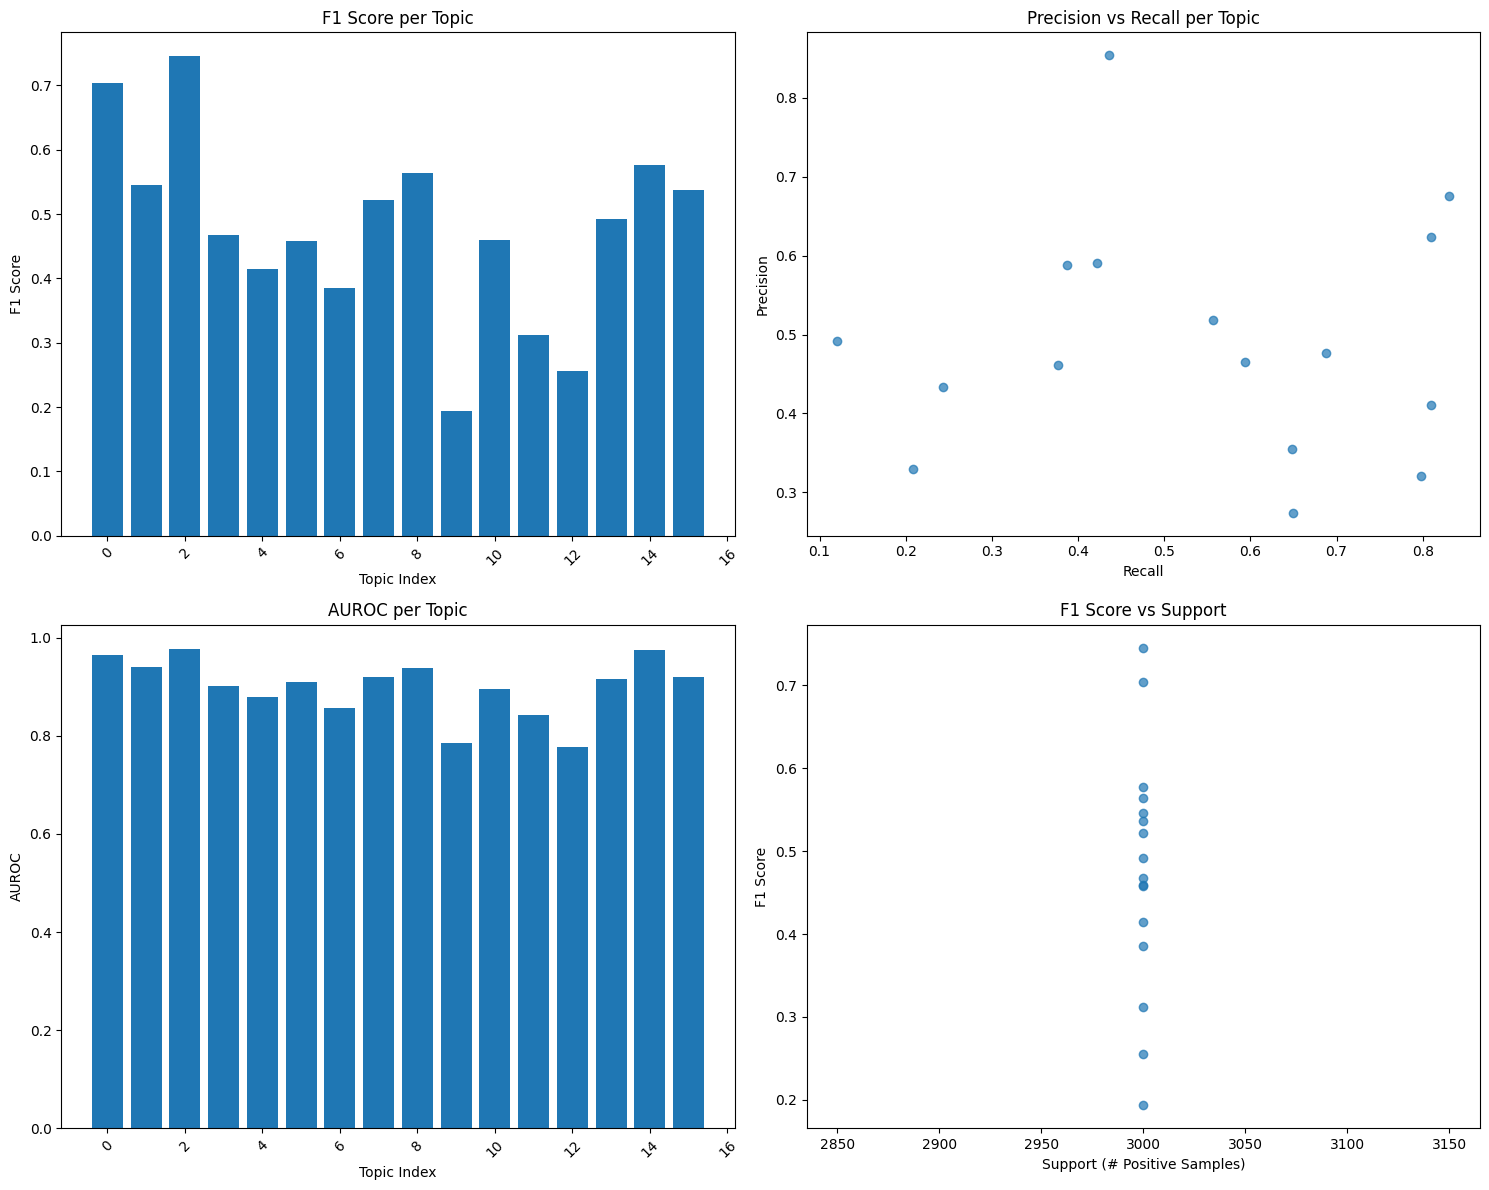


THRESHOLD OPTIMIZATION PER TOPIC
Topic    Best Thresh  Best F1    Precision  Recall  
------------------------------------------------------------
Topic_1   0.70         0.731      0.739      0.723   
Topic_2   0.85         0.623      0.615      0.631   
Topic_3   0.55         0.748      0.704      0.798   
Topic_4   0.40         0.502      0.497      0.507   
Topic_5   0.40         0.445      0.377      0.543   
Topic_6   0.75         0.543      0.508      0.584   
Topic_7   0.60         0.398      0.341      0.479   
Topic_8   0.50         0.522      0.465      0.594   
Topic_9   0.55         0.570      0.524      0.626   
Topic_10  0.35         0.298      0.256      0.358   
Topic_11  0.60         0.472      0.405      0.565   
Topic_12  0.35         0.387      0.336      0.457   
Topic_13  0.35         0.297      0.228      0.429   
Topic_14  0.40         0.524      0.477      0.582   
Topic_15  0.20         0.713      0.655      0.781   
Topic_16  0.50         0.537      0.518   

In [38]:
# 1. Run comprehensive evaluation
results_df = evaluate_multilabel_model(y_test_np, y_pred_np, threshold=0.5)

# 2. Calculate overall metrics
overall_metrics = calculate_overall_metrics(y_test_np, y_pred_np, threshold=0.5)

# 3. Analyze topic difficulty
sorted_results = analyze_topic_difficulty(results_df, n_top=5)

# 4. Plot performance metrics
plot_per_topic_metrics(results_df)

# 5. Optimize thresholds per topic
optimal_thresholds, optimal_f1_scores = optimize_thresholds_per_topic(y_test_np, y_pred_np)

# 6. Save results to CSV
# results_df.to_csv(f'{checkpoint_path}/per_topic_evaluation.csv', index=False)
# print(f"\nResults saved to '{checkpoint_path}/per_topic_evaluation.csv'")

In [39]:
# Apply optimal thresholds for confusion matrices
print("\nConfusion matrices for each topic (with optimal thresholds):")
for i in range(y_test_np.shape[1]):
    # Use the optimal threshold for this specific topic
    optimal_thresh = optimal_thresholds[i]
    y_pred_binary = (y_pred_np[:, i] > optimal_thresh).astype(int)
    
    print(f"\nTopic {i+1} (threshold: {optimal_thresh:.2f}):")
    cm = confusion_matrix(y_test_np[:, i], y_pred_binary)
    print(cm)
    
    # Optional: Calculate and display metrics for this topic
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    print(f"  Precision: {precision:.3f}, Recall: {recall:.3f}, F1: {f1:.3f}")
    print(f"  TP: {tp}, FP: {fp}, FN: {fn}, TN: {tn}")


Confusion matrices for each topic (with optimal thresholds):

Topic 1 (threshold: 0.70):
[[35992   765]
 [  831  2169]]
  Precision: 0.739, Recall: 0.723, F1: 0.731
  TP: 2169, FP: 765, FN: 831, TN: 35992

Topic 2 (threshold: 0.85):
[[35574  1183]
 [ 1107  1893]]
  Precision: 0.615, Recall: 0.631, F1: 0.623
  TP: 1893, FP: 1183, FN: 1107, TN: 35574

Topic 3 (threshold: 0.55):
[[35751  1006]
 [  606  2394]]
  Precision: 0.704, Recall: 0.798, F1: 0.748
  TP: 2394, FP: 1006, FN: 606, TN: 35751

Topic 4 (threshold: 0.40):
[[35219  1538]
 [ 1478  1522]]
  Precision: 0.497, Recall: 0.507, F1: 0.502
  TP: 1522, FP: 1538, FN: 1478, TN: 35219

Topic 5 (threshold: 0.40):
[[34068  2689]
 [ 1370  1630]]
  Precision: 0.377, Recall: 0.543, F1: 0.445
  TP: 1630, FP: 2689, FN: 1370, TN: 34068

Topic 6 (threshold: 0.75):
[[35061  1696]
 [ 1249  1751]]
  Precision: 0.508, Recall: 0.584, F1: 0.543
  TP: 1751, FP: 1696, FN: 1249, TN: 35061

Topic 7 (threshold: 0.60):
[[33977  2780]
 [ 1562  1438]]
  Prec


Evaluating 16 topics...
Evaluating topic 1
Topic 1 - auROC: 0.9650, auPR: 0.7964, F1: 0.7043


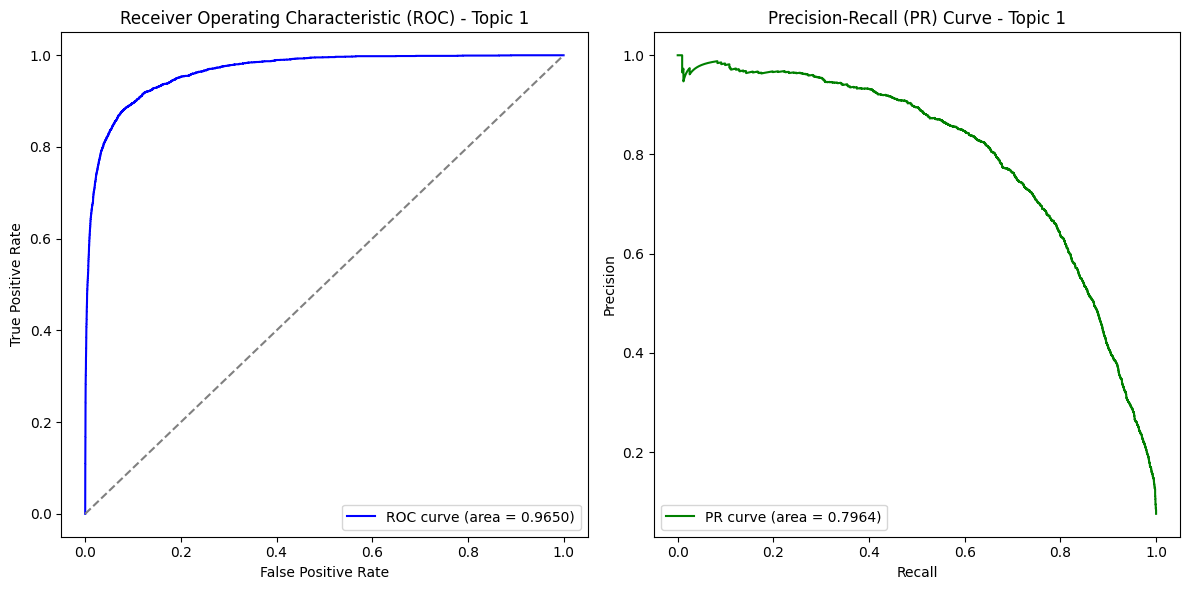

Evaluating topic 2
Topic 2 - auROC: 0.9402, auPR: 0.6645, F1: 0.5455


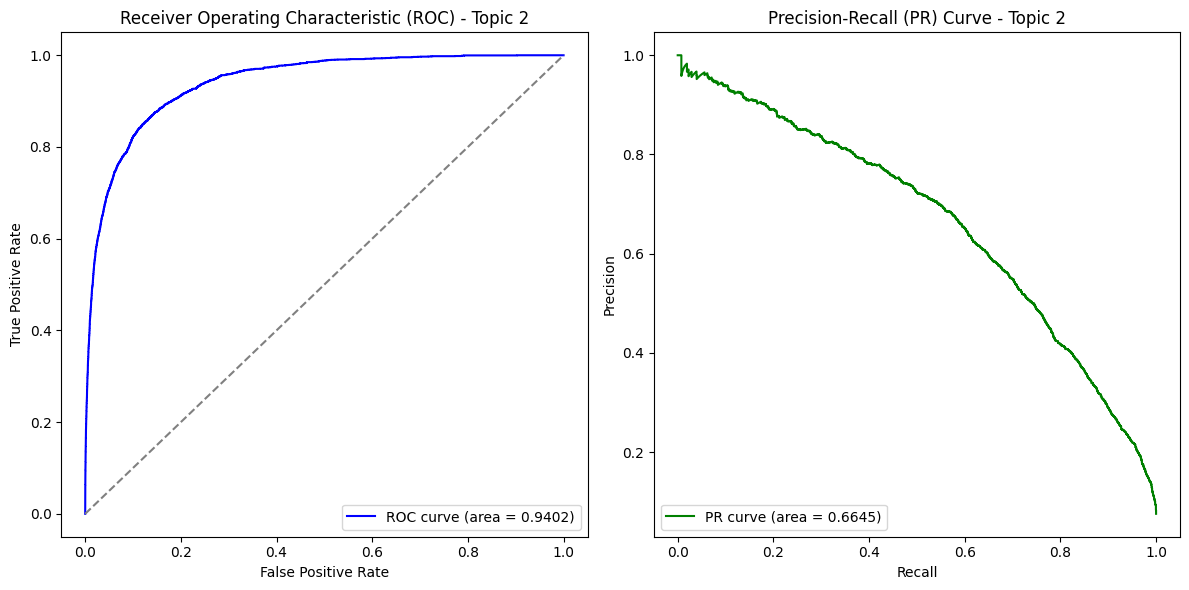

Evaluating topic 3
Topic 3 - auROC: 0.9774, auPR: 0.8084, F1: 0.7453


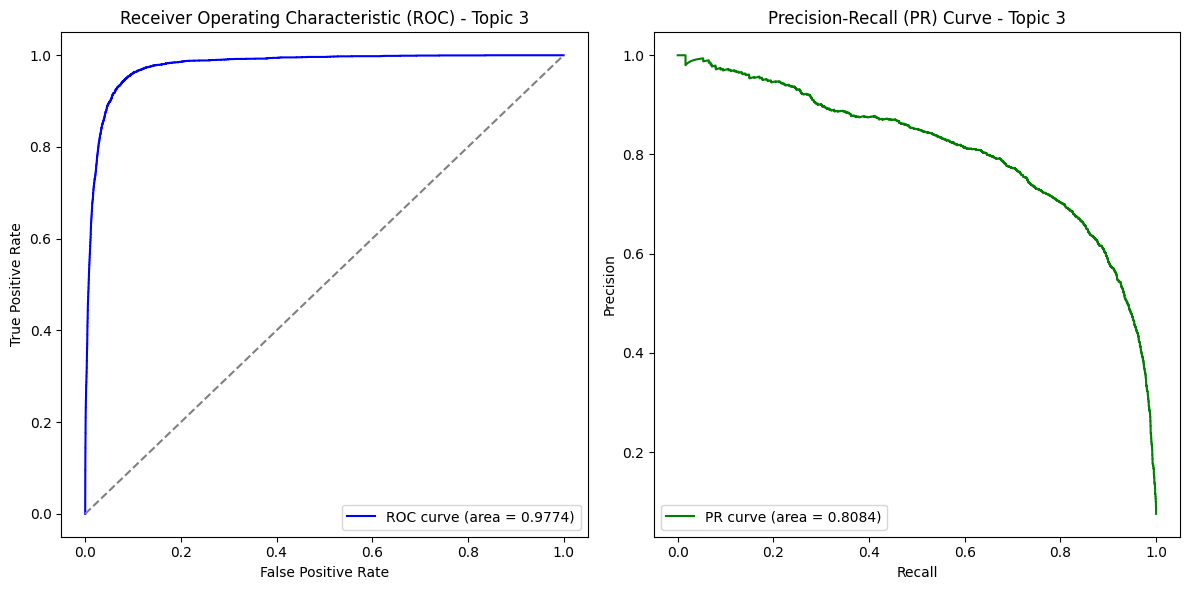

Evaluating topic 4
Topic 4 - auROC: 0.9009, auPR: 0.5174, F1: 0.4672


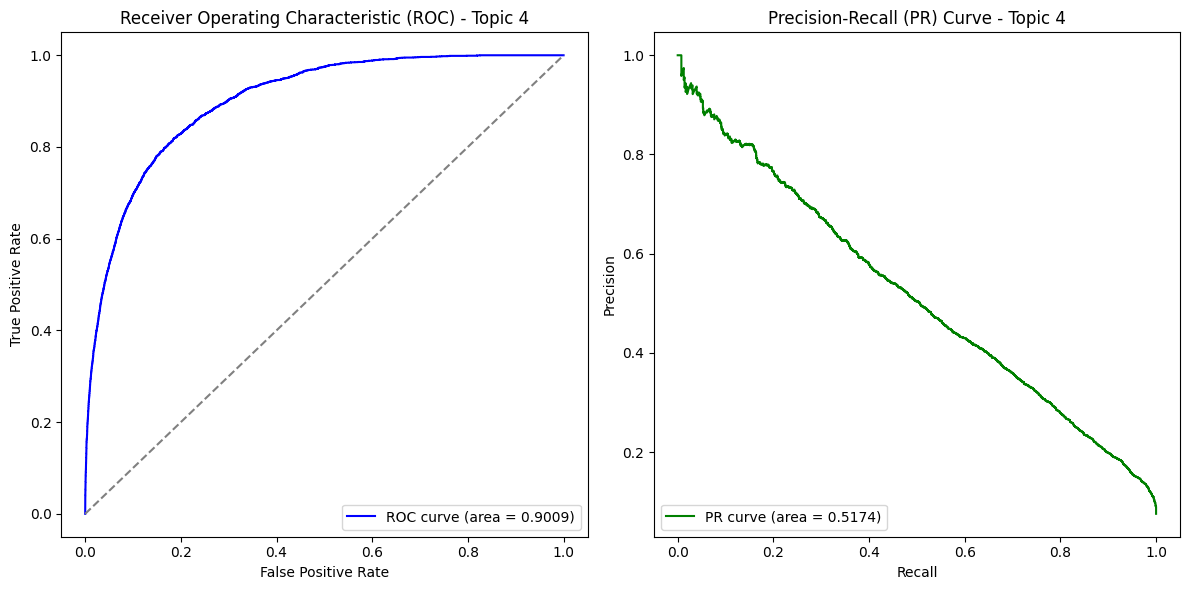

Evaluating topic 5
Topic 5 - auROC: 0.8790, auPR: 0.4077, F1: 0.4147


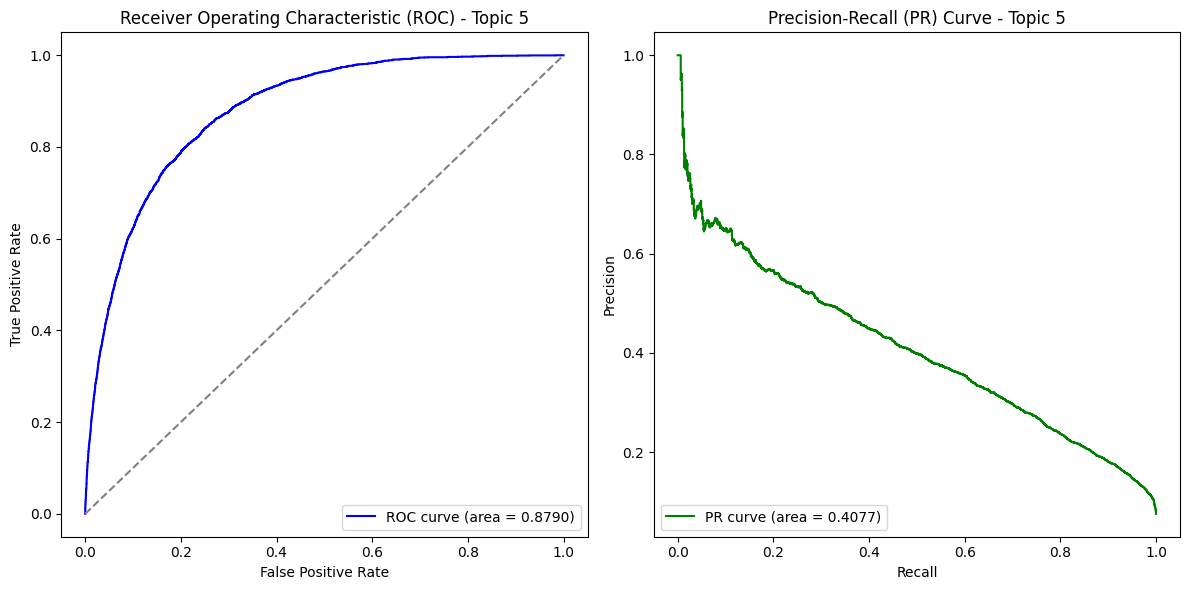

Evaluating topic 6
Topic 6 - auROC: 0.9103, auPR: 0.5473, F1: 0.4575


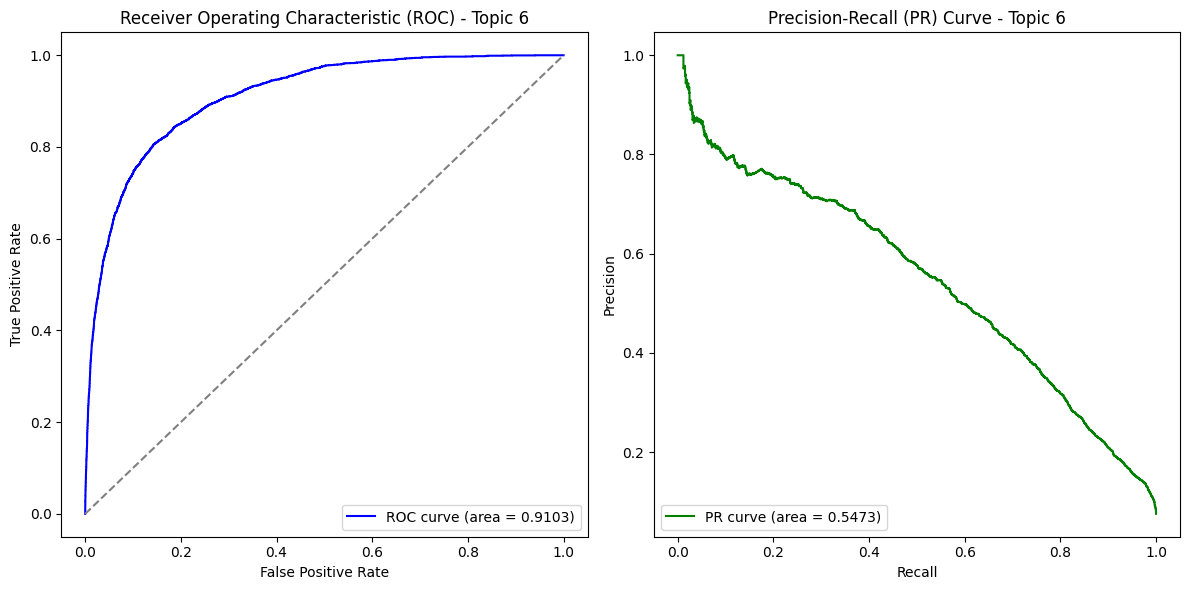

Evaluating topic 7
Topic 7 - auROC: 0.8574, auPR: 0.3432, F1: 0.3852


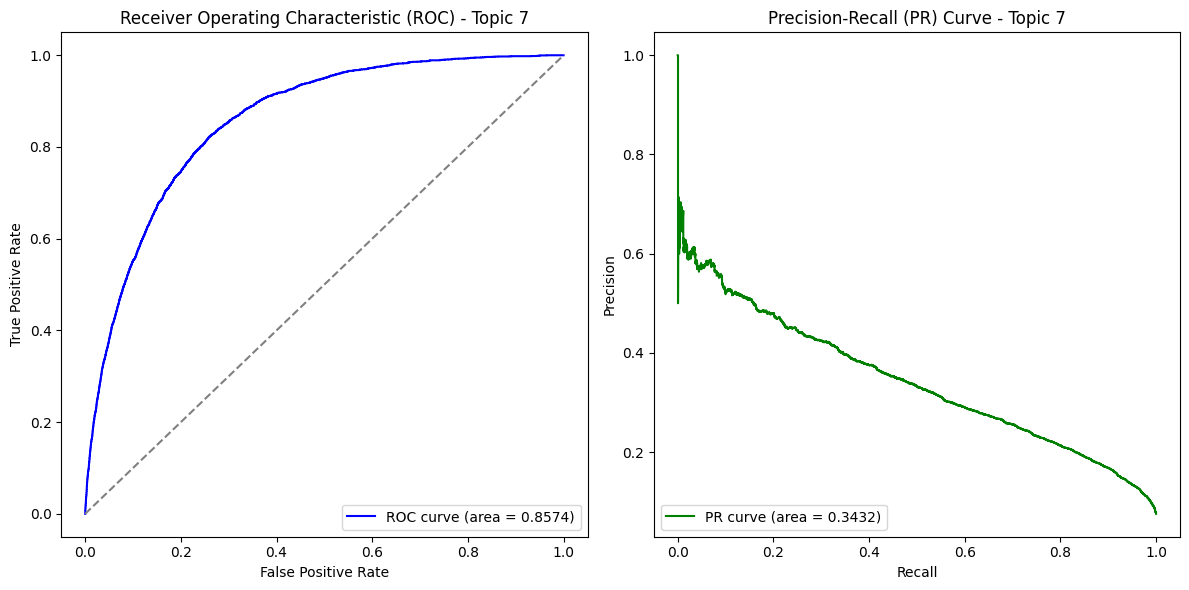

Evaluating topic 8
Topic 8 - auROC: 0.9205, auPR: 0.5257, F1: 0.5217


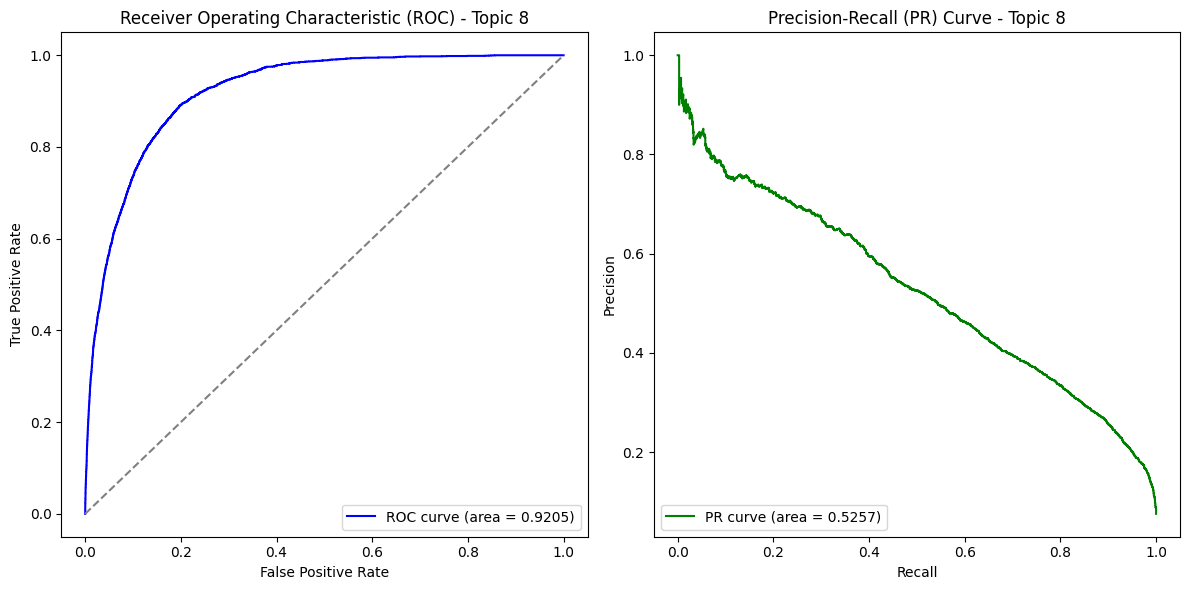

Evaluating topic 9
Topic 9 - auROC: 0.9376, auPR: 0.5942, F1: 0.5635


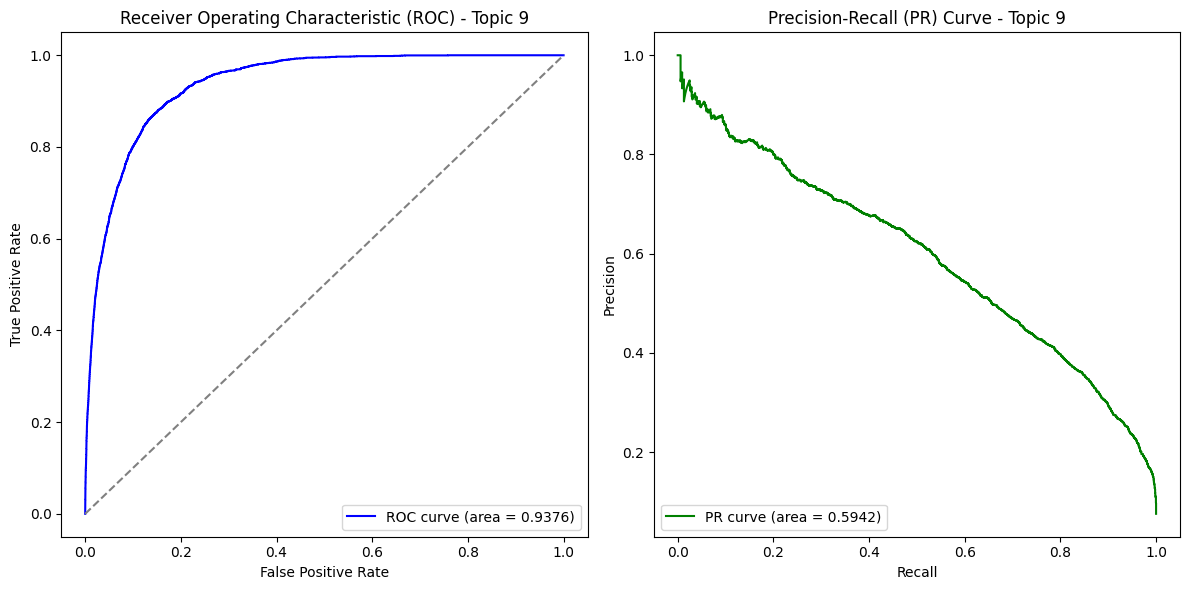

Evaluating topic 10
Topic 10 - auROC: 0.7861, auPR: 0.2633, F1: 0.1934


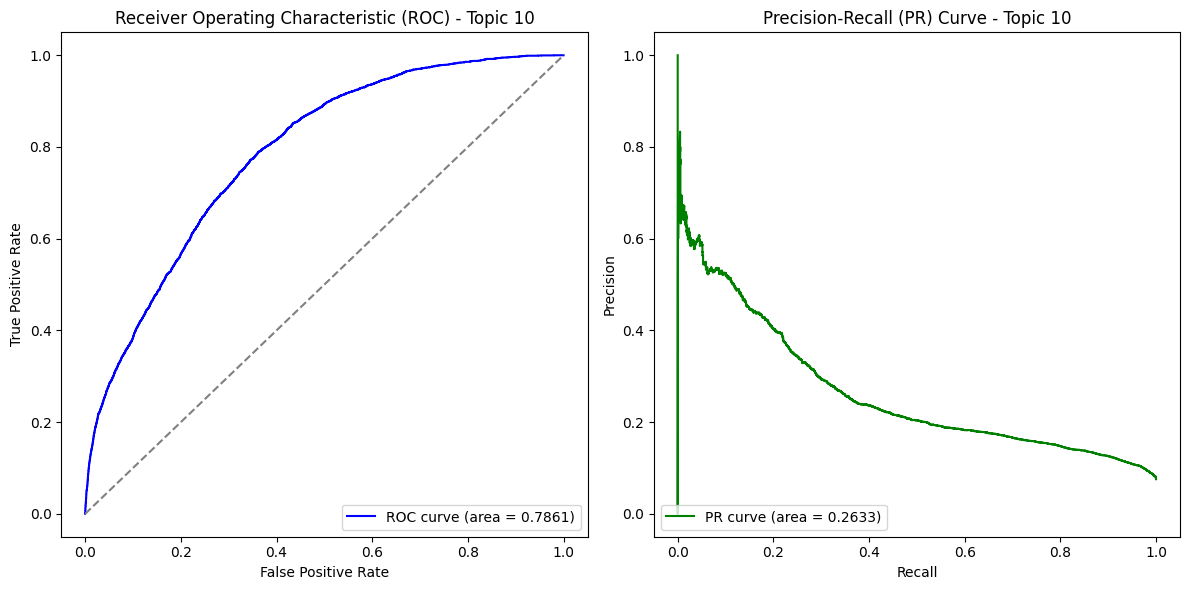

Evaluating topic 11
Topic 11 - auROC: 0.8948, auPR: 0.4702, F1: 0.4592


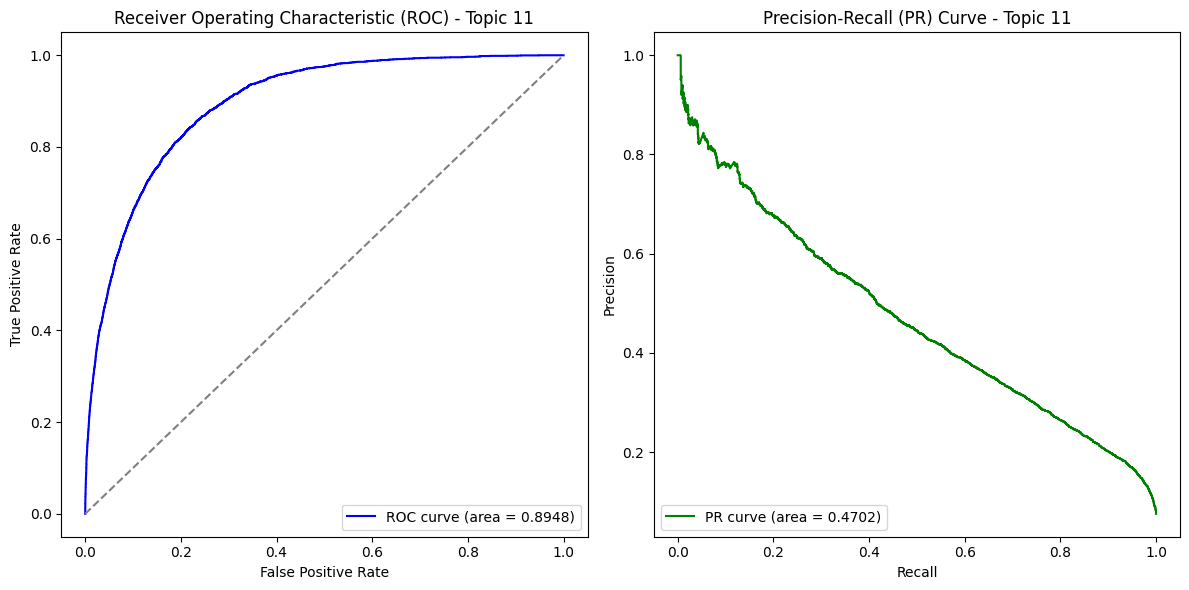

Evaluating topic 12
Topic 12 - auROC: 0.8426, auPR: 0.3401, F1: 0.3119


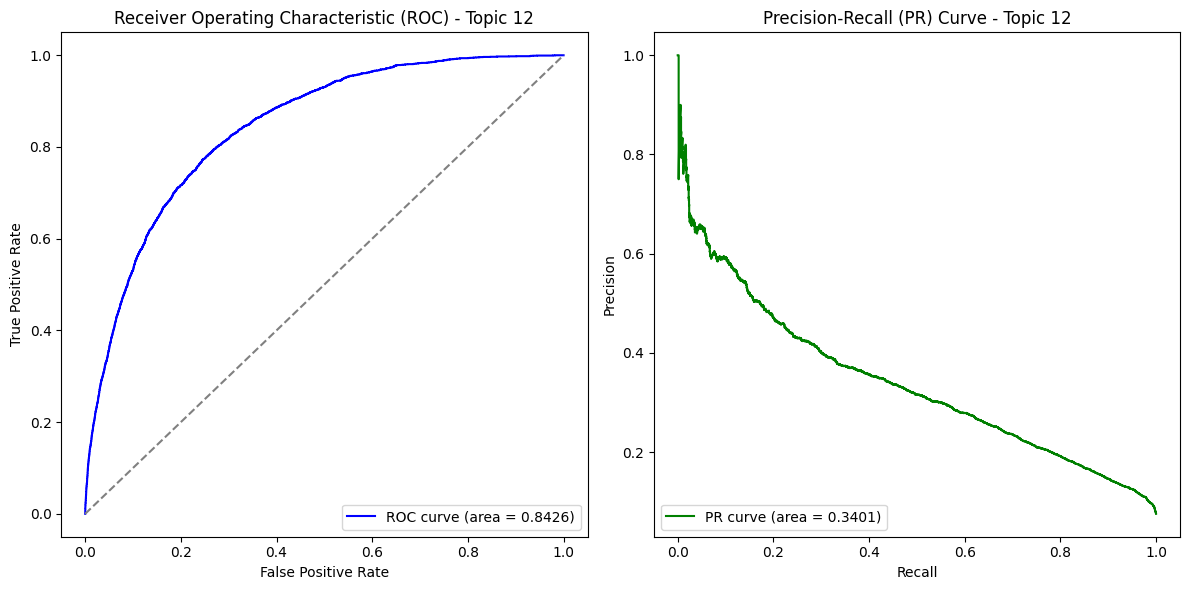

Evaluating topic 13
Topic 13 - auROC: 0.7782, auPR: 0.2296, F1: 0.2555


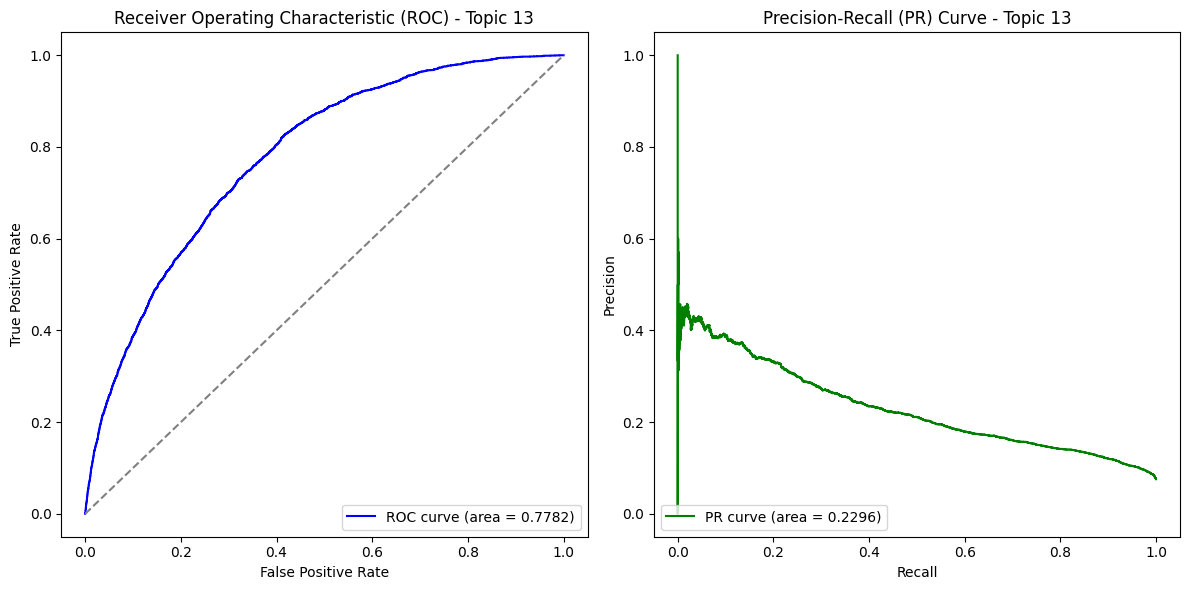

Evaluating topic 14
Topic 14 - auROC: 0.9165, auPR: 0.5242, F1: 0.4920


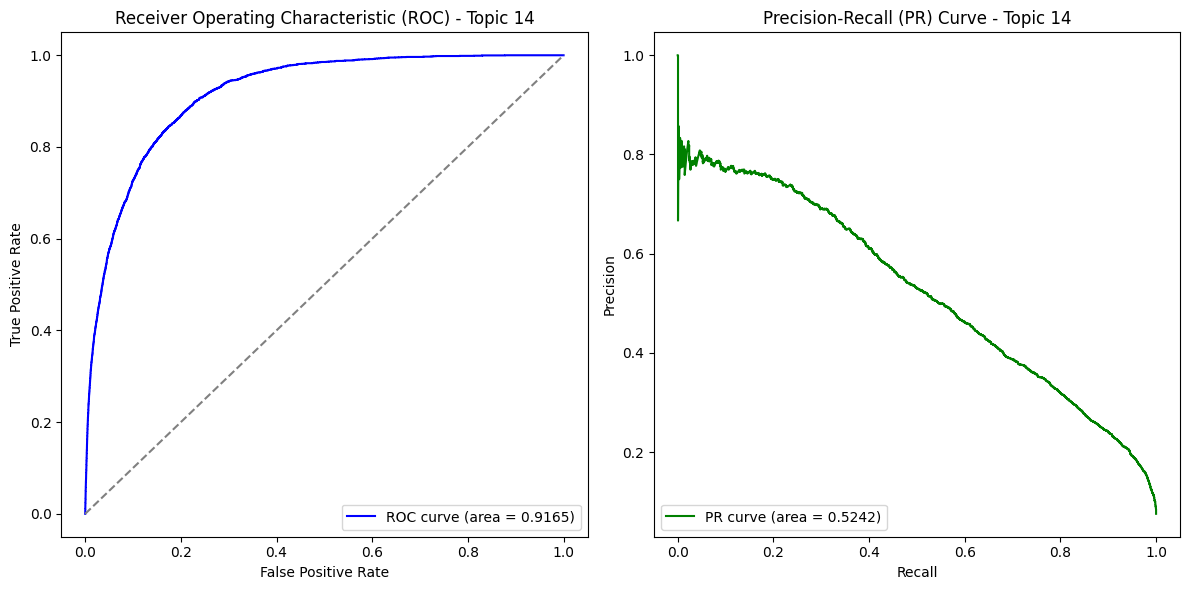

Evaluating topic 15
Topic 15 - auROC: 0.9749, auPR: 0.7791, F1: 0.5770


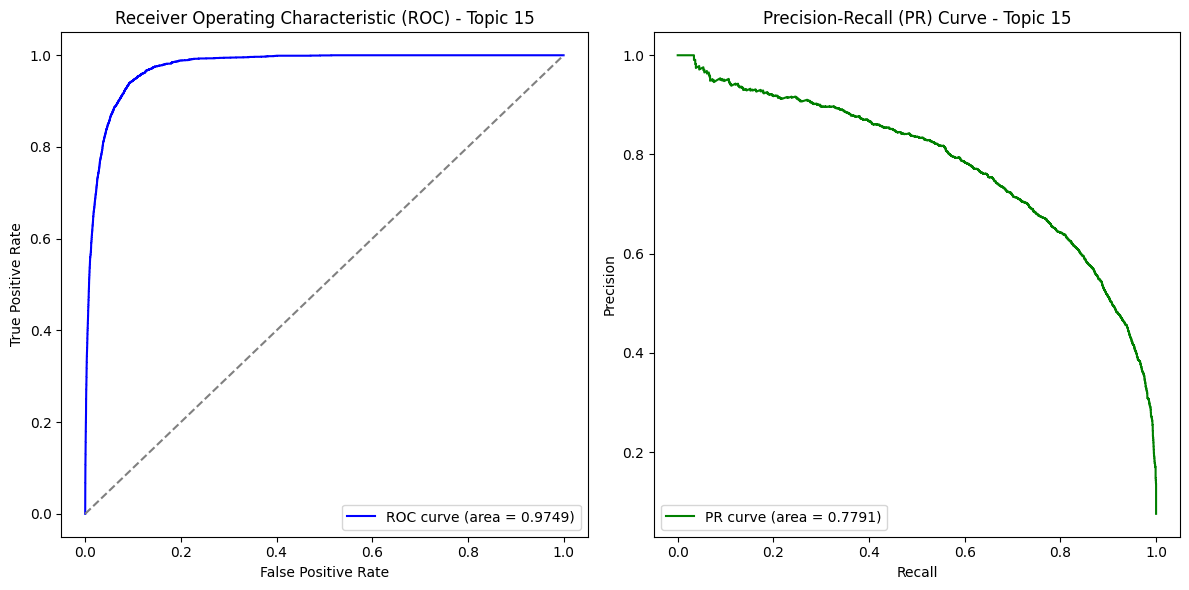

Evaluating topic 16
Topic 16 - auROC: 0.9195, auPR: 0.5569, F1: 0.5367


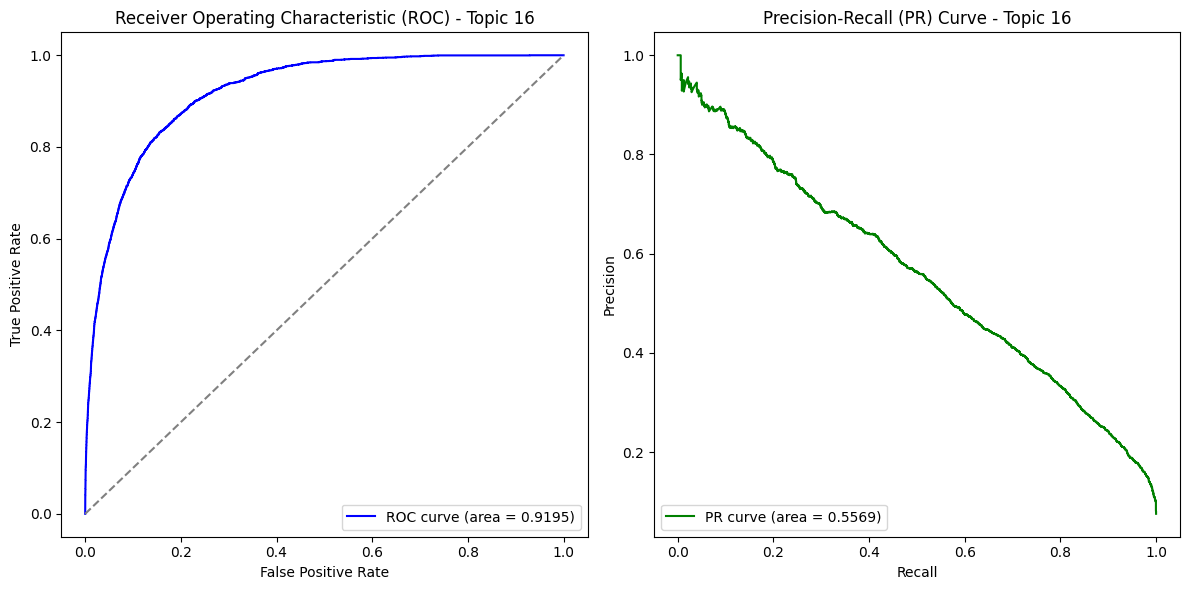

In [40]:
# Evaluate model performance for each topic
num_topics = y_test_np.shape[1]
auroc_values = []
aupr_values = []
f1_scores = []

print(f"\nEvaluating {num_topics} topics...")

for topic_idx in range(num_topics):
    print(f'Evaluating topic {topic_idx+1}')
    
    # Calculate ROC and PR metrics for the current topic
    fpr, tpr, _ = roc_curve(y_test_np[:, topic_idx], y_pred_np[:, topic_idx])
    roc_auc = auc(fpr, tpr)
    auroc_values.append(roc_auc)
    
    precision, recall, _ = precision_recall_curve(y_test_np[:, topic_idx], y_pred_np[:, topic_idx])
    pr_auc = auc(recall, precision)
    aupr_values.append(pr_auc)

    # Binarize predictions for F1 score calculation
    y_pred_bin = (y_pred_np[:, topic_idx] >= 0.5).astype(int)
    f1 = f1_score(y_test_np[:, topic_idx], y_pred_bin)
    f1_scores.append(f1)
    
    print(f'Topic {topic_idx+1} - auROC: {roc_auc:.4f}, auPR: {pr_auc:.4f}, F1: {f1:.4f}')
    
    # Plot ROC and PR curves for the current topic
    plt.figure(figsize=(12, 6))
    
    # ROC Curve
    plt.subplot(1, 2, 1)
    plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Receiver Operating Characteristic (ROC) - Topic {topic_idx+1}')
    plt.legend(loc='lower right')
    
    # PR Curve
    plt.subplot(1, 2, 2)
    plt.plot(recall, precision, color='green', label=f'PR curve (area = {pr_auc:.4f})')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall (PR) Curve - Topic {topic_idx+1}')
    plt.legend(loc='lower left')
    
    plt.tight_layout()
    plt.show()

In [41]:
# Summary statistics
print(f"\nSummary Statistics:")
print(f"Mean auROC: {np.mean(auroc_values):.4f} ± {np.std(auroc_values):.4f}")
print(f"Mean auPR: {np.mean(aupr_values):.4f} ± {np.std(aupr_values):.4f}")
print(f"Mean F1: {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")
print(f"Exact Match Accuracy: {exact_acc:.4f}")
print(f"Accuracy: {hamming_acc:.4f}")


Summary Statistics:
Mean auROC: 0.9001 ± 0.0578
Mean auPR: 0.5230 ± 0.1739
Mean F1: 0.4769 ± 0.1417
Exact Match Accuracy: 0.2708
Accuracy: 0.9153


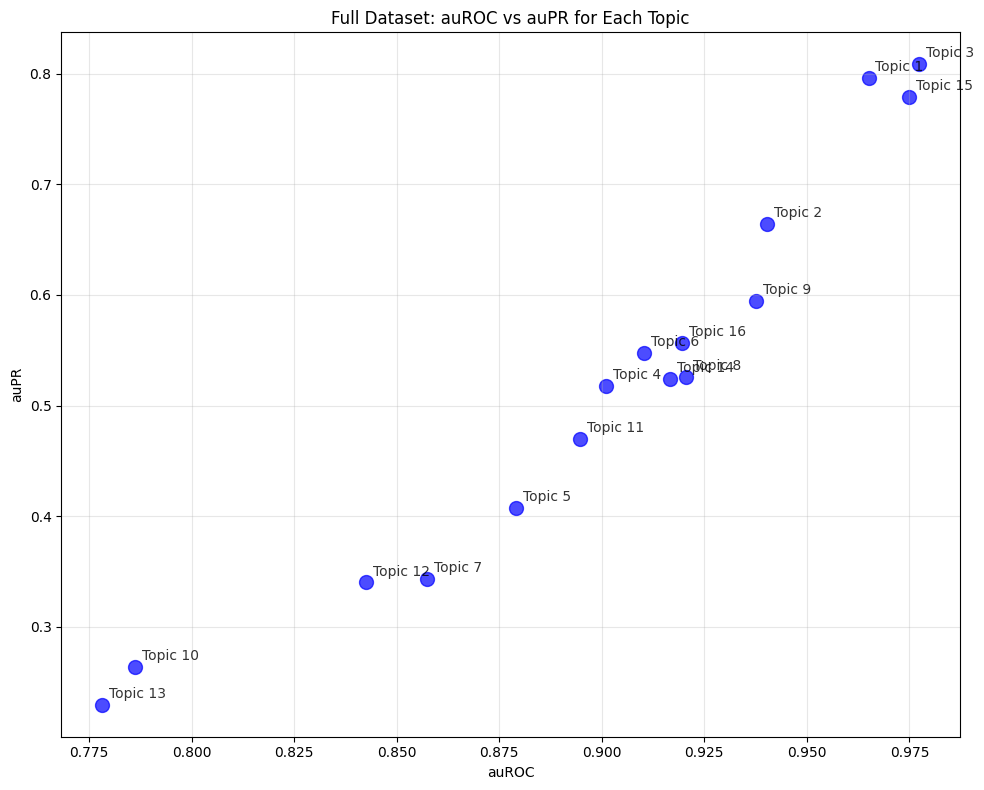

In [42]:
# Scatter plot of auROC vs auPR
plt.figure(figsize=(10, 8))
plt.scatter(auroc_values, aupr_values, color='blue', alpha=0.7, s=100, )
plt.xlabel('auROC')
plt.ylabel('auPR')
plt.title(eval_dataset + ': auROC vs auPR for Each Topic')
plt.grid(True, alpha=0.3)

# Annotate each point with the topic index
for i, (x, y) in enumerate(zip(auroc_values, aupr_values)):
    plt.annotate(f'Topic {i+1}', (x, y), fontsize=10, alpha=0.8, 
                xytext=(5, 5), textcoords='offset points')

plt.tight_layout()
plt.show()